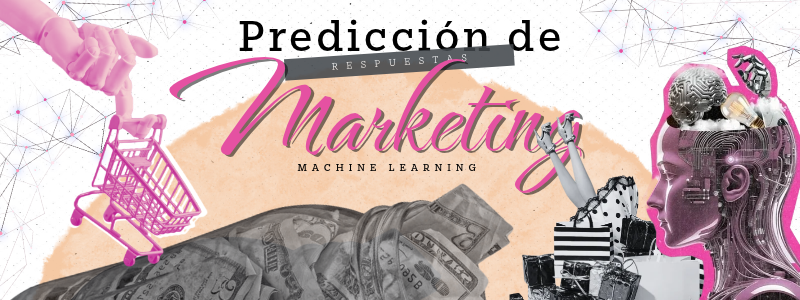

# **PREDICCIÓN DE RESPUESTA A OFERTAS DE MARKETING**
## Análisis Exploratorio de Datos

Por Luisa Doria y Yarilis Garcia


---


## Contenido

1. Contexto del problema
2. Configuración inicial
3. Carga y revisión inicial de los datos
4. Limpieza del dataset
5. Análisis de outliers
6. Creación de nuevas variables
7. Análisis exploratorio de datos (EDA)
8. Clasificación **sin** campañas anteriores
9. Clasificación **con** campañas anteriores
10. Comparación: sin vs. con campañas
11. Regresión: predicción del gasto total del cliente


# 1. Contexto del problema
Las empresas gastan mucho dinero en campañas de marketing que la mayoría de clientes ignoran. Nuestro objetivo es entender qué características distinguen a los clientes que sí aceptan una oferta, para poder dirigir mejor esas campañas y ahorrar costos. Trabajamos con el dataset Customer Personality Analysis de Kaggle, que tiene 2240 clientes y 29 variables (2216 clientes después de eliminar los registros sin ingreso). El principal desafío es que la variable objetivo está desbalanceada y muchas variables tienen outliers.

## 1.1 Origen del dataset
Este dataset es de Kaggle, específicamente el dataset llamado "Customer Personality Analysis". Es un dataset público que Kaggle publicó originalmente con un propósito de clustering (segmentar clientes en grupos), pero en nuestro problema lo reformulamos para una tarea de clasificación supervisada.


# 2. Configuración inicial
Librerías, semilla aleatoria y paletas de colores usadas en todo el notebook.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from matplotlib.patches import Patch

from sklearn.base import clone
from sklearn.compose import TransformedTargetRegressor
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.metrics import (accuracy_score, average_precision_score, confusion_matrix,
                             f1_score, make_scorer, mean_absolute_error, mean_squared_error,
                             precision_recall_curve, precision_score, recall_score,
                             root_mean_squared_error)
from sklearn.model_selection import (KFold, StratifiedKFold, cross_validate,
                                     learning_curve, train_test_split)
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KernelDensity
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC, SVR
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor, plot_tree

sns.set_theme()
SEED = 21

# Paletas de colores
cafe_palette_1 = ['#331a0d', '#804d1a', '#b3804d', '#e5a399', '#f2ccd9', '#fff5f2']
rosa_palette_1 = ["#C2185B", "#F06292", "#F8BBD0", "#AD1457", "#FF80AB", "#880E4F"]

pd.__version__


'2.2.3'

# 3. Carga y revisión inicial de los datos
## 3.1 Lectura del dataset


In [2]:
#Lectura del dataset

URL = "https://raw.githubusercontent.com/Lalo0105/Marketing-Campaign/refs/heads/main/marketing_campaign.csv"
df_original = pd.read_csv(URL, sep = '\t')   # copia sin modificar (se reutiliza en la sección de regresión)
campañas = df_original.copy()

print("Tamaño dataset: ", campañas.shape)
campañas.head(10)


Tamaño dataset:  (2240, 29)


,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,...,NumWebVisitsMonth,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Complain,Z_CostContact,Z_Revenue,Response
0,5524,1957,Graduation,Single,58138.0,0,0,04-09-2012,58,635,...,7,0,0,0,0,0,0,3,11,1
1,2174,1954,Graduation,Single,46344.0,1,1,08-03-2014,38,11,...,5,0,0,0,0,0,0,3,11,0
2,4141,1965,Graduation,Together,71613.0,0,0,21-08-2013,26,426,...,4,0,0,0,0,0,0,3,11,0
3,6182,1984,Graduation,Together,26646.0,1,0,10-02-2014,26,11,...,6,0,0,0,0,0,0,3,11,0
4,5324,1981,PhD,Married,58293.0,1,0,19-01-2014,94,173,...,5,0,0,0,0,0,0,3,11,0
5,7446,1967,Master,Together,62513.0,0,1,09-09-2013,16,520,...,6,0,0,0,0,0,0,3,11,0
6,965,1971,Graduation,Divorced,55635.0,0,1,13-11-2012,34,235,...,6,0,0,0,0,0,0,3,11,0
7,6177,1985,PhD,Married,33454.0,1,0,08-05-2013,32,76,...,8,0,0,0,0,0,0,3,11,0
8,4855,1974,PhD,Together,30351.0,1,0,06-06-2013,19,14,...,9,0,0,0,0,0,0,3,11,1
9,5899,1950,PhD,Together,5648.0,1,1,13-03-2014,68,28,...,20,1,0,0,0,0,0,3,11,0


## 3.2 Tipos de datos y resumen estadístico


In [3]:
print("Tipos de datos de columnas: \n\n", campañas.dtypes)


Tipos de datos de columnas: 

 ID                       int64
Year_Birth               int64
Education               object
Marital_Status          object
Income                 float64
Kidhome                  int64
Teenhome                 int64
Dt_Customer             object
Recency                  int64
MntWines                 int64
MntFruits                int64
MntMeatProducts          int64
MntFishProducts          int64
MntSweetProducts         int64
MntGoldProds             int64
NumDealsPurchases        int64
NumWebPurchases          int64
NumCatalogPurchases      int64
NumStorePurchases        int64
NumWebVisitsMonth        int64
AcceptedCmp3             int64
AcceptedCmp4             int64
AcceptedCmp5             int64
AcceptedCmp1             int64
AcceptedCmp2             int64
Complain                 int64
Z_CostContact            int64
Z_Revenue                int64
Response                 int64
dtype: object


In [4]:
print("\nResumen Datos: \n", campañas.describe())



Resumen Datos: 
                  ID   Year_Birth         Income      Kidhome     Teenhome  \
count   2240.000000  2240.000000    2216.000000  2240.000000  2240.000000   
mean    5592.159821  1968.805804   52247.251354     0.444196     0.506250   
std     3246.662198    11.984069   25173.076661     0.538398     0.544538   
min        0.000000  1893.000000    1730.000000     0.000000     0.000000   
25%     2828.250000  1959.000000   35303.000000     0.000000     0.000000   
50%     5458.500000  1970.000000   51381.500000     0.000000     0.000000   
75%     8427.750000  1977.000000   68522.000000     1.000000     1.000000   
max    11191.000000  1996.000000  666666.000000     2.000000     2.000000   

           Recency     MntWines    MntFruits  MntMeatProducts  \
count  2240.000000  2240.000000  2240.000000      2240.000000   
mean     49.109375   303.935714    26.302232       166.950000   
std      28.962453   336.597393    39.773434       225.715373   
min       0.000000     0.000

## 3.3 Variables constantes y valores nulos


In [5]:
print("Contactar al cliente es una variable constante?: ", campañas['Z_CostContact'].nunique())
print("El ingreso que genera el cliente es una variable constante?: ", campañas['Z_Revenue'].nunique())
print("Cantidad de valores nulos por columna: \n" , campañas.isnull().sum())


Contactar al cliente es una variable constante?:  1
El ingreso que genera el cliente es una variable constante?:  1
Cantidad de valores nulos por columna: 
 ID                      0
Year_Birth              0
Education               0
Marital_Status          0
Income                 24
Kidhome                 0
Teenhome                0
Dt_Customer             0
Recency                 0
MntWines                0
MntFruits               0
MntMeatProducts         0
MntFishProducts         0
MntSweetProducts        0
MntGoldProds            0
NumDealsPurchases       0
NumWebPurchases         0
NumCatalogPurchases     0
NumStorePurchases       0
NumWebVisitsMonth       0
AcceptedCmp3            0
AcceptedCmp4            0
AcceptedCmp5            0
AcceptedCmp1            0
AcceptedCmp2            0
Complain                0
Z_CostContact           0
Z_Revenue               0
Response                0
dtype: int64


# 4. Limpieza del dataset
Se eliminaron `Z_CostContact`, `Z_Revenue` y `ID`: las dos primeras tienen valores constantes y `ID` es solo el identificador del cliente, por lo que ninguna aporta información relevante. Además se eliminaron los 24 registros con `Income` nulo.


In [6]:
del campañas['Z_CostContact']
del campañas['Z_Revenue']
del campañas['ID']
campañas = campañas.dropna(subset=['Income'])
print("Valores nulos en Income luego de la limpieza: ", campañas['Income'].isnull().sum())

print(campañas.shape)
campañas.head(10)


Valores nulos en Income luego de la limpieza:  0
(2216, 26)


,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,MntFruits,...,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Complain,Response
0,1957,Graduation,Single,58138.0,0,0,04-09-2012,58,635,88,...,10,4,7,0,0,0,0,0,0,1
1,1954,Graduation,Single,46344.0,1,1,08-03-2014,38,11,1,...,1,2,5,0,0,0,0,0,0,0
2,1965,Graduation,Together,71613.0,0,0,21-08-2013,26,426,49,...,2,10,4,0,0,0,0,0,0,0
3,1984,Graduation,Together,26646.0,1,0,10-02-2014,26,11,4,...,0,4,6,0,0,0,0,0,0,0
4,1981,PhD,Married,58293.0,1,0,19-01-2014,94,173,43,...,3,6,5,0,0,0,0,0,0,0
5,1967,Master,Together,62513.0,0,1,09-09-2013,16,520,42,...,4,10,6,0,0,0,0,0,0,0
6,1971,Graduation,Divorced,55635.0,0,1,13-11-2012,34,235,65,...,3,7,6,0,0,0,0,0,0,0
7,1985,PhD,Married,33454.0,1,0,08-05-2013,32,76,10,...,0,4,8,0,0,0,0,0,0,0
8,1974,PhD,Together,30351.0,1,0,06-06-2013,19,14,0,...,0,2,9,0,0,0,0,0,0,1
9,1950,PhD,Together,5648.0,1,1,13-03-2014,68,28,0,...,0,0,20,1,0,0,0,0,0,0


# 5. Análisis de outliers


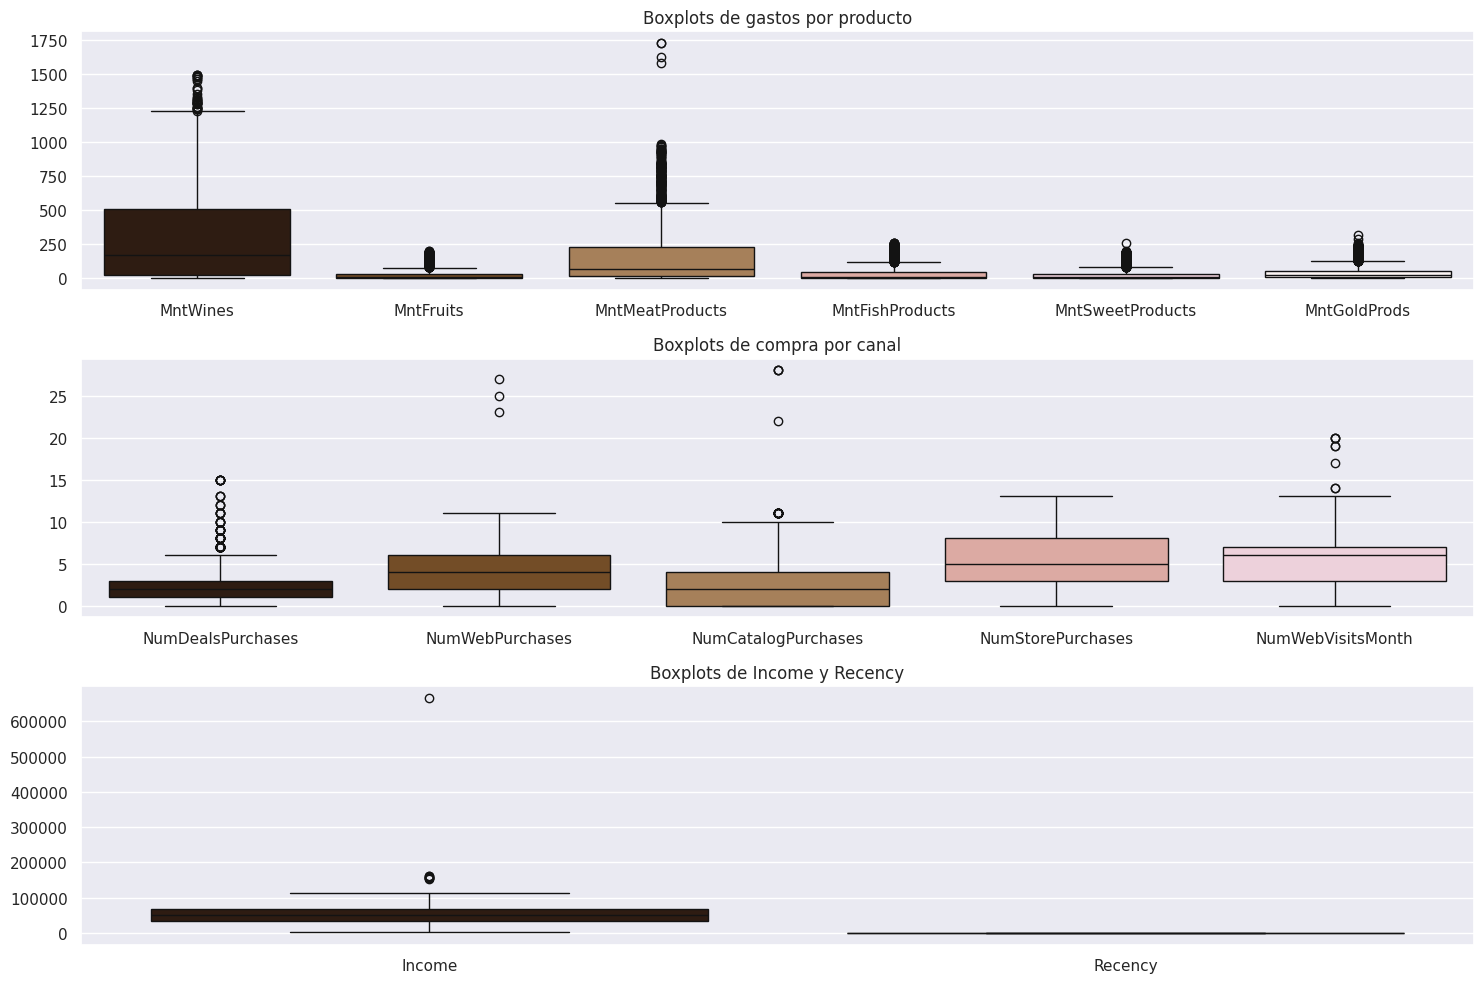

In [7]:
plt.figure(figsize=(15,10))

plt.subplot(3,1,1)
ax1 = sns.boxplot(data = campañas[['MntWines', 'MntFruits', 'MntMeatProducts', 'MntFishProducts', 'MntSweetProducts', 'MntGoldProds']], palette= cafe_palette_1)
plt.title('Boxplots de gastos por producto')

plt.subplot(3,1,2)
ax2 = sns.boxplot(data = campañas[['NumDealsPurchases', 'NumWebPurchases', 'NumCatalogPurchases', 'NumStorePurchases', 'NumWebVisitsMonth']], palette= cafe_palette_1[:5])
plt.title('Boxplots de compra por canal')

plt.subplot(3,1,3)
ax3 = sns.boxplot(data = campañas[['Income', 'Recency']], palette= cafe_palette_1[:2])
plt.title('Boxplots de Income y Recency')

plt.tight_layout()
plt.show()


## 5.1 Decisión sobre los outliers
En este dataset los outliers representan ingresos altos, gastos altos o números de compras altos en distintas situaciones. Al ser información valiosa decidimos no eliminarlos, sino usar estadística que permita trabajar con ellos sin que los resultados se vean afectados (mediana y rango intercuartílico en lugar de media y desviación estándar).


# 6. Creación de nuevas variables
Ya que el año de nacimiento y la fecha de registro del cliente por sí solos no aportan mucha información, creamos columnas que se pueden analizar fácilmente: la edad del cliente y el tiempo que lleva registrado, en meses.


In [8]:
campañas['Age'] = 2021 - campañas['Year_Birth']

campañas['Dt_Customer']= pd.to_datetime(campañas['Dt_Customer'], format='%d-%m-%Y', errors= 'coerce')
fecha_referencia = pd.Timestamp('2021-12-31')
campañas['Customer_Tenure_Month'] = ((fecha_referencia - campañas['Dt_Customer']) / pd.Timedelta(days = 30)).round(1)

print(campañas[['Dt_Customer', 'Customer_Tenure_Month']].head())


  Dt_Customer  Customer_Tenure_Month
0  2012-09-04                  113.5
1  2014-03-08                   95.2
2  2013-08-21                  101.8
3  2014-02-10                   96.0
4  2014-01-19                   96.8


In [9]:
print("Tipos de datos de columnas modificadas: \n\n", campañas.dtypes)


Tipos de datos de columnas modificadas: 

 Year_Birth                        int64
Education                        object
Marital_Status                   object
Income                          float64
Kidhome                           int64
Teenhome                          int64
Dt_Customer              datetime64[ns]
Recency                           int64
MntWines                          int64
MntFruits                         int64
MntMeatProducts                   int64
MntFishProducts                   int64
MntSweetProducts                  int64
MntGoldProds                      int64
NumDealsPurchases                 int64
NumWebPurchases                   int64
NumCatalogPurchases               int64
NumStorePurchases                 int64
NumWebVisitsMonth                 int64
AcceptedCmp3                      int64
AcceptedCmp4                      int64
AcceptedCmp5                      int64
AcceptedCmp1                      int64
AcceptedCmp2                      int

Se mezclan aleatoriamente las filas (con semilla fija) antes de dividir los datos.


In [10]:
campañas = campañas.sample(frac=1, random_state=SEED)
print(campañas)


      Year_Birth   Education Marital_Status   Income  Kidhome  Teenhome  \
730         1949         PhD       Divorced  35946.0        1         1   
1963        1952  Graduation         Single  40887.0        1         1   
153         1988  Graduation          Alone  34176.0        1         0   
1078        1968      Master         Single  50014.0        1         0   
1784        1971  Graduation       Together  34600.0        1         1   
...          ...         ...            ...      ...      ...       ...   
1157        1974  Graduation       Together  56715.0        0         0   
52          1977  Graduation         Single  35790.0        1         0   
785         1986       Basic        Married  20425.0        1         0   
1865        1973  Graduation          Widow  60208.0        1         1   
1244        1978         PhD       Together  27683.0        1         0   

     Dt_Customer  Recency  MntWines  MntFruits  ...  NumWebVisitsMonth  \
730   2013-09-27       24

# 7. Análisis exploratorio de datos (EDA)
## 7.1 Variable objetivo: `Response`


In [11]:
print("Cantidad de valores por aceptada(1)/no aceptada(0): \n",campañas["Response"].value_counts())
print("Porcentajes de cada tipo de reaccion: \n ", campañas["Response"].value_counts(normalize=True)*100)


Cantidad de valores por aceptada(1)/no aceptada(0): 
 Response
0    1883
1     333
Name: count, dtype: int64
Porcentajes de cada tipo de reaccion: 
  Response
0    84.972924
1    15.027076
Name: proportion, dtype: float64


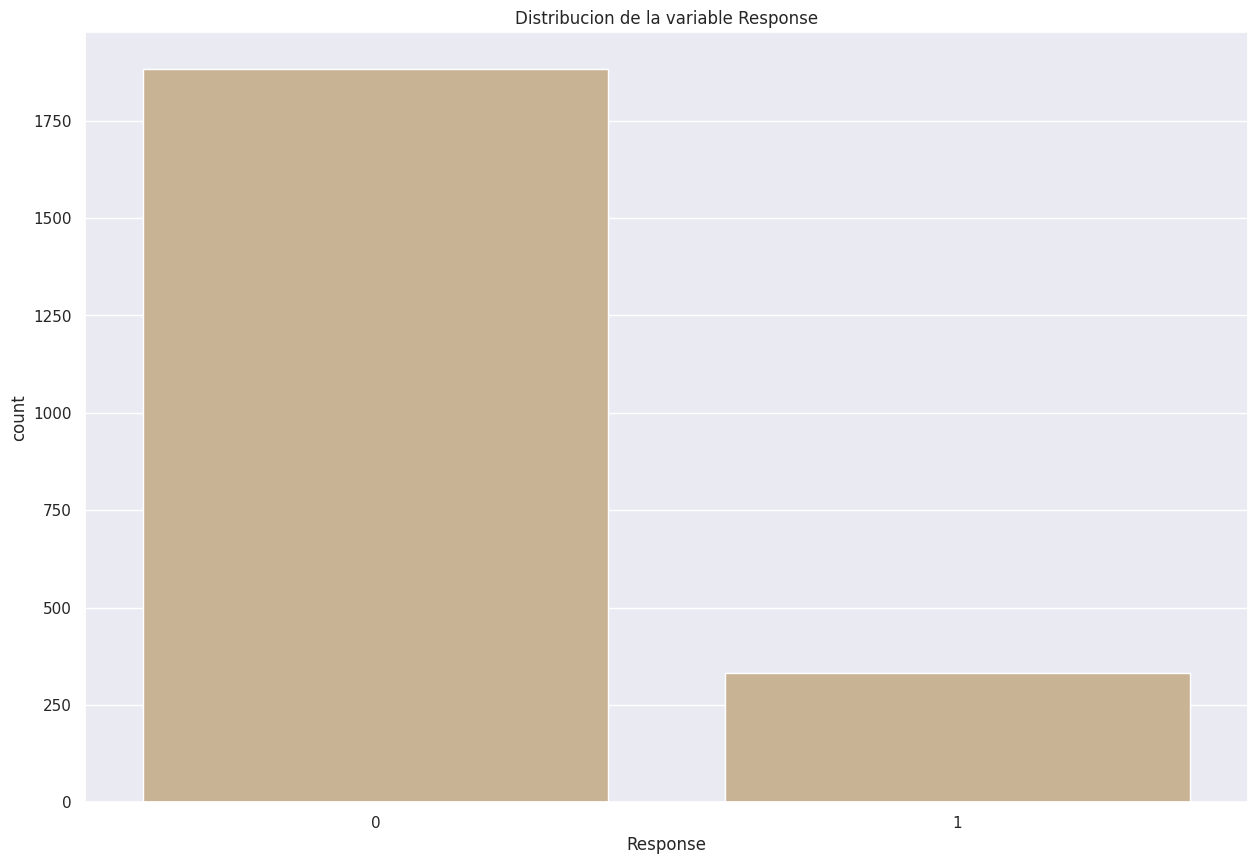

In [12]:
plt.figure(figsize=(15,10))


sns.countplot(x='Response',data=campañas,color="#D2B48C")
plt.title("Distribucion de la variable Response")

plt.show()


La variable `Response` está **desbalanceada**: 1883 clientes (84.97%) no
respondieron a la campaña, mientras que solo 333 clientes (15.03%) sí
respondieron. Esto implica que el modelo puede tener mayor facilidad para aprender a identificar la clase abundante (los que respondieron "no"), y obtener un accuracy alta sin saber identificar correctamente la clase minoritaria (los que respondieron que "sí"), por lo que a futuro no bastará con medir exactitud (`accuracy`); se necesitarán métricas como precisión, recall o F1 que reflejen el desempeño sobre la clase minoritaria.


## 7.2 Correlaciones con `Response`


In [13]:
corr = campañas.corr(numeric_only=True)
print(corr['Response'].sort_values(ascending=False))


Response                 1.000000
AcceptedCmp5             0.323374
AcceptedCmp1             0.297345
AcceptedCmp3             0.254005
MntWines                 0.246299
MntMeatProducts          0.237746
NumCatalogPurchases      0.219914
Customer_Tenure_Month    0.196397
AcceptedCmp4             0.180205
AcceptedCmp2             0.169294
NumWebPurchases          0.151431
MntGoldProds             0.140332
Income                   0.133047
MntFruits                0.122443
MntSweetProducts         0.116170
MntFishProducts          0.108145
NumStorePurchases        0.036241
Year_Birth               0.023692
NumDealsPurchases        0.003451
Complain                -0.002029
NumWebVisitsMonth       -0.002209
Age                     -0.023692
Kidhome                 -0.077909
Teenhome                -0.153901
Recency                 -0.199766
Name: Response, dtype: float64


## 7.3 Variables numéricas según `Response`


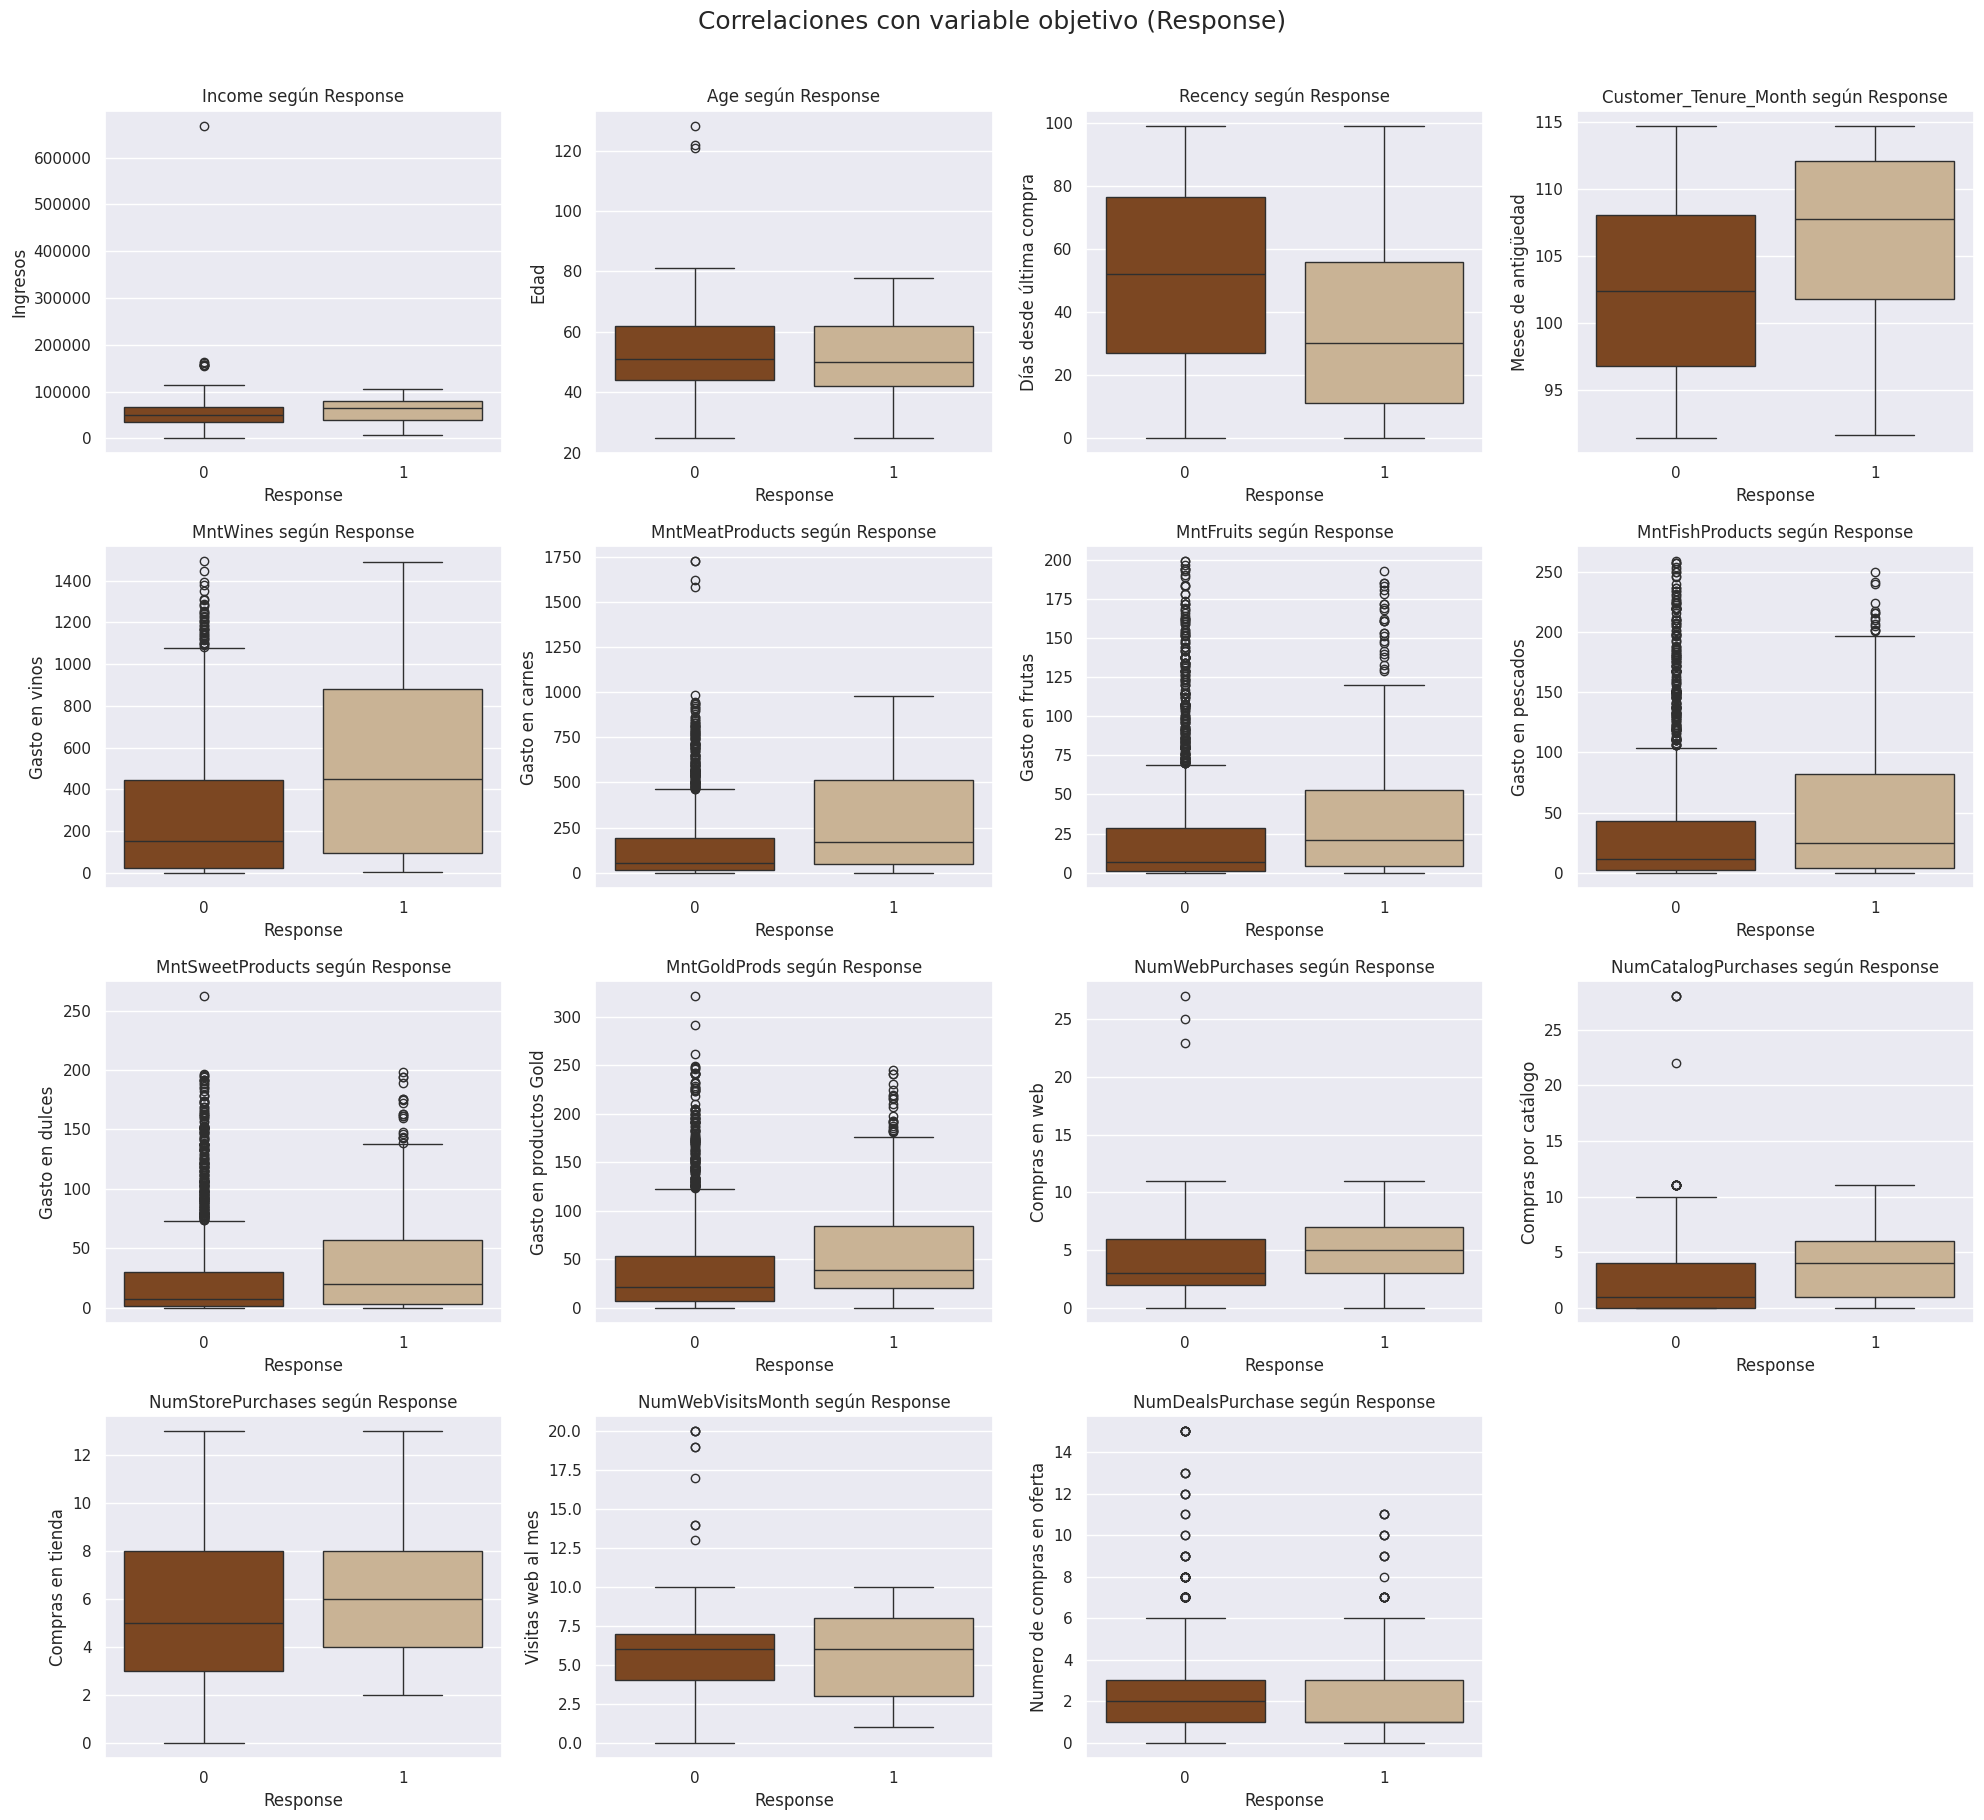

In [14]:
#Correlaciones con variable objetivo

cafe_palette = ['#8B4513', '#D2B48C']

plt.figure(figsize=(20, 18))
plt.suptitle('Correlaciones con variable objetivo (Response)', fontsize=18, y=1.01)

plt.subplot(4, 4, 1)
sns.boxplot(data=campañas, x='Response', y='Income', hue='Response', palette=cafe_palette, legend=False)
plt.title('Income según Response')
plt.xlabel('Response')
plt.ylabel('Ingresos')

plt.subplot(4, 4, 2)
sns.boxplot(data=campañas, x='Response', y='Age', hue='Response', palette=cafe_palette, legend=False)
plt.title('Age según Response')
plt.xlabel('Response')
plt.ylabel('Edad')

plt.subplot(4, 4, 3)
sns.boxplot(data=campañas, x='Response', y='Recency', hue='Response', palette=cafe_palette, legend=False)
plt.title('Recency según Response')
plt.xlabel('Response')
plt.ylabel('Días desde última compra')

plt.subplot(4, 4, 4)
sns.boxplot(data=campañas, x='Response', y='Customer_Tenure_Month', hue='Response', palette=cafe_palette, legend=False)
plt.title('Customer_Tenure_Month según Response')
plt.xlabel('Response')
plt.ylabel('Meses de antigüedad')

plt.subplot(4, 4, 5)
sns.boxplot(data=campañas, x='Response', y='MntWines', hue='Response', palette=cafe_palette, legend=False)
plt.title('MntWines según Response')
plt.xlabel('Response')
plt.ylabel('Gasto en vinos')

plt.subplot(4, 4, 6)
sns.boxplot(data=campañas, x='Response', y='MntMeatProducts', hue='Response', palette=cafe_palette, legend=False)
plt.title('MntMeatProducts según Response')
plt.xlabel('Response')
plt.ylabel('Gasto en carnes')

plt.subplot(4, 4, 7)
sns.boxplot(data=campañas, x='Response', y='MntFruits', hue='Response', palette=cafe_palette, legend=False)
plt.title('MntFruits según Response')
plt.xlabel('Response')
plt.ylabel('Gasto en frutas')

plt.subplot(4, 4, 8)
sns.boxplot(data=campañas, x='Response', y='MntFishProducts', hue='Response', palette=cafe_palette, legend=False)
plt.title('MntFishProducts según Response')
plt.xlabel('Response')
plt.ylabel('Gasto en pescados')

plt.subplot(4, 4, 9)
sns.boxplot(data=campañas, x='Response', y='MntSweetProducts', hue='Response', palette=cafe_palette, legend=False)
plt.title('MntSweetProducts según Response')
plt.xlabel('Response')
plt.ylabel('Gasto en dulces')

plt.subplot(4, 4, 10)
sns.boxplot(data=campañas, x='Response', y='MntGoldProds', hue='Response', palette=cafe_palette, legend=False)
plt.title('MntGoldProds según Response')
plt.xlabel('Response')
plt.ylabel('Gasto en productos Gold')

plt.subplot(4, 4, 11)
sns.boxplot(data=campañas, x='Response', y='NumWebPurchases', hue='Response', palette=cafe_palette, legend=False)
plt.title('NumWebPurchases según Response')
plt.xlabel('Response')
plt.ylabel('Compras en web')

plt.subplot(4, 4, 12)
sns.boxplot(data=campañas, x='Response', y='NumCatalogPurchases', hue='Response', palette=cafe_palette, legend=False)
plt.title('NumCatalogPurchases según Response')
plt.xlabel('Response')
plt.ylabel('Compras por catálogo')

plt.subplot(4, 4, 13)
sns.boxplot(data=campañas, x='Response', y='NumStorePurchases', hue='Response', palette=cafe_palette, legend=False)
plt.title('NumStorePurchases según Response')
plt.xlabel('Response')
plt.ylabel('Compras en tienda')

plt.subplot(4, 4, 14)
sns.boxplot(data=campañas, x='Response', y='NumWebVisitsMonth', hue='Response', palette=cafe_palette, legend=False)
plt.title('NumWebVisitsMonth según Response')
plt.xlabel('Response')
plt.ylabel('Visitas web al mes')

plt.subplot(4, 4, 15)
sns.boxplot(data=campañas, x='Response', y='NumDealsPurchases' , hue='Response', palette=cafe_palette, legend=False)
plt.title('NumDealsPurchase según Response')
plt.xlabel('Response')
plt.ylabel('Numero de compras en oferta')




plt.tight_layout()
plt.show()


Las variables con diferencia más clara entre quienes respondieron y quienes no
son `MntWines`, `MntMeatProducts` y `Recency` — sus cajas se desplazan
visiblemente entre los dos grupos. En cambio, `Income` y `Age` muestran cajas
casi superpuestas entre Response 0 y 1, lo que confirma por qué se descartaron
del análisis principal a pesar de tener correlación moderada.


## 7.4 Variables categóricas según `Response`


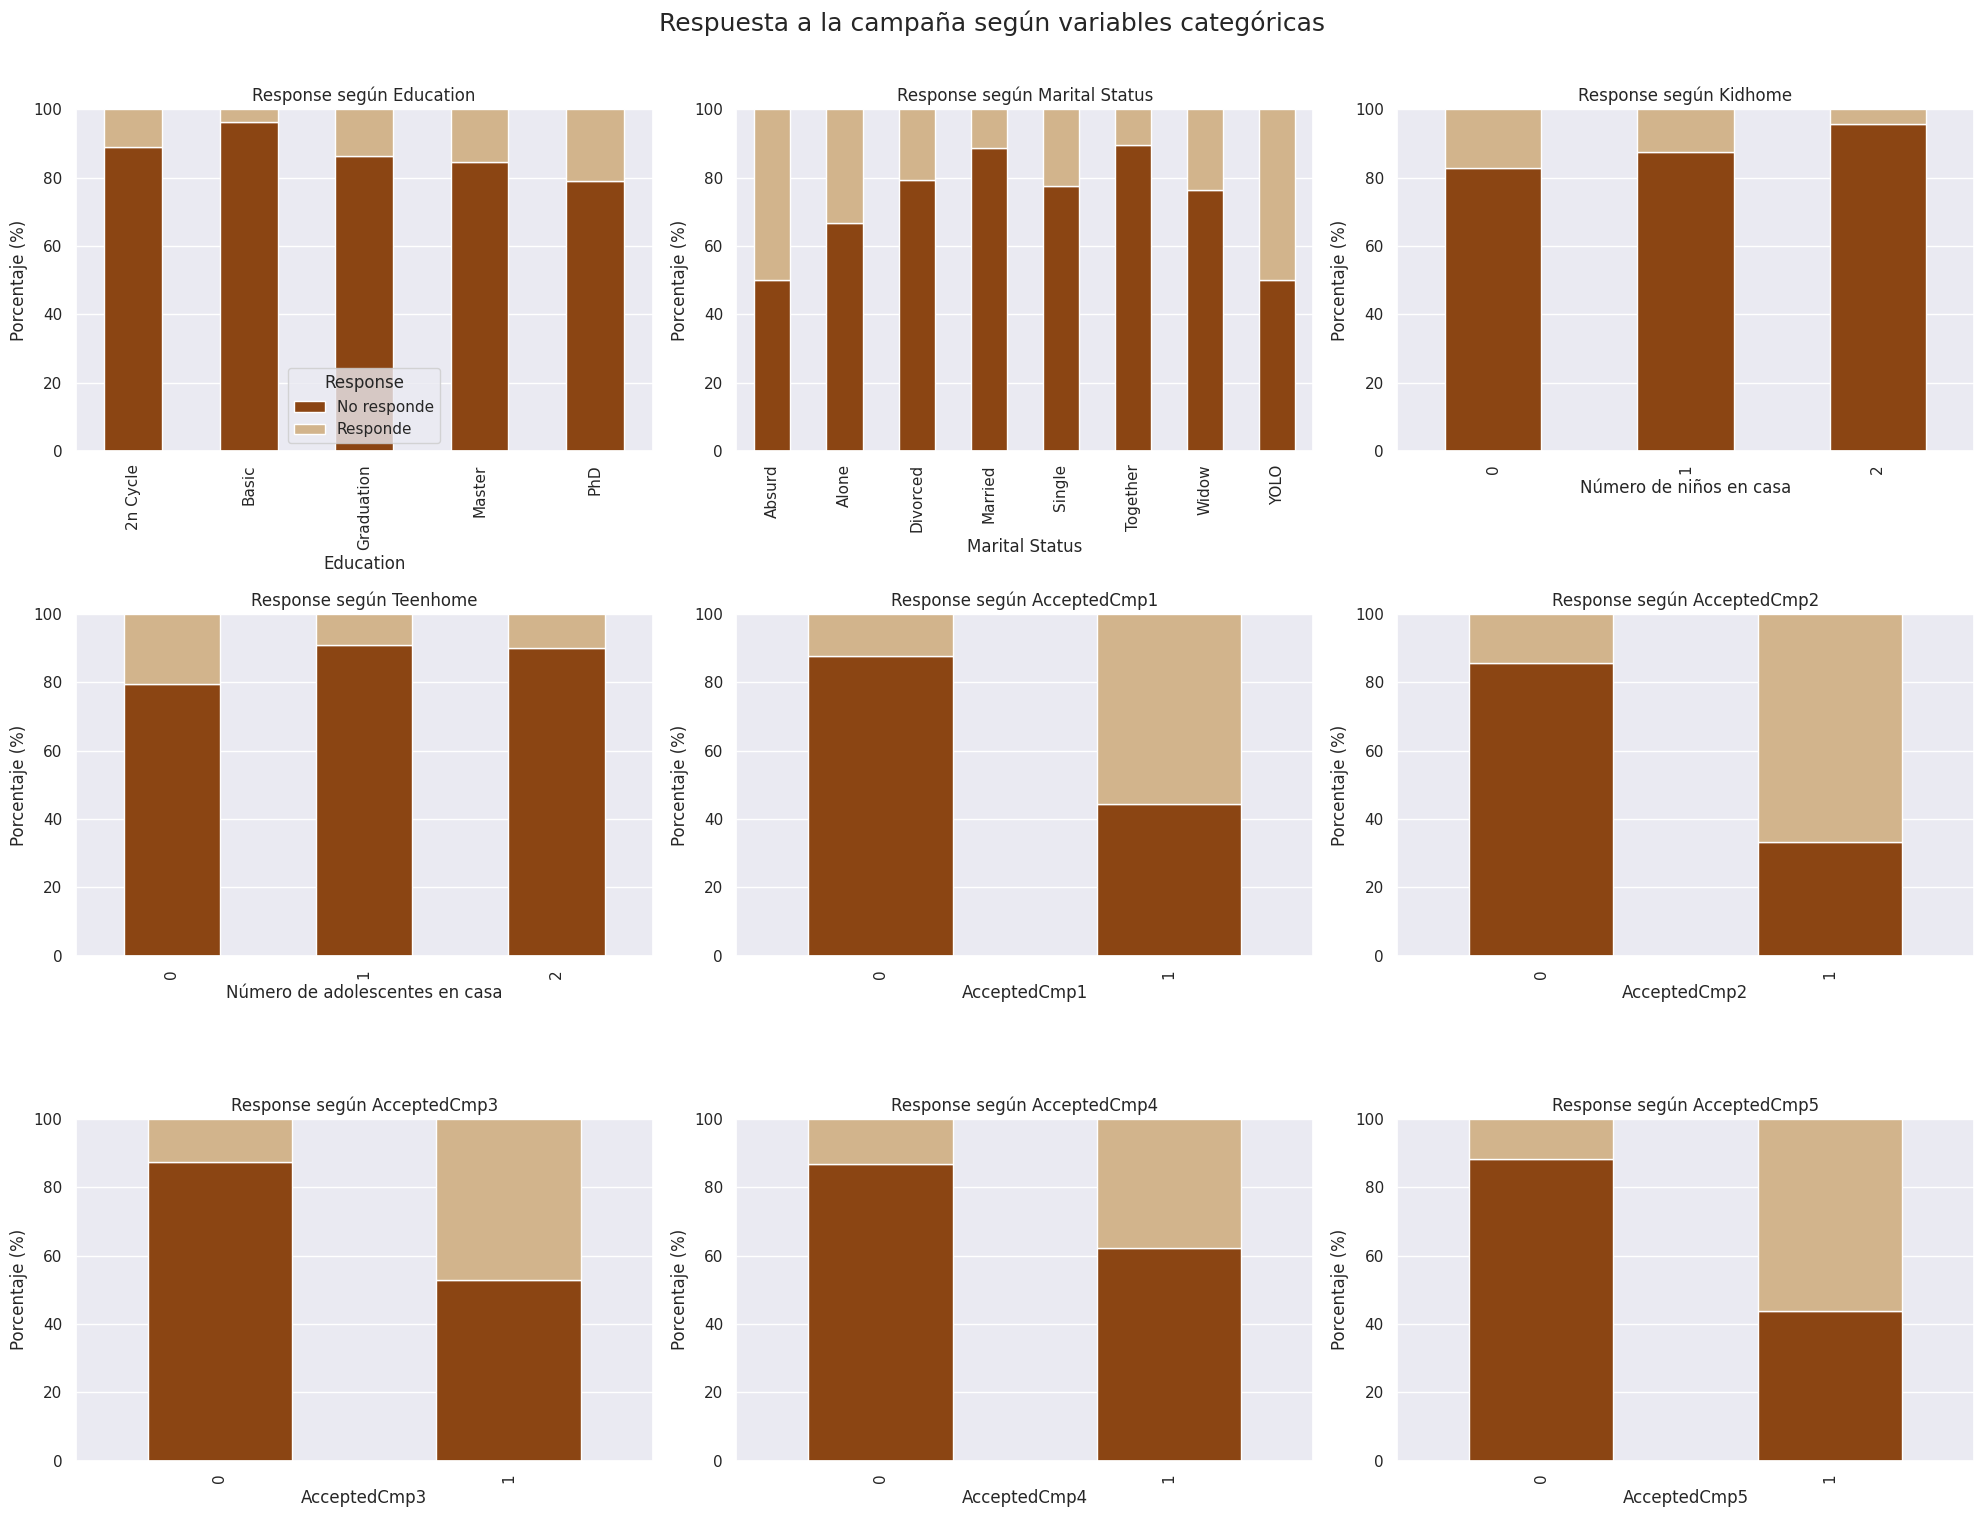

In [15]:
#Distinciones entre categorias de variables categoricas
cafe_palette = ['#8B4513', '#D2B48C']

plt.figure(figsize=(20, 15))
plt.suptitle('Respuesta a la campaña según variables categóricas',fontsize=18,y=1.01)

tabla_education = pd.crosstab(campañas['Education'],campañas['Response'],normalize='index') * 100
plt.subplot(3, 3, 1)
tabla_education.plot(kind='bar',stacked=True,ax=plt.gca(),color=cafe_palette)

plt.title('Response según Education')
plt.xlabel('Education')
plt.ylabel('Porcentaje (%)')
plt.ylim(0, 100)
plt.legend(['No responde', 'Responde'], title='Response')


tabla_marital = pd.crosstab(campañas['Marital_Status'], campañas['Response'], normalize='index') * 100
plt.subplot(3, 3, 2)
tabla_marital.plot(kind='bar',stacked=True, ax=plt.gca(), color=cafe_palette,legend=False)

plt.title('Response según Marital Status')
plt.xlabel('Marital Status')
plt.ylabel('Porcentaje (%)')
plt.ylim(0, 100)

tabla_kidhome = pd.crosstab(campañas['Kidhome'],campañas['Response'], normalize='index') * 100
plt.subplot(3, 3, 3)
tabla_kidhome.plot(kind='bar',stacked=True,ax=plt.gca(),color=cafe_palette,legend=False)

plt.title('Response según Kidhome')
plt.xlabel('Número de niños en casa')
plt.ylabel('Porcentaje (%)')
plt.ylim(0, 100)

tabla_teenhome = pd.crosstab(campañas['Teenhome'],campañas['Response'],normalize='index') * 100
plt.subplot(3, 3, 4)
tabla_teenhome.plot(kind='bar',stacked=True,ax=plt.gca(),color=cafe_palette,legend=False)

plt.title('Response según Teenhome')
plt.xlabel('Número de adolescentes en casa')
plt.ylabel('Porcentaje (%)')
plt.ylim(0, 100)

tabla_cmp1 = pd.crosstab(campañas['AcceptedCmp1'],campañas['Response'],normalize='index') * 100
plt.subplot(3, 3, 5)
tabla_cmp1.plot(kind='bar',stacked=True,ax=plt.gca(),color=cafe_palette,legend=False)

plt.title('Response según AcceptedCmp1')
plt.xlabel('AcceptedCmp1')
plt.ylabel('Porcentaje (%)')
plt.ylim(0, 100)


tabla_cmp2 = pd.crosstab(campañas['AcceptedCmp2'],campañas['Response'],normalize='index') * 100
plt.subplot(3, 3, 6)
tabla_cmp2.plot(kind='bar',stacked=True,ax=plt.gca(),color=cafe_palette,legend=False)

plt.title('Response según AcceptedCmp2')
plt.xlabel('AcceptedCmp2')
plt.ylabel('Porcentaje (%)')
plt.ylim(0, 100)

tabla_cmp3 = pd.crosstab(campañas['AcceptedCmp3'],campañas['Response'],normalize='index') * 100
plt.subplot(3, 3, 7)
tabla_cmp3.plot(kind='bar',stacked=True,ax=plt.gca(),color=cafe_palette,legend=False)

plt.title('Response según AcceptedCmp3')
plt.xlabel('AcceptedCmp3')
plt.ylabel('Porcentaje (%)')
plt.ylim(0, 100)

tabla_cmp4 = pd.crosstab(campañas['AcceptedCmp4'],campañas['Response'],normalize='index') * 100
plt.subplot(3, 3, 8)
tabla_cmp4.plot(kind='bar',stacked=True,ax=plt.gca(),color=cafe_palette,legend=False)

plt.title('Response según AcceptedCmp4')
plt.xlabel('AcceptedCmp4')
plt.ylabel('Porcentaje (%)')
plt.ylim(0, 100)

tabla_cmp5 = pd.crosstab(campañas['AcceptedCmp5'],campañas['Response'],normalize='index') * 100
plt.subplot(3, 3, 9)
tabla_cmp5.plot(kind='bar',stacked=True,ax=plt.gca(),color=cafe_palette,legend=False)

plt.title('Response según AcceptedCmp5')
plt.xlabel('AcceptedCmp5')
plt.ylabel('Porcentaje (%)')
plt.ylim(0, 100)



plt.tight_layout()
plt.show()


## 7.5 Selección de variables predictoras

Como el dataset supera las 20 características, se prioriza el análisis en las
variables con mayor relación (numérica o visual) con `Response`. La decisión
se justifica variable por variable, combinando el coeficiente de correlación
con la evidencia de los gráficos condicionados a Response.

### Variables seleccionadas

- **`AcceptedCmp5`** (corr. 0.323) — la tasa de respuesta salta de ~12% a ~56%
  entre quienes no aceptaron vs sí aceptaron esta campaña; es la diferencia más
  marcada del dataset.
- **`AcceptedCmp1`** (corr. 0.297) — salto similar, de ~13% a ~56%.
- **`AcceptedCmp3`** (corr. 0.254) — de ~13% a ~47%.
- **`MntWines`** (corr. 0.246) — la mediana de gasto casi se duplica en quienes
  respondieron.
- **`MntMeatProducts`** (corr. 0.238) — aumento visible en el boxplot.
- **`NumCatalogPurchases`** (corr. 0.220) — la mediana sube de ~2 a ~4 compras
  por catálogo entre quienes respondieron.
- **`Customer_Tenure_Month`** (corr. 0.196) — mayor antigüedad se asocia con
  más probabilidad de responder.
- **`AcceptedCmp2`** (corr. 0.169) — aunque su correlación numérica es
  moderada, es el segundo salto más dramático visualmente (~15% a ~67% de
  respuesta), probablemente subestimado por Pearson debido a que pocos
  clientes aceptaron esta campaña específica.
- **`AcceptedCmp4`** (corr. 0.180) — salto de ~14% a ~38%.
- **`MntGoldProds`** (corr. 0.140) — diferencia moderada en la mediana de gasto.
- **`MntFruits`** (corr. 0.122) — diferencia leve en la mediana de gasto.
- **`MntSweetProducts`** (corr. 0.116) — diferencia leve.
- **`MntFishProducts`** (corr. 0.108) — diferencia leve.
- **`Recency`** (corr. -0.200) — quienes respondieron llevan menos días desde
  su última compra.
- **`Teenhome`** (corr. -0.154) — patrón no lineal: los clientes con 1
  adolescente responden menos que quienes tienen 0 o 2, no es una relación directamente proporcional.
- **`Education`** — se observa variación real entre niveles: Basic ~95% no
  responde, frente a PhD ~78%.
- **`Marital_Status`** — las personas solteras tienden a responder más que las que están en pareja de cualquier forma (ignorando `YOLO` y `Absurd`).
### Variables descartadas
No se observaron diferencias entre los grupos de `Response` en el boxplot.


- **`Income`** (0.133)
- **`NumWebPurchases`** (0.151)
- **`Age`** (corr. -0.024), **`NumDealsPurchases`** (0.003),
  **`NumStorePurchases`** (0.036), **`Year_Birth`** (0.024),
  **`Complain`** (-0.002), **`NumWebVisitsMonth`** (-0.002),
  **`Kidhome`** (-0.078)

### Clasificación de las variables por tipo de dato

**Categóricas:** `Education`, `Marital_Status`, `AcceptedCmp5`, `AcceptedCmp1`,
`AcceptedCmp3`, `AcceptedCmp2`, `AcceptedCmp4`, `Teenhome`

**Numéricas asimétricas:** `MntWines`, `MntMeatProducts`, `NumCatalogPurchases`,
`Customer_Tenure_Month`, `Recency`, `MntGoldProds`, `MntFruits`,
`MntSweetProducts`, `MntFishProducts`


## 7.6 Distribución de las variables seleccionadas
### 7.6.1 Variables categóricas


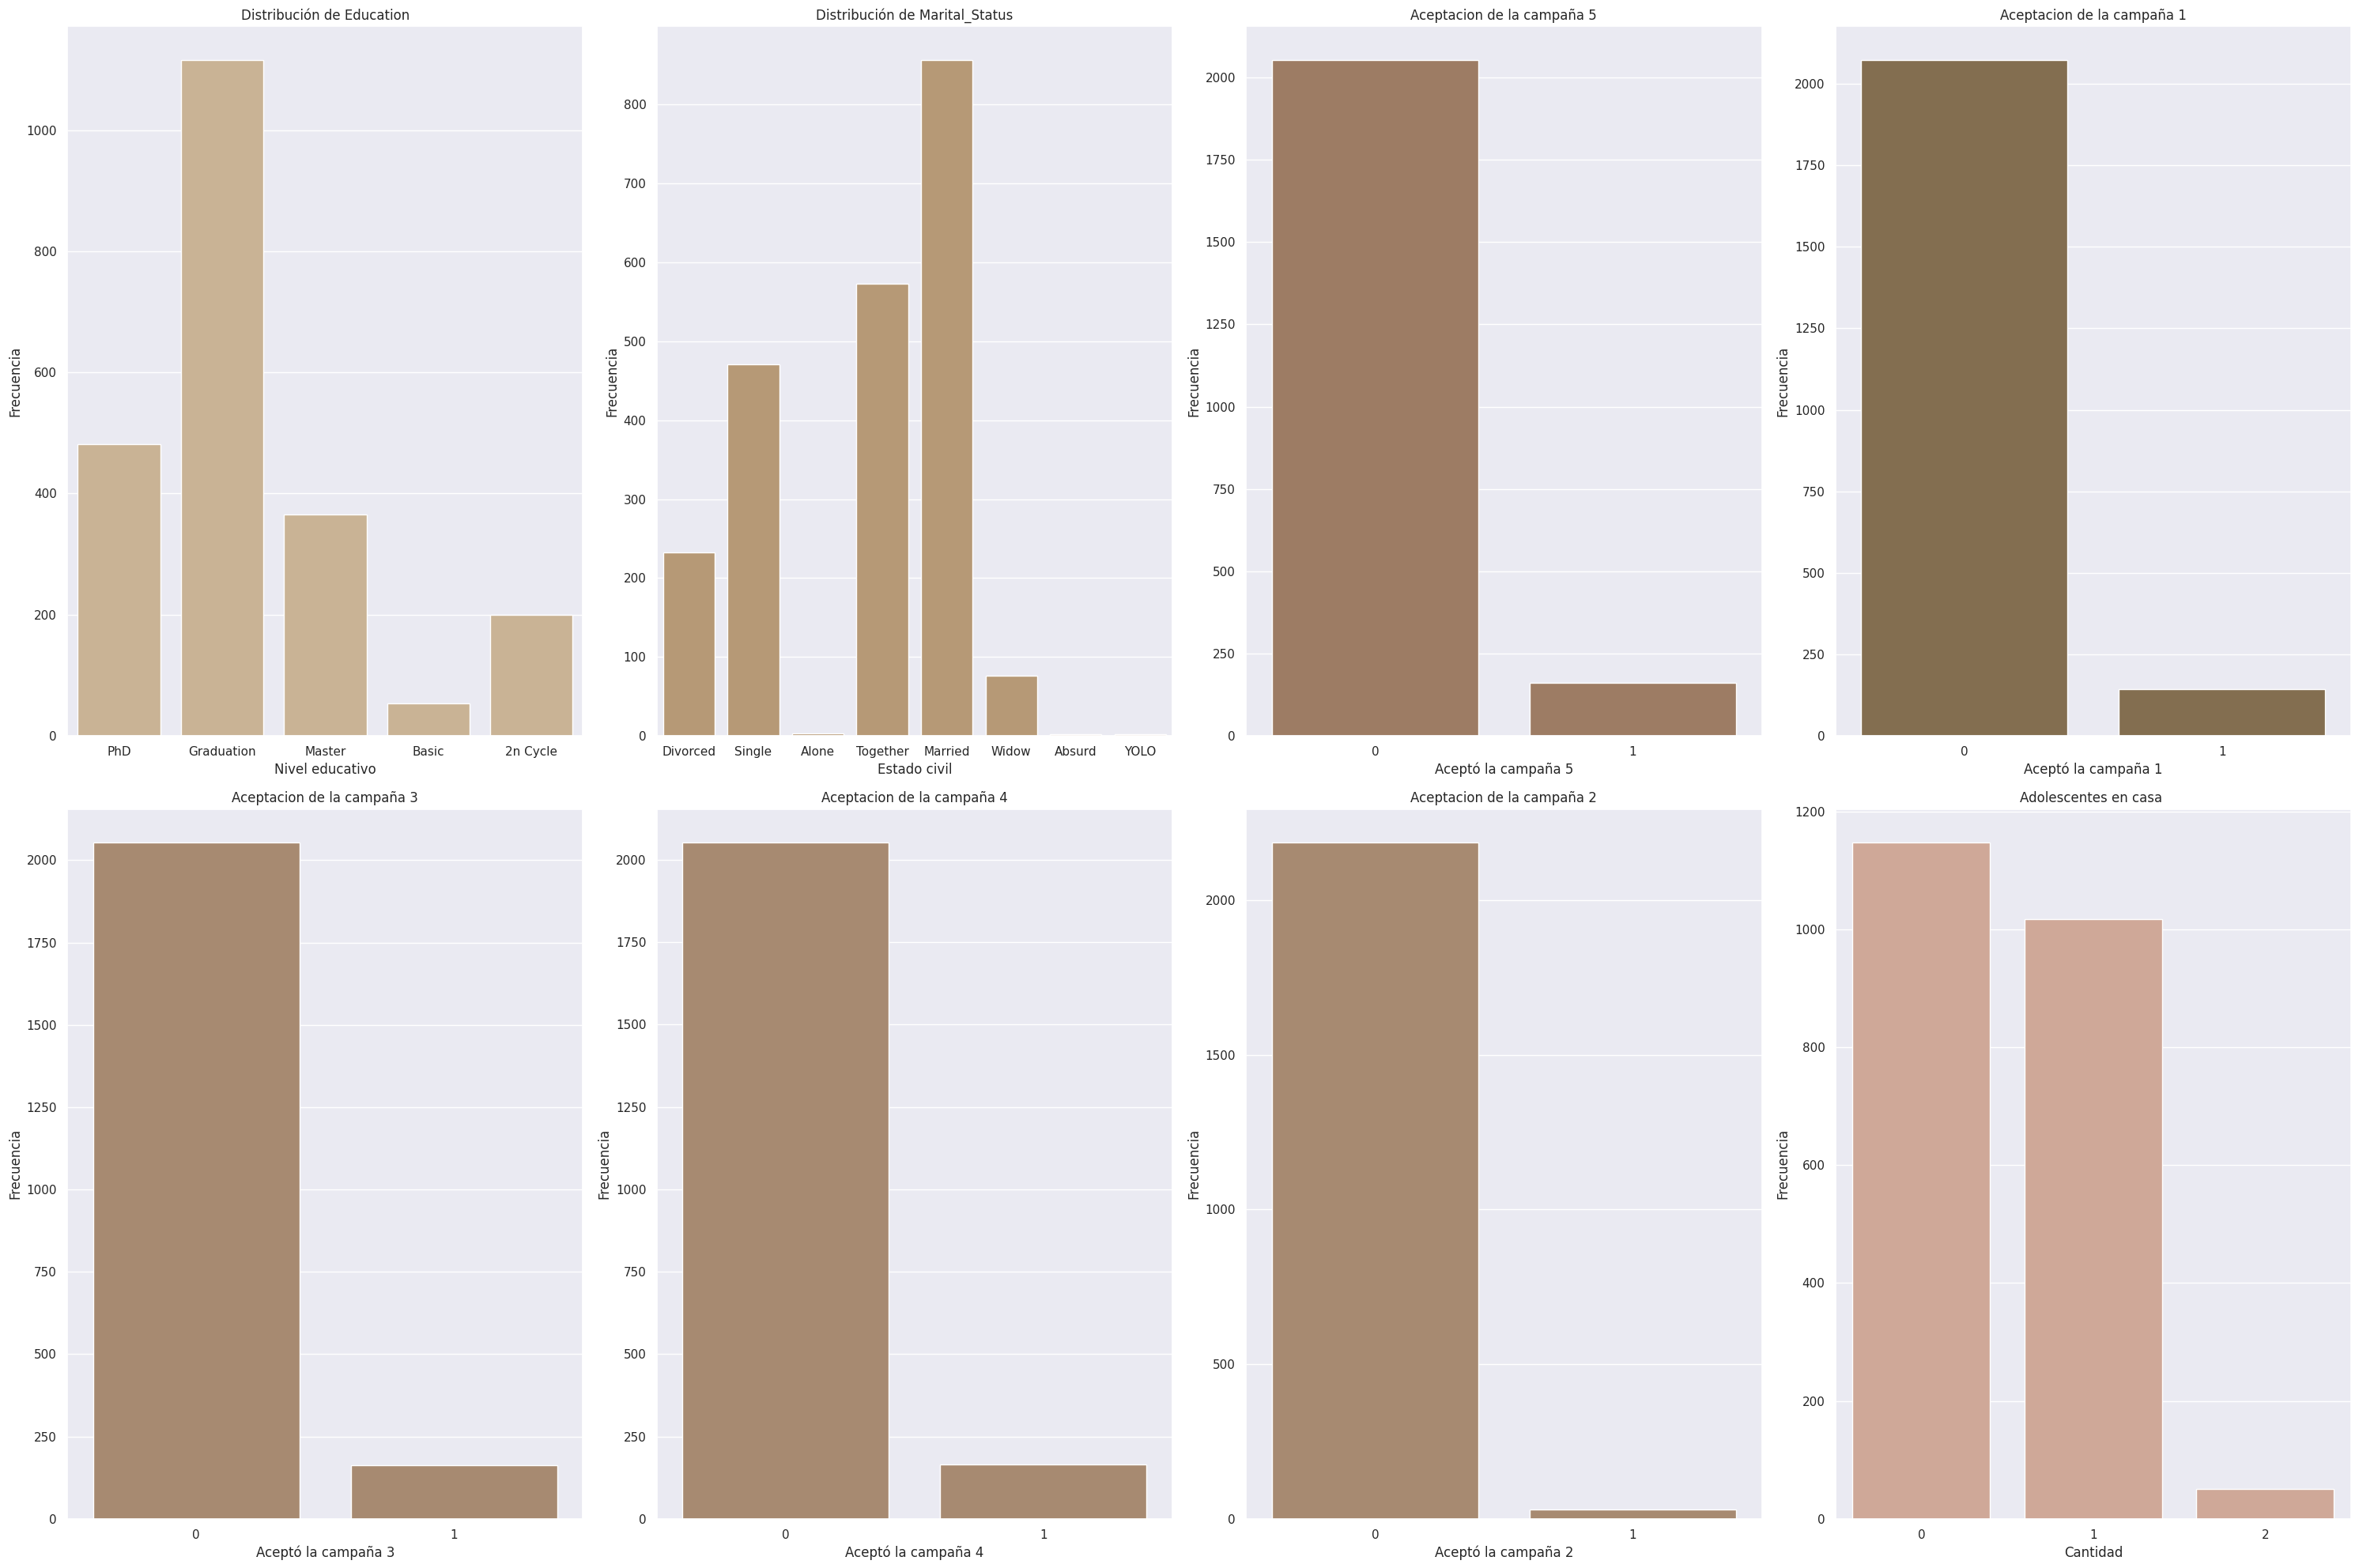

In [16]:
#Categoricas
#Graficas
plt.figure(figsize=(30,20))
plt.subplot(2,4,1)

ax1= sns.countplot(x=("Education"), data=campañas, color="#D2B48C")
plt.title('Distribución de Education')
plt.xlabel('Nivel educativo')
plt.ylabel('Frecuencia')

plt.subplot(2,4,2)
ax2= sns.countplot(x=("Marital_Status"), data=campañas, color="#C19A6B")
plt.title('Distribución de Marital_Status')
plt.xlabel('Estado civil')
plt.ylabel('Frecuencia')

plt.subplot(2,4,3)
ax3= sns.countplot(x=("AcceptedCmp5"), data=campañas, color="#A67B5B")
plt.title('Aceptacion de la campaña 5')
plt.xlabel('Aceptó la campaña 5')
plt.ylabel('Frecuencia')

plt.subplot(2,4,4)
ax4= sns.countplot(x=("AcceptedCmp1"), data=campañas, color="#8B6F47")
plt.title('Aceptacion de la campaña 1')
plt.xlabel('Aceptó la campaña 1')
plt.ylabel('Frecuencia')

plt.subplot(2,4,5)
ax5= sns.countplot(x=("AcceptedCmp3"), data=campañas, color="#B08968")
plt.title('Aceptacion de la campaña 3')
plt.xlabel('Aceptó la campaña 3')
plt.ylabel('Frecuencia')

plt.subplot(2,4,6)
ax5= sns.countplot(x=("AcceptedCmp4"), data=campañas, color="#B08968")
plt.title('Aceptacion de la campaña 4')
plt.xlabel('Aceptó la campaña 4')
plt.ylabel('Frecuencia')

plt.subplot(2,4,7)
ax5= sns.countplot(x=("AcceptedCmp2"), data=campañas, color="#B08968")
plt.title('Aceptacion de la campaña 2')
plt.xlabel('Aceptó la campaña 2')
plt.ylabel('Frecuencia')

plt.subplot(2,4,8)
ax6= sns.countplot(x=("Teenhome"), data=campañas, color="#D8A48F")
plt.title('Adolescentes en casa ')
plt.xlabel('Cantidad')
plt.ylabel('Frecuencia')

plt.tight_layout()
plt.show()


**Estadísticas**


In [17]:
# Estadísticas

print("Estadísticas")

print("Cantidad por nivel:\n", campañas["Education"].value_counts())
print("Porcentaje por nivel:\n", campañas["Education"].value_counts(normalize=True) * 100)


Estadísticas
Cantidad por nivel:
 Education
Graduation    1116
PhD            481
Master         365
2n Cycle       200
Basic           54
Name: count, dtype: int64
Porcentaje por nivel:
 Education
Graduation    50.361011
PhD           21.705776
Master        16.471119
2n Cycle       9.025271
Basic          2.436823
Name: proportion, dtype: float64


In [18]:
print("Cantidad por estado civil:\n", campañas["Marital_Status"].value_counts())
print("Porcentaje por estado civil:\n", campañas["Marital_Status"].value_counts(normalize=True) * 100)


Cantidad por estado civil:
 Marital_Status
Married     857
Together    573
Single      471
Divorced    232
Widow        76
Alone         3
Absurd        2
YOLO          2
Name: count, dtype: int64
Porcentaje por estado civil:
 Marital_Status
Married     38.673285
Together    25.857401
Single      21.254513
Divorced    10.469314
Widow        3.429603
Alone        0.135379
Absurd       0.090253
YOLO         0.090253
Name: proportion, dtype: float64


In [19]:
# Aceptación de cada campaña previa
for col in ['AcceptedCmp5', 'AcceptedCmp1', 'AcceptedCmp3', 'AcceptedCmp4', 'AcceptedCmp2']:
    print(f"--- {col} ---")
    print("Cantidad por respuesta:\n", campañas[col].value_counts())
    print("Porcentaje por respuesta:\n", campañas[col].value_counts(normalize=True) * 100)
    print()


--- AcceptedCmp5 ---
Cantidad por respuesta:
 AcceptedCmp5
0    2054
1     162
Name: count, dtype: int64
Porcentaje por respuesta:
 AcceptedCmp5
0    92.689531
1     7.310469
Name: proportion, dtype: float64

--- AcceptedCmp1 ---
Cantidad por respuesta:
 AcceptedCmp1
0    2074
1     142
Name: count, dtype: int64
Porcentaje por respuesta:
 AcceptedCmp1
0    93.592058
1     6.407942
Name: proportion, dtype: float64

--- AcceptedCmp3 ---
Cantidad por respuesta:
 AcceptedCmp3
0    2053
1     163
Name: count, dtype: int64
Porcentaje por respuesta:
 AcceptedCmp3
0    92.644404
1     7.355596
Name: proportion, dtype: float64

--- AcceptedCmp4 ---
Cantidad por respuesta:
 AcceptedCmp4
0    2052
1     164
Name: count, dtype: int64
Porcentaje por respuesta:
 AcceptedCmp4
0    92.599278
1     7.400722
Name: proportion, dtype: float64

--- AcceptedCmp2 ---
Cantidad por respuesta:
 AcceptedCmp2
0    2186
1      30
Name: count, dtype: int64
Porcentaje por respuesta:
 AcceptedCmp2
0    98.646209
1   

In [20]:
print("Cantidad por número de adolescentes:\n", campañas["Teenhome"].value_counts())
print("Porcentaje por número de adolescentes:\n", campañas["Teenhome"].value_counts(normalize=True) * 100)


Cantidad por número de adolescentes:
 Teenhome
0    1147
1    1018
2      51
Name: count, dtype: int64
Porcentaje por número de adolescentes:
 Teenhome
0    51.759928
1    45.938628
2     2.301444
Name: proportion, dtype: float64


### 7.6.2 Variables numéricas asimétricas


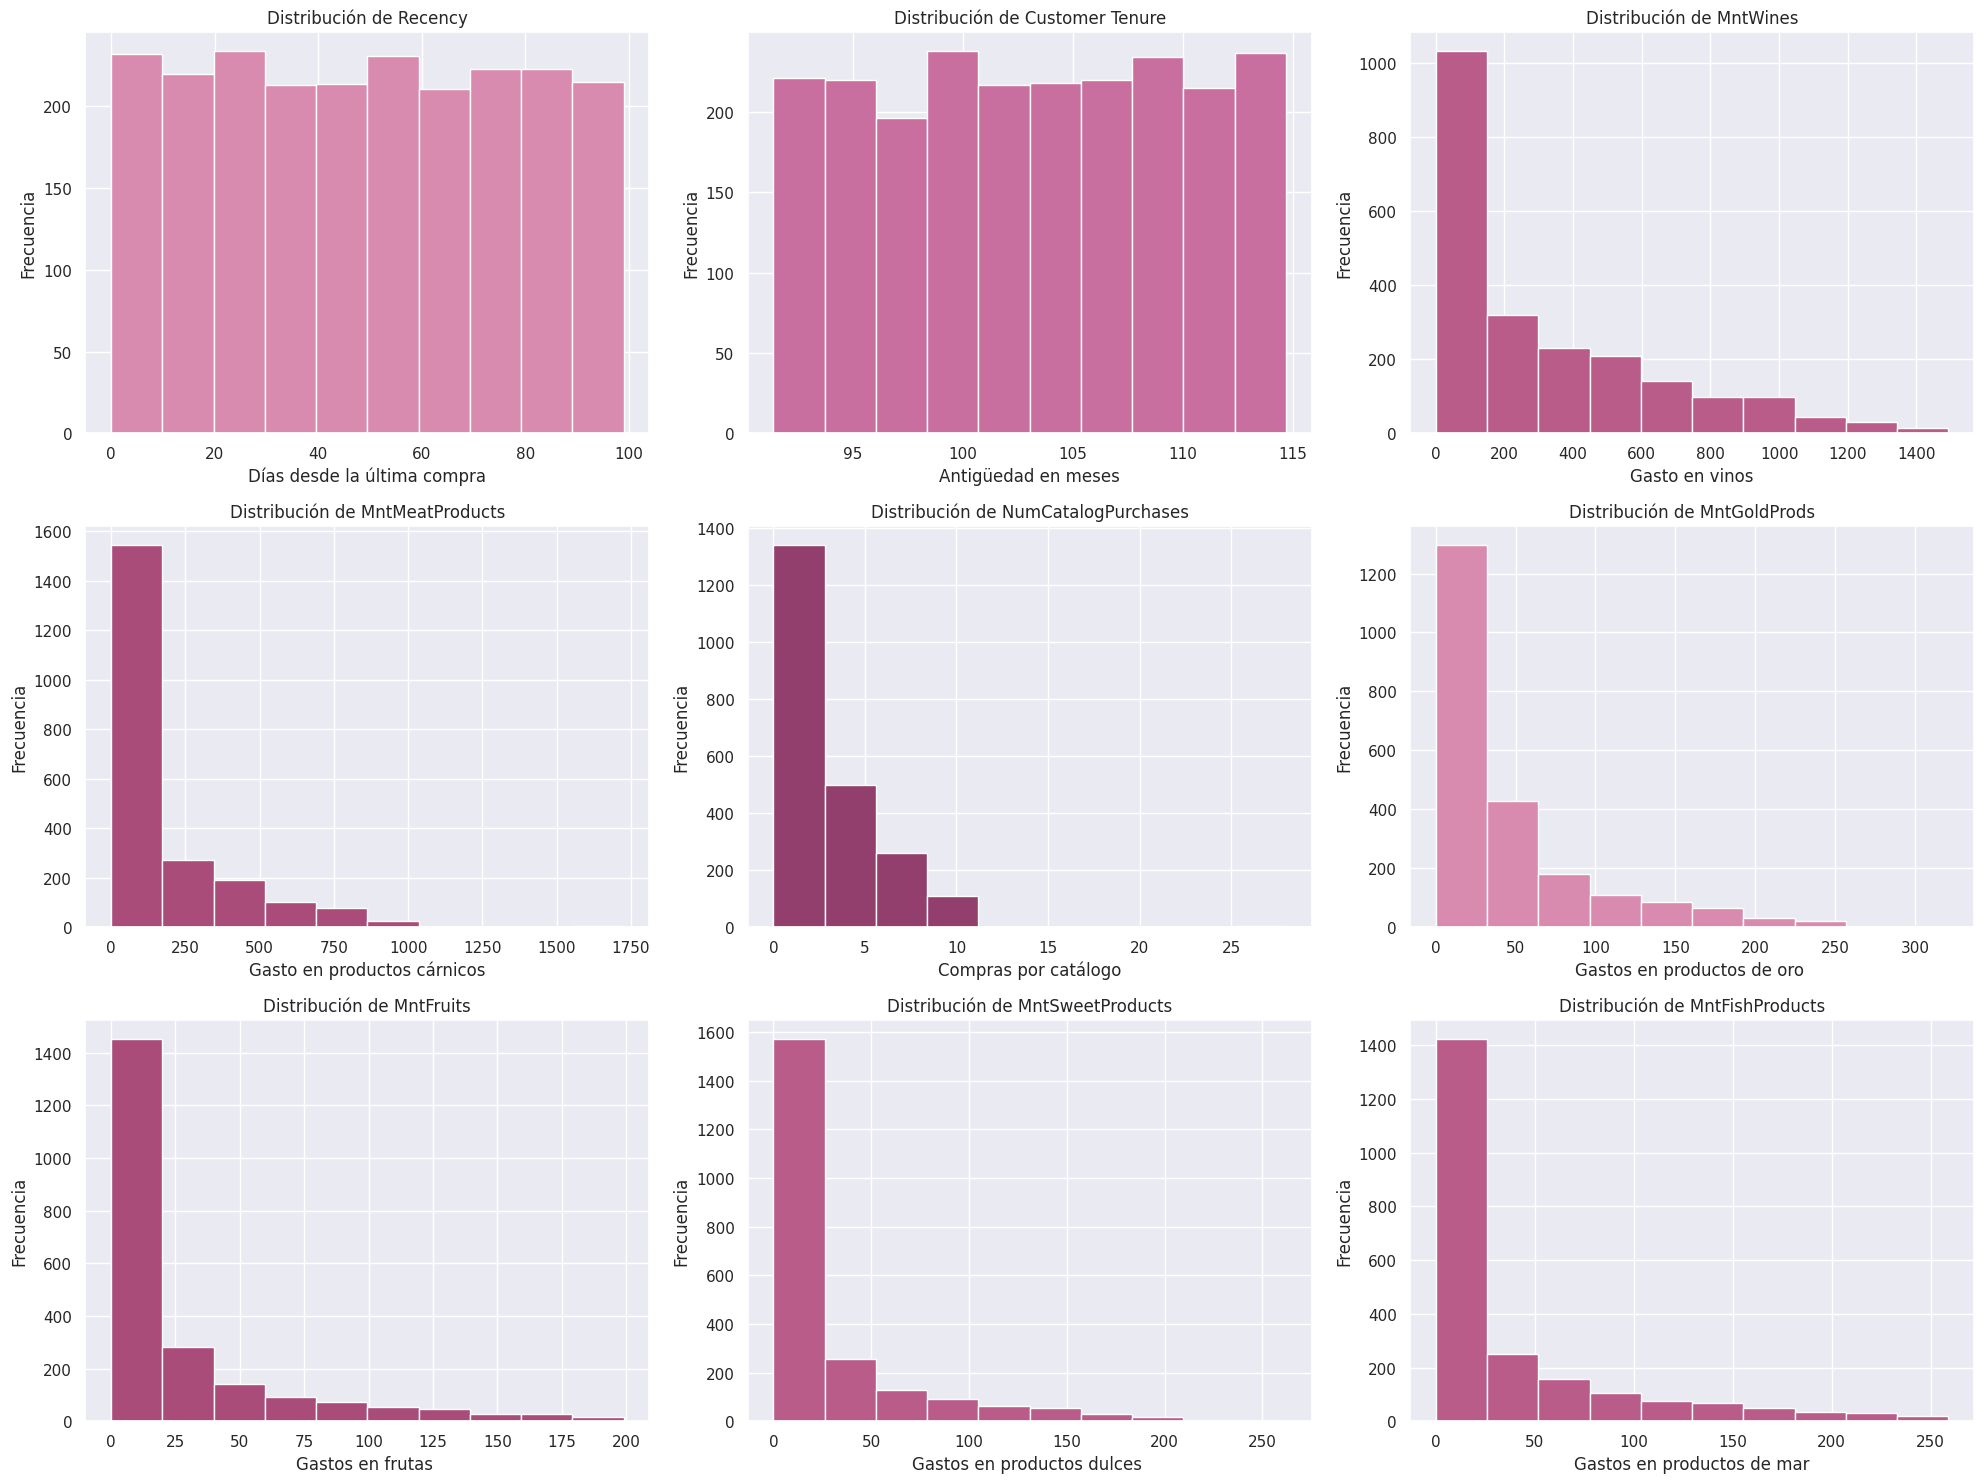

In [21]:
# Asimétricas

plt.figure(figsize=(20, 15))

ax=plt.subplot(3, 3, 1)
campañas.hist('Recency', color="#D98BAF", ax=ax);
plt.title('Distribución de Recency')
plt.xlabel('Días desde la última compra')
plt.ylabel('Frecuencia')

ax=plt.subplot(3, 3, 2)
campañas.hist('Customer_Tenure_Month', color="#C96F9F", ax=ax);
plt.title('Distribución de Customer Tenure')
plt.xlabel('Antigüedad en meses')
plt.ylabel('Frecuencia')

ax=plt.subplot(3, 3, 3)
campañas.hist('MntWines', color="#B95C8A", ax=ax);
plt.title('Distribución de MntWines')
plt.xlabel('Gasto en vinos')
plt.ylabel('Frecuencia')

ax=plt.subplot(3, 3, 4)
campañas.hist('MntMeatProducts', color="#A94C7A", ax=ax);
plt.title('Distribución de MntMeatProducts')
plt.xlabel('Gasto en productos cárnicos')
plt.ylabel('Frecuencia')

ax=plt.subplot(3, 3, 5)
campañas.hist('NumCatalogPurchases', color="#923F6D", ax=ax);
plt.title('Distribución de NumCatalogPurchases')
plt.xlabel('Compras por catálogo')
plt.ylabel('Frecuencia')

ax=plt.subplot(3, 3, 6)
campañas.hist('MntGoldProds', color="#D98BAF", ax=ax);
plt.title('Distribución de MntGoldProds')
plt.xlabel('Gastos en productos de oro ')
plt.ylabel('Frecuencia')

ax=plt.subplot(3, 3, 7)
campañas.hist('MntFruits', color="#A94C7A", ax=ax);
plt.title('Distribución de MntFruits')
plt.xlabel('Gastos en frutas ')
plt.ylabel('Frecuencia')

ax=plt.subplot(3, 3, 8)
campañas.hist('MntSweetProducts', color="#B95C8A", ax=ax);
plt.title('Distribución de MntSweetProducts')
plt.xlabel('Gastos en productos dulces ')
plt.ylabel('Frecuencia')

ax=plt.subplot(3, 3, 9)
campañas.hist('MntFishProducts', color="#B95C8A", ax=ax);
plt.title('Distribución de MntFishProducts')
plt.xlabel('Gastos en productos de mar')
plt.ylabel('Frecuencia')



plt.tight_layout()
plt.show()


**Estadísticas** (mediana y rango intercuartílico, robustos a outliers)


In [22]:
for col in ['Recency', 'Customer_Tenure_Month', 'MntWines', 'MntMeatProducts', 'NumCatalogPurchases',
            'NumDealsPurchases', 'MntGoldProds', 'MntFruits', 'MntSweetProducts', 'MntFishProducts']:
    Q1 = campañas[col].quantile(0.25)
    Q3 = campañas[col].quantile(0.75)
    IQR = Q3 - Q1          # dispersión de los datos alrededor de la mediana
    print("Variable:", col)
    print("Mediana:", campañas[col].median())
    print("IQR:", IQR)


Variable: Recency
Mediana: 49.0
IQR: 50.0
Variable: Customer_Tenure_Month
Mediana: 103.25
IQR: 11.599999999999994
Variable: MntWines
Mediana: 174.5
IQR: 481.0
Variable: MntMeatProducts
Mediana: 68.0
IQR: 216.25
Variable: NumCatalogPurchases
Mediana: 2.0
IQR: 4.0
Variable: NumDealsPurchases
Mediana: 2.0
IQR: 2.0
Variable: MntGoldProds
Mediana: 24.5
IQR: 47.0
Variable: MntFruits
Mediana: 8.0
IQR: 31.0
Variable: MntSweetProducts
Mediana: 8.0
IQR: 32.0
Variable: MntFishProducts
Mediana: 12.0
IQR: 47.0


## 7.7 Reporte de variables

**Categóricas:**
- La mayoría de los clientes tiene nivel educativo Graduation, con 1116
  casos (50.36%), seguido de PhD con 481 casos (21.71%).
- El estado civil más común es Married, con 857 casos (38.67%), seguido de
  Together con 573 casos (25.86%).
- Solo el 7.31% de los clientes (162 casos) aceptó la campaña 5; el 92.69%
  restante no lo hizo.
- Solo el 6.41% de los clientes (142 casos) aceptó la campaña 1.
- Solo el 7.36% de los clientes (163 casos) aceptó la campaña 3.
- Solo el 7.40% de los clientes (164 casos) aceptó la campaña 4.
- La campaña 2 tuvo la menor aceptación de todas: apenas el 1.35% (30 casos).
- El 51.76% de los clientes no tiene adolescentes en casa, el 45.94% tiene
  uno, y solo el 2.30% tiene dos.

**Numéricas asimétricas:**
- `MntWines` tiene una mediana de 174.5 y un rango intercuartílico de 481,
  reflejando gran dispersión: mientras la mitad de los clientes gasta poco,
  un grupo reducido gasta montos muy altos en vino.
- `MntMeatProducts` tiene una mediana de 68 y un IQR de 216.25, con el mismo
  patrón de gasto concentrado en pocos clientes.
- `NumCatalogPurchases` tiene una mediana de apenas 2 compras y un IQR de 4,
  mostrando que la mayoría de clientes usa poco este canal.
- `MntGoldProds` tiene una mediana de 24.5 y un IQR de 47.
- `MntFruits` tiene una mediana de 8 y un IQR de 31.
- `MntSweetProducts` tiene una mediana de 8 y un IQR de 32.
- `MntFishProducts` tiene una mediana de 12 y un IQR de 47.

**Numéricas con distribución uniforme:**
- `Recency` tiene una mediana de 49 días y un IQR de 50, con una distribución
  aproximadamente pareja entre 0 y 100 días — no hay un grupo dominante de
  clientes "recientes" ni "antiguos".
- `Customer_Tenure_Month` tiene una mediana de 103.25 meses y un IQR de 11.6,
  también con forma casi uniforme dentro de su rango.


## 7.8 Conclusiones del EDA

1. `Response` está fuertemente desbalanceada (85% / 15%), lo que deberá
   tenerse en cuenta al evaluar cualquier modelo futuro con métricas más allá
   de la exactitud.
2. El mejor predictor visual e individual de `Response` es haber aceptado
   campañas anteriores (`AcceptedCmp5`, `AcceptedCmp1`, `AcceptedCmp3`), con
   saltos de hasta 44 puntos porcentuales en la tasa de respuesta, lo que sugiere
   que el historial de aceptación es más informativo que el nivel de gasto.
3. Las variables de gasto por categoría de producto (`MntWines`,
   `MntMeatProducts`, etc.) comparten un patrón asimétrico: la mayoría de
   clientes gasta poco y una minoría concentra montos altos, típico de datos
   de consumo.
4. `Recency` y `Customer_Tenure_Month` no encajan en el patrón esperado de
   asimetría, se distribuyen de forma casi uniforme, lo que indica que no
   hay un "tipo de cliente" dominante según antigüedad o recencia de compra.


# 8. Clasificación **sin** campañas anteriores
Primer escenario: los modelos **no** usan `AcceptedCmp1`–`AcceptedCmp5`, de modo que solo dependen del perfil y del comportamiento de compra del cliente. Se comparan `GaussianNB`, árbol de decisión, Random Forest y SVM, con partición estratificada 60 % entrenamiento / 20 % validación / 20 % prueba.

## 8.1 Selección de variables y partición de los datos


In [23]:
campañas = campañas.drop(columns=['Income', 'NumWebPurchases', 'Age', 'NumDealsPurchases', 'NumWebVisitsMonth', 'Year_Birth', 'NumStorePurchases', 'Complain', 'Kidhome', 'Dt_Customer'])
campañas.head(5)


,Education,Marital_Status,Teenhome,Recency,MntWines,MntFruits,MntMeatProducts,MntFishProducts,MntSweetProducts,MntGoldProds,NumCatalogPurchases,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Response,Customer_Tenure_Month
730,PhD,Divorced,1,24,8,0,3,0,0,0,0,0,0,0,0,0,0,100.6
1963,Graduation,Single,1,32,50,4,44,10,10,43,1,0,0,0,0,0,1,105.4
153,Graduation,Alone,0,12,5,7,24,19,14,20,0,0,0,0,0,0,0,93.0
1078,Master,Single,0,9,234,14,77,19,10,42,1,0,0,0,0,0,0,96.7
1784,Graduation,Together,1,8,199,33,60,8,3,15,2,0,0,0,0,0,1,109.5


In [24]:
y = campañas['Response'].copy()
display(y.head())
campañas_dataset= ['AcceptedCmp3',	'AcceptedCmp4',	'AcceptedCmp5',	'AcceptedCmp1',	'AcceptedCmp2']
X_sin_campañas= campañas.drop(columns=['Response']+ campañas_dataset).copy()
display(X_sin_campañas.head())
X= X_sin_campañas

X_dev_sin, X_test_sin, y_dev_sin, y_test_sin = train_test_split(X, y, test_size=0.2, stratify=y, random_state=SEED)
X_train_sin, X_val_sin, y_train_sin, y_val_sin = train_test_split(X_dev_sin, y_dev_sin, test_size=0.25, stratify=y_dev_sin, random_state=SEED)

print(f"Train: {len(y_train_sin)} | Validación: {len(y_val_sin)} | Test: {len(y_test_sin)}")
display(y_train_sin.value_counts().sort_index().rename('Train: muestras por Response'))


,Response
730,0
1963,1
153,0
1078,0
1784,1


,Education,Marital_Status,Teenhome,Recency,MntWines,MntFruits,MntMeatProducts,MntFishProducts,MntSweetProducts,MntGoldProds,NumCatalogPurchases,Customer_Tenure_Month
730,PhD,Divorced,1,24,8,0,3,0,0,0,0,100.6
1963,Graduation,Single,1,32,50,4,44,10,10,43,1,105.4
153,Graduation,Alone,0,12,5,7,24,19,14,20,0,93.0
1078,Master,Single,0,9,234,14,77,19,10,42,1,96.7
1784,Graduation,Together,1,8,199,33,60,8,3,15,2,109.5


Train: 1329 | Validación: 443 | Test: 444


,Train: muestras por Response
Response,
0,1130
1,199


## 8.2 Codificación de variables categóricas (one-hot)


In [25]:
X_train_sin = pd.get_dummies(X_train_sin, columns=["Education", "Marital_Status"], dtype=int)
X_val_sin = pd.get_dummies(X_val_sin, columns=["Education", "Marital_Status"], dtype=int)
X_test_sin = pd.get_dummies(X_test_sin, columns=["Education", "Marital_Status"], dtype=int)

X_val_sin = X_val_sin.reindex(columns=X_train_sin.columns, fill_value=0)
X_test_sin = X_test_sin.reindex(columns=X_train_sin.columns, fill_value=0)

print("Entrenamiento:", X_train_sin.shape)
print("Validación:", X_val_sin.shape)
print("Prueba:", X_test_sin.shape)


Entrenamiento: (1329, 23)
Validación: (443, 23)
Prueba: (444, 23)


## 8.3 Línea base (hiperparámetros por defecto)


In [26]:
modelo = GaussianNB()
modelo.fit(X_train_sin, y_train_sin)
y_pred_GNBsin = modelo.predict(X_val_sin)

print(f"Predicciones reales: {y_val_sin[:10]}")
print(" ")
print(f"Predicciones: {y_pred_GNBsin[:10]}")

acc_gnb= accuracy_score(y_val_sin, y_pred_GNBsin)
pre_gnb= precision_score(y_val_sin, y_pred_GNBsin)
rec_gnb= recall_score(y_val_sin, y_pred_GNBsin)
f1_gnb= f1_score(y_val_sin, y_pred_GNBsin)

print(" ")
print(f"Accuracy GNB sin campañas:  {acc_gnb:.3f}")
print(f"Precision GNB sin campañas: {pre_gnb:.3f}")
print(f"Recall GNB sin campañas: {rec_gnb:.3f}")
print(f"F1-score GNB sin campañas: {f1_gnb:.3f}")


Predicciones reales: 532     0
1600    0
1649    0
1911    0
1651    1
1120    0
1725    1
1093    0
673     0
1587    0
Name: Response, dtype: int64
 
Predicciones: [0 0 0 1 1 0 0 0 0 0]
 
Accuracy GNB sin campañas:  0.824
Precision GNB sin campañas: 0.415
Recall GNB sin campañas: 0.403
F1-score GNB sin campañas: 0.409


In [27]:
dt_sin = DecisionTreeClassifier(max_depth=2, random_state=SEED)
dt_sin.fit(X_train_sin, y_train_sin)
y_pred_dtsin = dt_sin.predict(X_val_sin)

acc_dt= accuracy_score(y_val_sin, y_pred_dtsin)
pre_dt= precision_score(y_val_sin, y_pred_dtsin, zero_division=0)
rec_dt= recall_score(y_val_sin, y_pred_dtsin)
f1_dt= f1_score(y_val_sin, y_pred_dtsin)

print(f"Accuracy dt sin campañas:  {acc_dt:.3f}")
print(f"Precision dt sin campañas: {pre_dt:.3f}")
print(f"Recall dt sin campañas: {rec_dt:.3f}")
print(f"F1-score dt sin campañas: {f1_dt:.3f}")


Accuracy dt sin campañas:  0.849
Precision dt sin campañas: 0.000
Recall dt sin campañas: 0.000
F1-score dt sin campañas: 0.000


In [28]:
rf_sin = RandomForestClassifier(n_estimators=100, random_state=SEED, n_jobs=-2)
rf_sin.fit(X_train_sin, y_train_sin)
y_pred_rfsin = rf_sin.predict(X_val_sin)

acc_rf= accuracy_score(y_val_sin, y_pred_rfsin)
pre_rf= precision_score(y_val_sin, y_pred_rfsin)
rec_rf= recall_score(y_val_sin, y_pred_rfsin)
f1_rf= f1_score(y_val_sin, y_pred_rfsin)

print(f"Accuracy rf sin campañas:  {acc_rf:.3f}")
print(f"Precision rf sin campañas: {pre_rf:.3f}")
print(f"Recall rf sin campañas: {rec_rf:.3f}")
print(f"F1-score rf sin campañas: {f1_rf:.3f}")


Accuracy rf sin campañas:  0.860
Precision rf sin campañas: 0.647
Recall rf sin campañas: 0.164
F1-score rf sin campañas: 0.262


In [29]:
svm= make_pipeline(StandardScaler(), SVC(kernel='rbf', C=1.0, gamma='scale', random_state=SEED))
svm.fit(X_train_sin, y_train_sin)
y_pred_svmsin = svm.predict(X_val_sin)

acc_svm= accuracy_score(y_val_sin, y_pred_svmsin)
pre_svm= precision_score(y_val_sin, y_pred_svmsin)
rec_svm= recall_score(y_val_sin, y_pred_svmsin)
f1_svm= f1_score(y_val_sin, y_pred_svmsin)

print(f"Accuracy SVM sin campañas:  {acc_svm:.3f}")
print(f"Precision SVM sin campañas: {pre_svm:.3f}")
print(f"Recall SVM sin campañas: {rec_svm:.3f}")
print(f"F1-score SVM sin campañas: {f1_svm:.3f}")


Accuracy SVM sin campañas:  0.858
Precision SVM sin campañas: 0.750
Recall SVM sin campañas: 0.090
F1-score SVM sin campañas: 0.160


## 8.4 Ajuste de hiperparámetros con validación cruzada
Validación cruzada estratificada de 10 folds sobre el conjunto de entrenamiento; la métrica principal es el **F1 de la clase 1** (cliente que acepta), por el desbalance de `Response`.

### Configuración y función auxiliar


In [30]:
cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=SEED)
scoring = {"Accuracy": "accuracy","Precision": make_scorer(precision_score, pos_label=1, zero_division= 0),
    "Recall": make_scorer(recall_score, pos_label=1, zero_division= 0),
    "F1": make_scorer(f1_score, pos_label=1, zero_division=0)}


In [31]:
def variaciones(nombre, valores, crear_modelo, log=False, etiquetas=None):
    pal = cafe_palette_1
    filas = []
    for v in valores:
        sc = cross_validate(crear_modelo(v), X_train_sin, y_train_sin, cv=cv, scoring=scoring,
                            return_train_score=True, n_jobs=-2)
        filas.append({nombre: v if etiquetas is None else str(v),
                      'F1 train': sc['train_F1'].mean(),
                      'F1 CV': sc['test_F1'].mean(),
                      'desv. CV': sc['test_F1'].std(),
                      'Precision': sc['test_Precision'].mean(),
                      'Recall': sc['test_Recall'].mean()})
    df = pd.DataFrame(filas)
    df['Brecha'] = df['F1 train'] - df['F1 CV']
    if etiquetas is not None:
        df[nombre] = etiquetas
    display(df.round(3))

    x = np.arange(len(df)) if etiquetas is not None else df[nombre].values
    fig, (a1, a2) = plt.subplots(1, 2, figsize=(14, 5))
    a1.plot(x, df['F1 train'], marker='o', color=pal[0], label='Train')
    a1.errorbar(x, df['F1 CV'], yerr=df['desv. CV'], marker='s', capsize=4,
                color=pal[1], label='Validación cruzada')
    a1.fill_between(x, df['F1 CV'], df['F1 train'], alpha=0.15, color=pal[3], label='brecha')
    a2.plot(x, df['Precision'], marker='o', color=pal[0], label='Precisión CV')
    a2.plot(x, df['Recall'],    marker='s', color=pal[1], label='Recall CV')
    a2.plot(x, df['F1 CV'],     marker='^', color=pal[3], label='F1 CV')
    for a in (a1, a2):
        if etiquetas is not None:
            a.set_xticks(x)
            a.set_xticklabels(etiquetas)
        elif log:
            a.set_xscale('log')
        a.set_xlabel(nombre)
        a.grid(alpha=0.3)
        a.legend()
    a1.set_ylabel('F1 clase 1')
    a1.set_title(f'Train vs CV según {nombre}')
    a2.set_title('Comparación de métricas según valores')
    plt.tight_layout()
    plt.show()


### GaussianNB


,var_smoothing,F1 train,F1 CV,desv. CV,Precision,Recall,Brecha
0,0.000,0.245,0.218,0.052,0.451,0.216,0.027
1,0.000,0.390,0.369,0.089,0.398,0.367,0.021
2,0.000,0.413,0.405,0.088,0.353,0.482,0.008
3,0.001,0.347,0.343,0.076,0.315,0.382,0.004
4,0.010,0.332,0.330,0.073,0.331,0.337,0.002
5,0.100,0.291,0.285,0.074,0.414,0.226,0.006
6,1.000,0.034,0.029,0.044,0.300,0.015,0.006


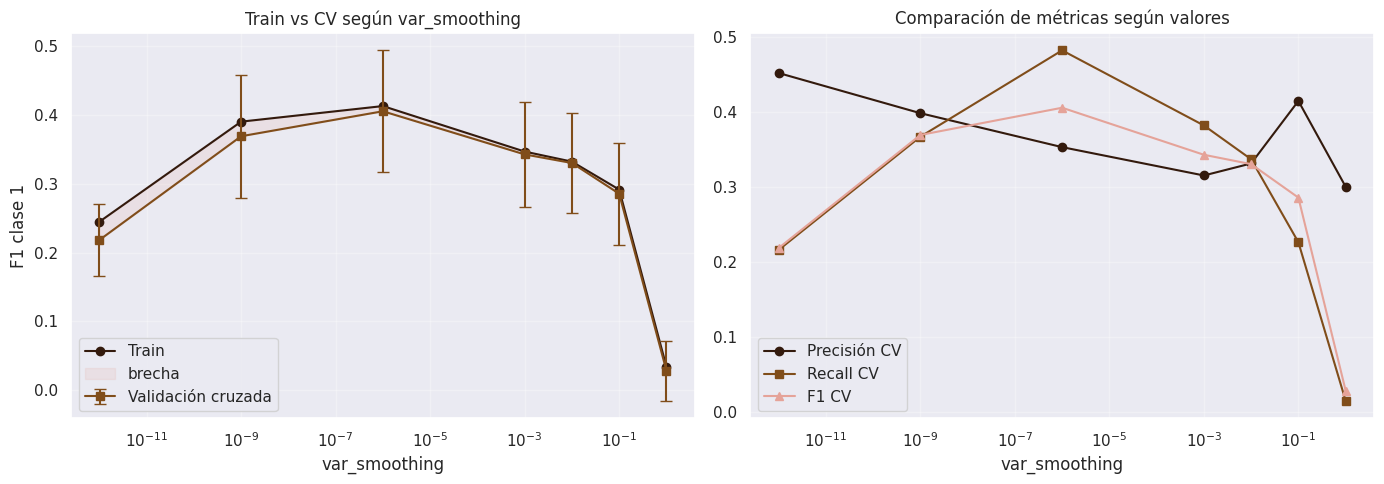

,priors,F1 train,F1 CV,desv. CV,Precision,Recall,Brecha
0,Proporcion clases: 85/15,0.413,0.405,0.088,0.353,0.482,0.008
1,70/30,0.388,0.387,0.078,0.312,0.517,0.001
2,50/50 balanceo manual,0.382,0.372,0.081,0.280,0.557,0.010


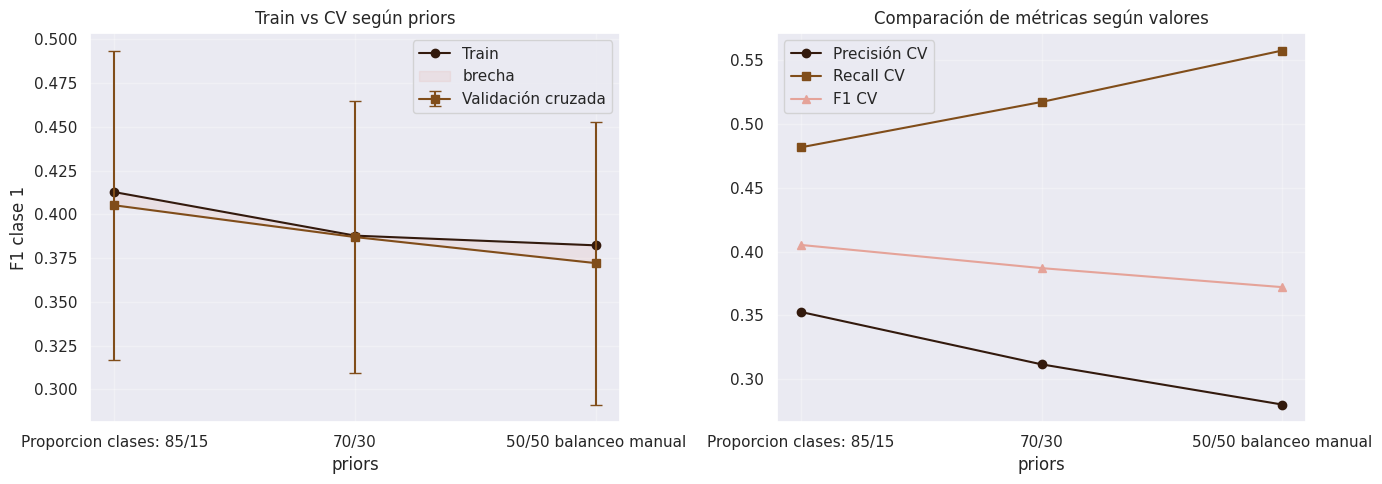

In [32]:
variaciones('var_smoothing', [1e-12, 1e-9, 1e-6, 1e-3, 1e-2, 1e-1, 1],
        lambda v: GaussianNB(var_smoothing=v), log=True)

variaciones('priors', [None, [0.7, 0.3], [0.5, 0.5]],
        lambda v: GaussianNB(priors=v, var_smoothing=1e-6),
        etiquetas=['Proporcion clases: 85/15', '70/30', '50/50 balanceo manual'])




### Árbol de decisión


,class_weight dt,F1 train,F1 CV,desv. CV,Precision,Recall,Brecha
0,Sin balanceo,0.545,0.325,0.094,0.403,0.286,0.220
1,con balanceo,0.537,0.443,0.048,0.318,0.744,0.093


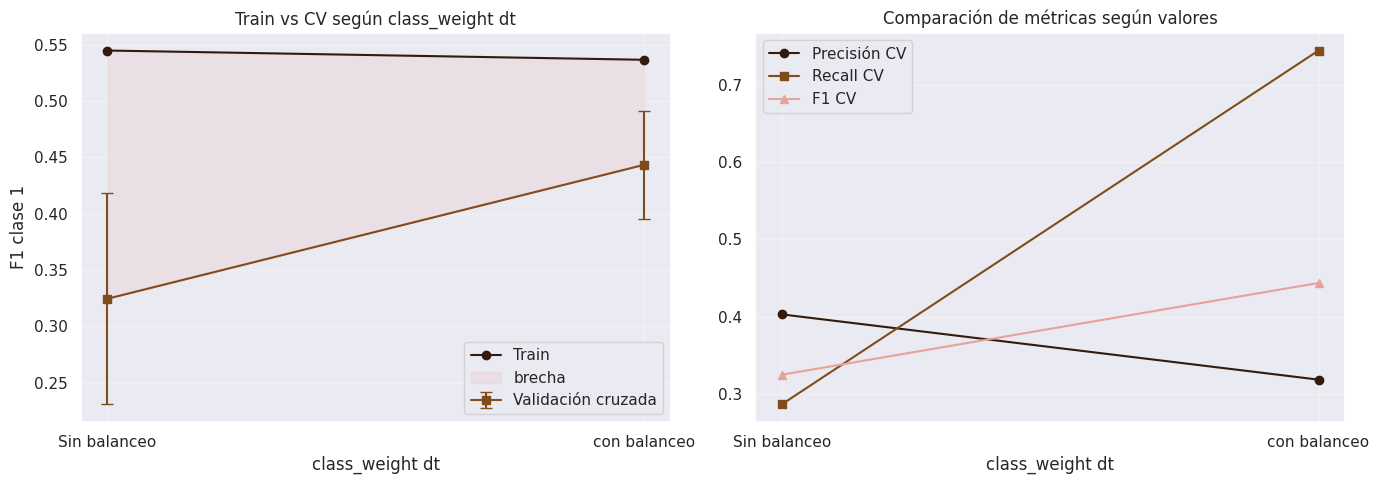

,max_depth dt,F1 train,F1 CV,desv. CV,Precision,Recall,Brecha
0,1,0.319,0.320,0.021,0.193,0.939,-0.001
1,2,0.388,0.305,0.090,0.227,0.496,0.083
2,3,0.410,0.369,0.041,0.241,0.794,0.041
3,4,0.488,0.414,0.053,0.287,0.764,0.074
4,5,0.537,0.443,0.048,0.318,0.744,0.093
5,6,0.600,0.443,0.044,0.323,0.714,0.157
6,7,0.665,0.441,0.066,0.340,0.644,0.224
7,8,0.743,0.423,0.061,0.340,0.569,0.320
8,9,0.815,0.448,0.069,0.384,0.543,0.367
9,10,0.867,0.429,0.061,0.381,0.498,0.437


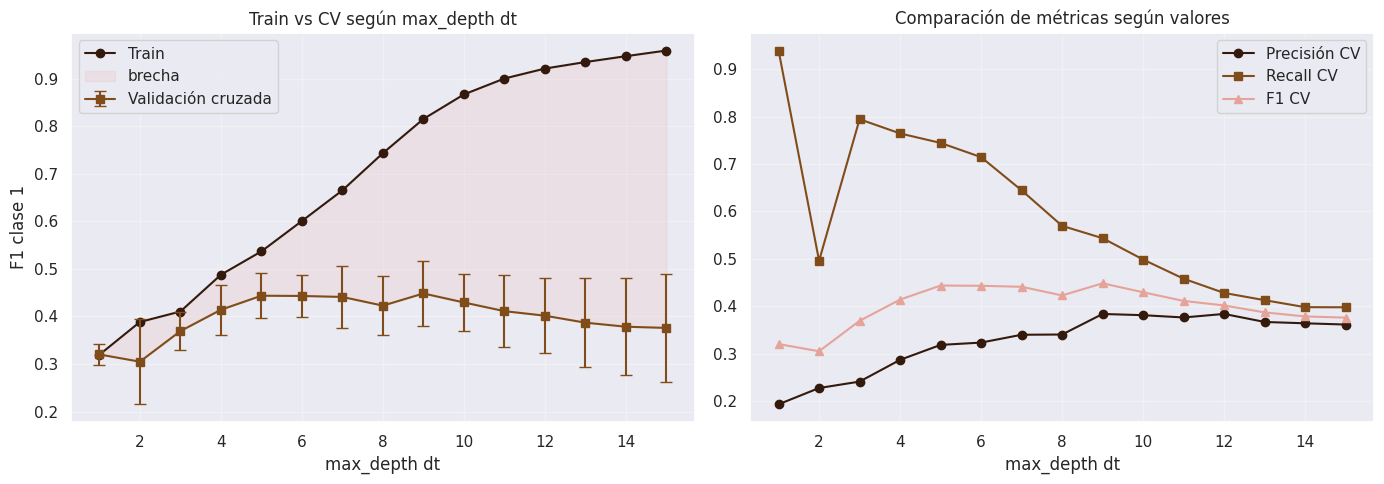

In [33]:
variaciones('class_weight dt', [None, 'balanced'],
        lambda v: DecisionTreeClassifier(max_depth=5, class_weight=v, random_state=SEED),
        etiquetas=['Sin balanceo', 'con balanceo'])

variaciones('max_depth dt', range(1, 16),
        lambda v: DecisionTreeClassifier(max_depth=v, class_weight='balanced', random_state=SEED))



### Random Forest


,class_weight rf,F1 train,F1 CV,desv. CV,Precision,Recall,Brecha
0,Sin balanceo,0.748,0.279,0.120,0.802,0.176,0.469
1,con balanceo,0.948,0.436,0.089,0.571,0.362,0.512
2,balanced_subsample,0.945,0.449,0.096,0.614,0.362,0.496


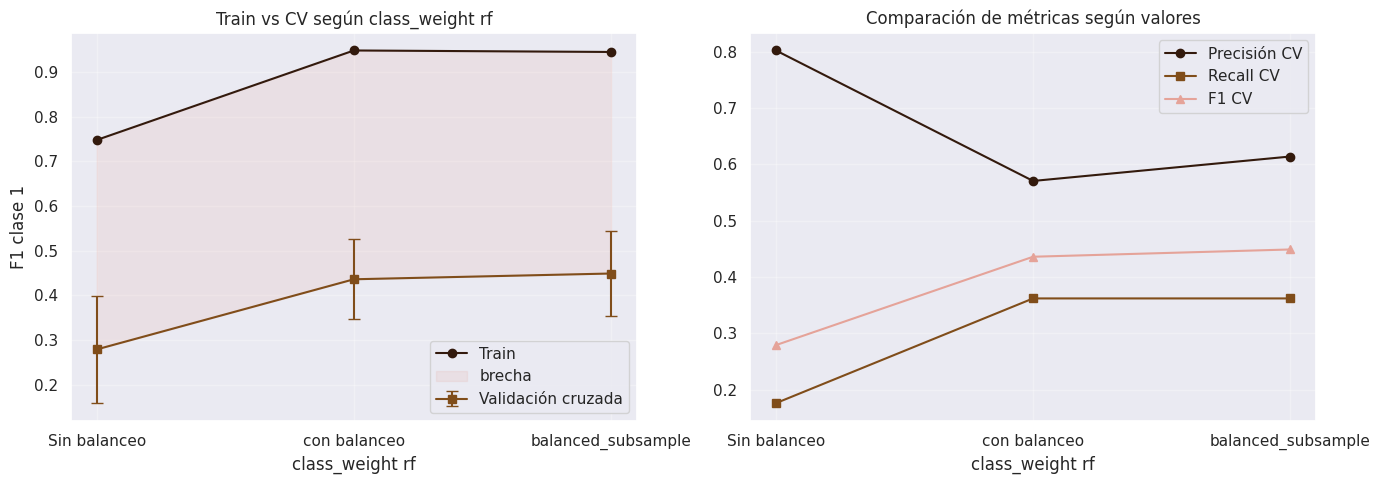

,max_depth rf,F1 train,F1 CV,desv. CV,Precision,Recall,Brecha
0,2,0.440,0.392,0.052,0.277,0.678,0.048
1,3,0.499,0.443,0.046,0.325,0.703,0.056
2,4,0.587,0.488,0.058,0.382,0.684,0.099
3,5,0.708,0.508,0.073,0.438,0.613,0.201
4,6,0.805,0.518,0.100,0.512,0.533,0.287
5,7,0.886,0.486,0.098,0.540,0.453,0.400
6,8,0.948,0.436,0.089,0.571,0.362,0.512
7,10,0.985,0.364,0.083,0.652,0.256,0.621


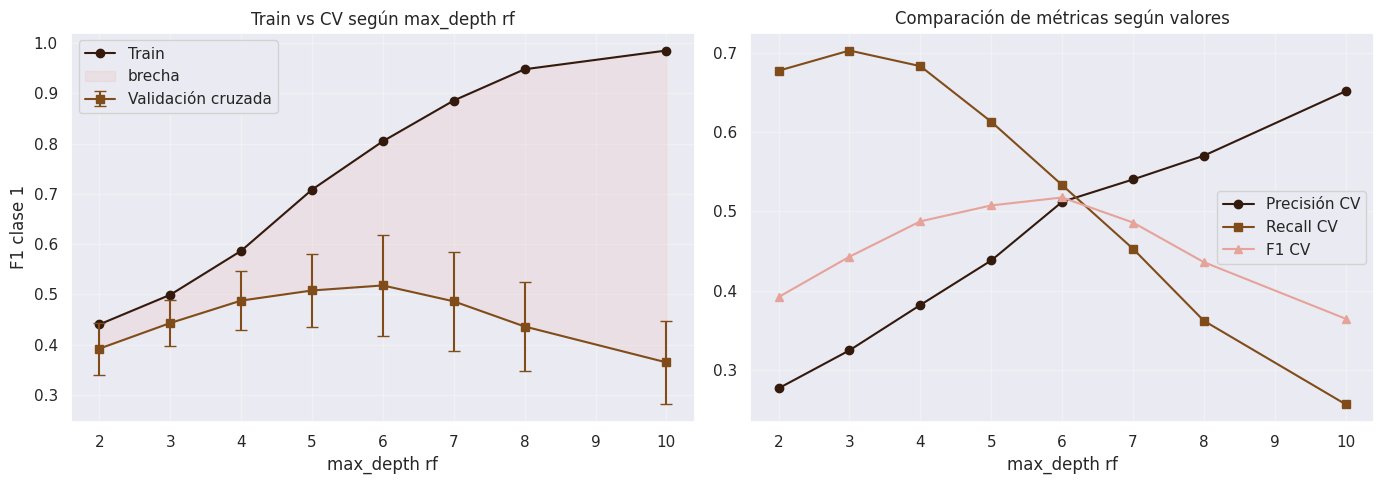

,n_estimators rf,F1 train,F1 CV,desv. CV,Precision,Recall,Brecha
0,50,0.692,0.483,0.082,0.411,0.593,0.209
1,100,0.708,0.508,0.073,0.438,0.613,0.201
2,150,0.708,0.509,0.077,0.438,0.618,0.199
3,200,0.710,0.506,0.079,0.443,0.603,0.204
4,300,0.709,0.523,0.084,0.462,0.618,0.186


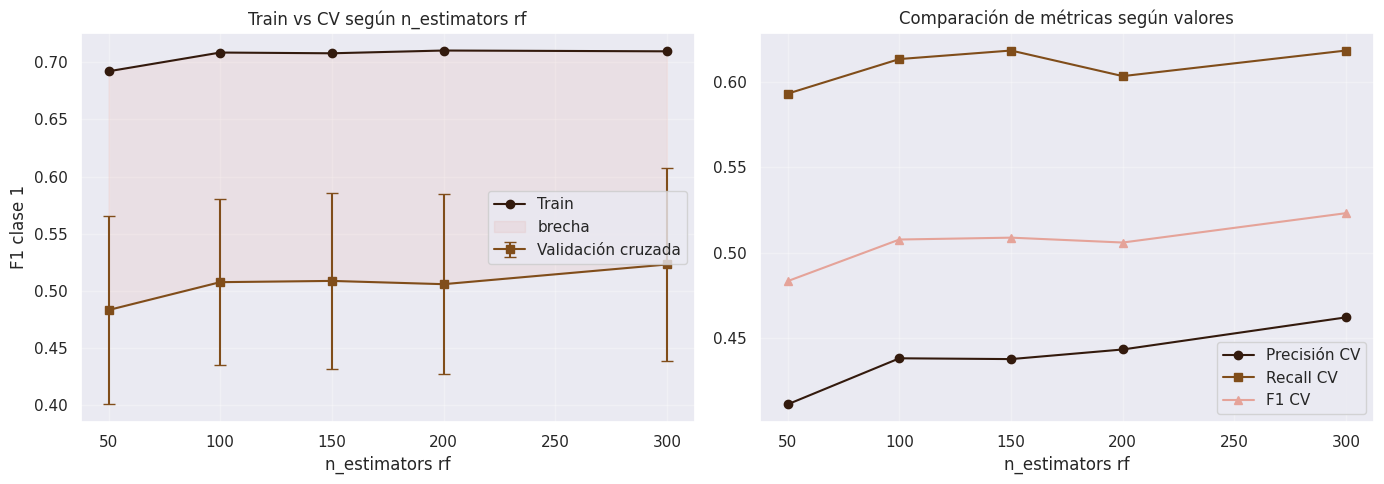

In [34]:
variaciones('class_weight rf', [None, 'balanced', 'balanced_subsample'],
        lambda v: RandomForestClassifier(n_estimators=100, max_depth=8, class_weight=v,
                                         random_state=SEED, n_jobs=-2),
        etiquetas=['Sin balanceo', 'con balanceo', 'balanced_subsample'])

variaciones('max_depth rf', [2, 3, 4, 5, 6, 7, 8, 10],
        lambda v: RandomForestClassifier(n_estimators=100, max_depth=v, class_weight='balanced',
                                         random_state=SEED, n_jobs=-2))

variaciones('n_estimators rf', [50, 100, 150, 200, 300],
        lambda v: RandomForestClassifier(n_estimators=v, max_depth=5, class_weight='balanced',
                                         random_state=SEED, n_jobs=-2))

### SVM


,class_weight svm,F1 train,F1 CV,desv. CV,Precision,Recall,Brecha
0,Sin balanceo,0.438,0.271,0.082,0.805,0.166,0.166
1,con balanceo,0.609,0.475,0.043,0.359,0.714,0.134


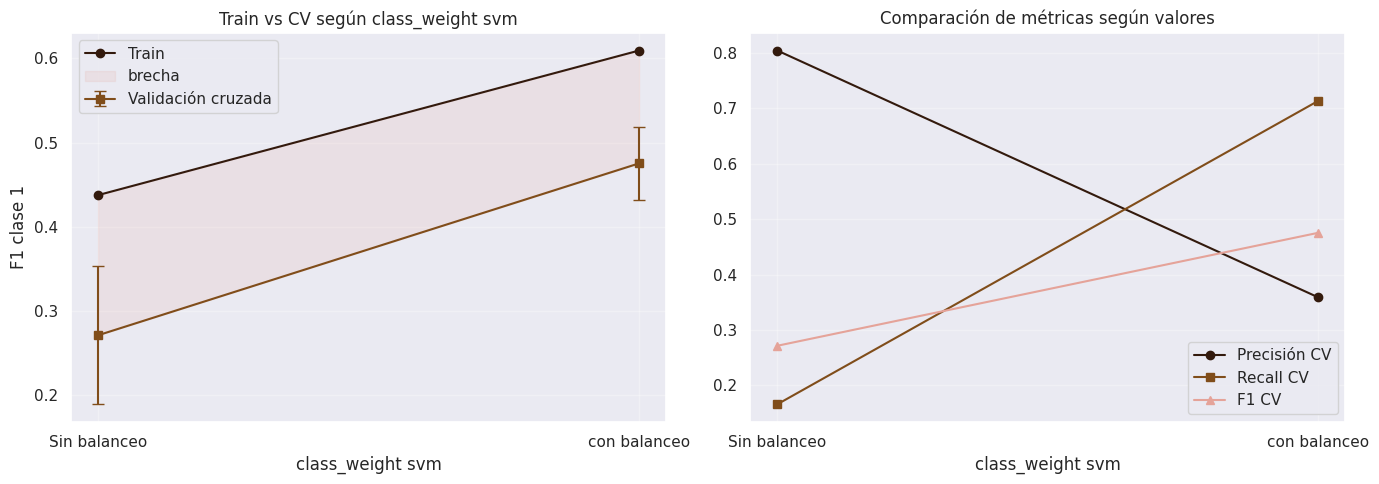

,C svm,F1 train,F1 CV,desv. CV,Precision,Recall,Brecha
0,0.1,0.481,0.442,0.052,0.316,0.739,0.039
1,1.0,0.609,0.475,0.043,0.359,0.714,0.134
2,10.0,0.788,0.453,0.055,0.389,0.543,0.335
3,100.0,0.904,0.478,0.093,0.458,0.502,0.426
4,300.0,0.940,0.436,0.103,0.423,0.451,0.504


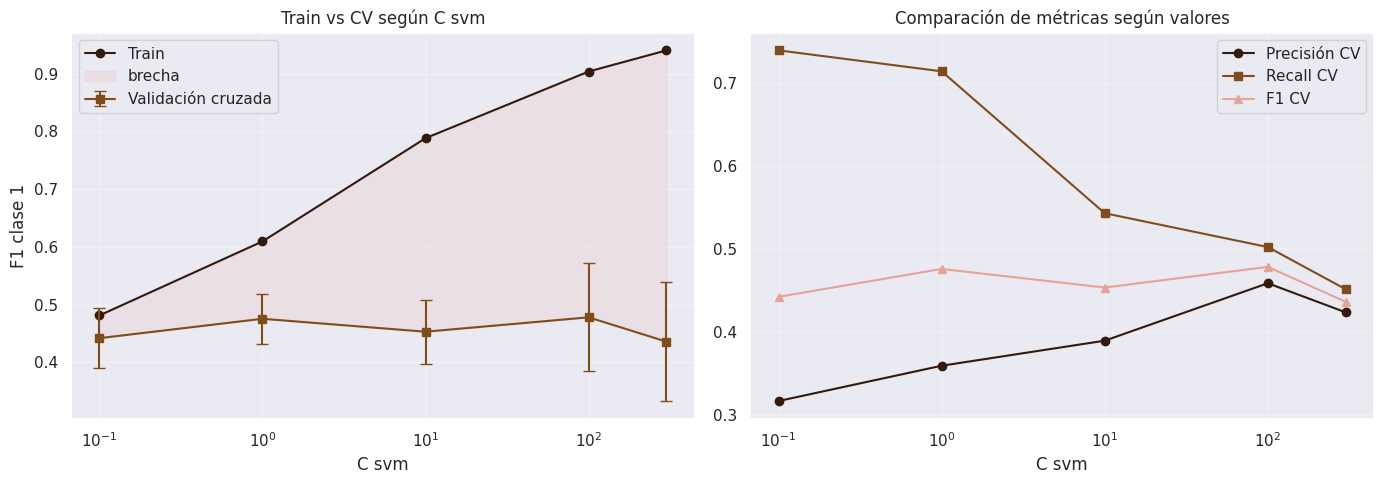

,kernel svm,F1 train,F1 CV,desv. CV,Precision,Recall,Brecha
0,linear,0.495,0.460,0.047,0.336,0.734,0.035
1,poly,0.683,0.475,0.117,0.416,0.558,0.208
2,rbf,0.609,0.475,0.043,0.359,0.714,0.134
3,sigmoid,0.338,0.338,0.048,0.235,0.608,-0.000


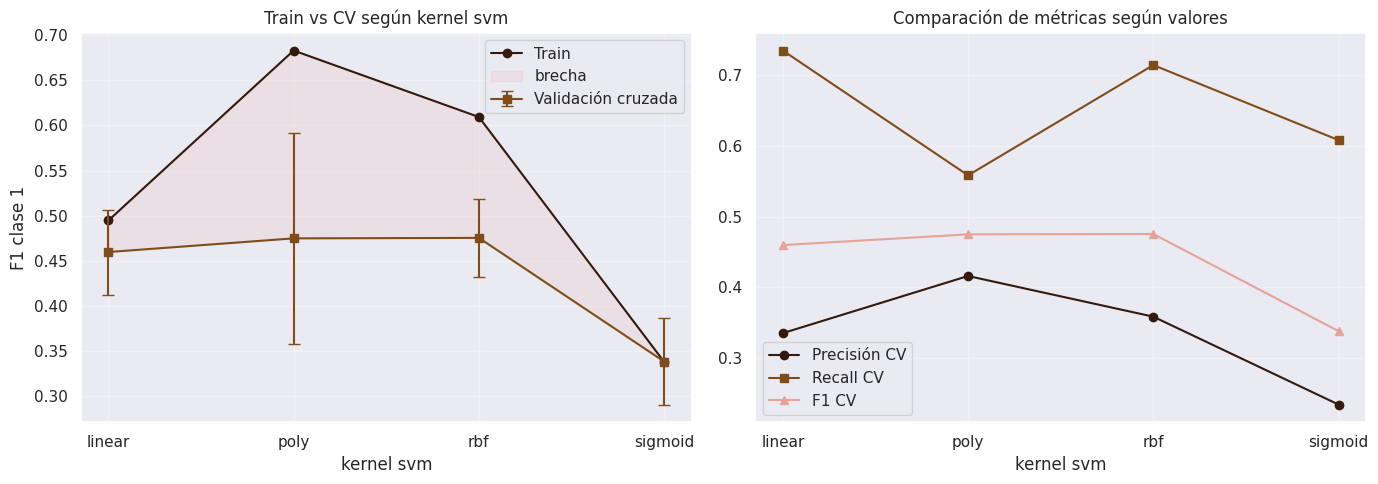

,C svm lineal,F1 train,F1 CV,desv. CV,Precision,Recall,Brecha
0,0.01,0.499,0.469,0.043,0.346,0.729,0.030
1,0.10,0.496,0.454,0.045,0.330,0.734,0.041
2,1.00,0.495,0.460,0.047,0.336,0.734,0.035
3,10.00,0.496,0.460,0.047,0.336,0.734,0.036


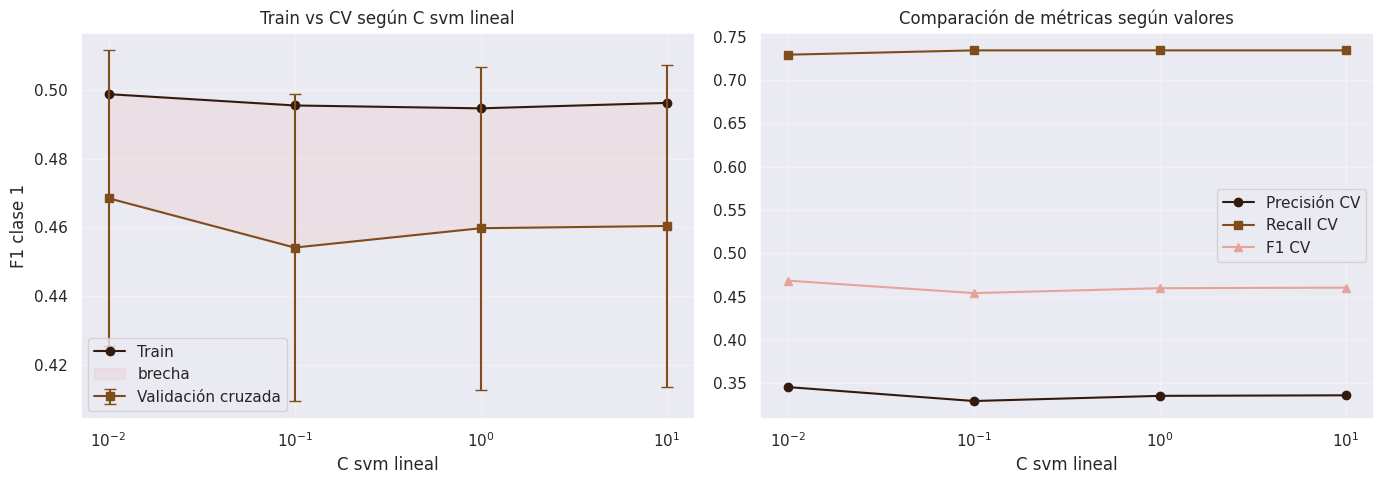

In [36]:


variaciones('class_weight svm', [None, 'balanced'],
        lambda v: make_pipeline(StandardScaler(), SVC( class_weight=v, random_state=SEED, C=1.0, gamma='scale',kernel='rbf')),
        etiquetas=['Sin balanceo', 'con balanceo'])
variaciones('C svm', [0.1, 1, 10, 100, 300],
        lambda v: make_pipeline(StandardScaler(), SVC(C=v, gamma='scale', class_weight='balanced', random_state=SEED,kernel='rbf')),
        log=True)

# Valor elegido: C = 1.0

variaciones('kernel svm', ['linear', 'poly', 'rbf', 'sigmoid'],
        lambda v: make_pipeline(StandardScaler(), SVC(kernel=v, C=1.0, gamma='scale',   class_weight='balanced',random_state=SEED)),
        etiquetas=['linear', 'poly', 'rbf', 'sigmoid'])
# Valor elegido: kernel = 'linear'
variaciones('C svm lineal', [0.01, 0.1, 1, 10],
        lambda v: make_pipeline(StandardScaler(), SVC(kernel='linear', C=v,
                                                      class_weight='balanced', random_state=SEED)),
        log=True)

## 8.5 Modelos con los hiperparámetros elegidos (conjunto de validación)


In [35]:
modelo = GaussianNB(var_smoothing=1e-6)
modelo.fit(X_train_sin, y_train_sin)
y_pred_GNBsin = modelo.predict(X_val_sin)
acc_gnb= accuracy_score(y_val_sin, y_pred_GNBsin)
pre_gnb= precision_score(y_val_sin, y_pred_GNBsin)
rec_gnb= recall_score(y_val_sin, y_pred_GNBsin)
f1_gnb= f1_score(y_val_sin, y_pred_GNBsin)

dt_sin = DecisionTreeClassifier(max_depth=3, random_state=SEED, class_weight= 'balanced')
dt_sin.fit(X_train_sin, y_train_sin)
y_pred_dtsin = dt_sin.predict(X_val_sin)
acc_dt= accuracy_score(y_val_sin, y_pred_dtsin)
pre_dt= precision_score(y_val_sin, y_pred_dtsin)
rec_dt= recall_score(y_val_sin, y_pred_dtsin)
f1_dt= f1_score(y_val_sin, y_pred_dtsin)

rf_sin = RandomForestClassifier(n_estimators=300, max_depth=4, random_state=SEED, n_jobs=-2, class_weight='balanced')
rf_sin.fit(X_train_sin, y_train_sin)
y_pred_rfsin = rf_sin.predict(X_val_sin)
acc_rf= accuracy_score(y_val_sin, y_pred_rfsin)
pre_rf= precision_score(y_val_sin, y_pred_rfsin)
rec_rf= recall_score(y_val_sin, y_pred_rfsin)
f1_rf= f1_score(y_val_sin, y_pred_rfsin)

svm = make_pipeline(StandardScaler(), SVC(kernel='linear', C=0.01, random_state=SEED, class_weight='balanced', probability=True))
svm.fit(X_train_sin, y_train_sin)
y_pred_svmsin = svm.predict(X_val_sin)
acc_svm = accuracy_score(y_val_sin, y_pred_svmsin)
pre_svm = precision_score(y_val_sin, y_pred_svmsin, zero_division=0)
rec_svm = recall_score(y_val_sin, y_pred_svmsin, zero_division=0)
f1_svm = f1_score(y_val_sin, y_pred_svmsin, zero_division=0)


In [37]:
metricas_sin_campañas= pd.DataFrame({'Modelo': ['GaussianNB', 'Decision Tree', 'Random Forest', 'SVM'],
                                     'Accuracy': [acc_gnb, acc_dt, acc_rf, acc_svm],
                                     'Precision': [pre_gnb, pre_dt, pre_rf, pre_svm],
                                     'Recall': [rec_gnb, rec_dt, rec_rf, rec_svm],
                                     'F1-Score': [f1_gnb, f1_dt, f1_rf, f1_svm]})
metricas_sin_campañas= metricas_sin_campañas.round(3)
metricas_sin_campañas.head()


,Modelo,Accuracy,Precision,Recall,F1-Score
0,GaussianNB,0.767,0.327,0.507,0.398
1,Decision Tree,0.569,0.244,0.881,0.382
2,Random Forest,0.790,0.388,0.672,0.492
3,SVM,0.740,0.340,0.761,0.470


## 8.6 Análisis de errores (validación)


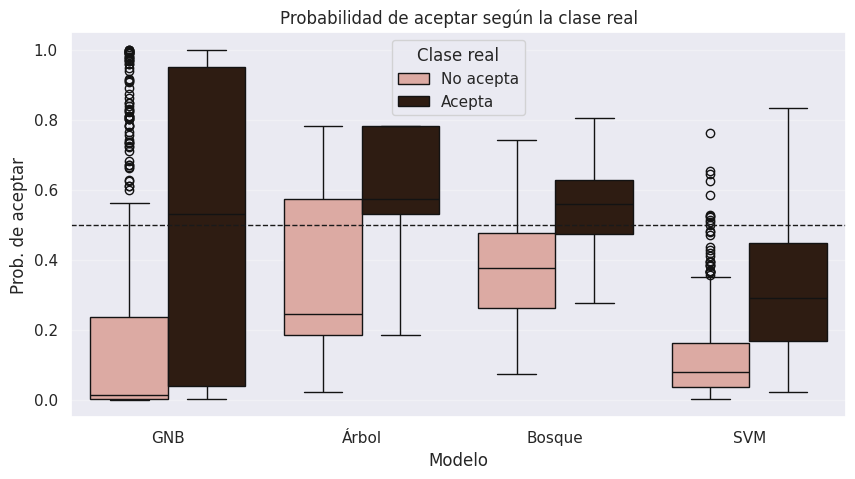

In [38]:
modelos_p = {'GNB': modelo, 'Árbol': dt_sin, 'Bosque': rf_sin, 'SVM': svm}
df_prob = pd.DataFrame([
    {'Modelo': n, 'Clase real': 'Acepta' if y == 1 else 'No acepta', 'Prob. de aceptar': p}
    for n, m in modelos_p.items()
    for p, y in zip(m.predict_proba(X_val_sin)[:, 1], y_val_sin)])

plt.figure(figsize=(10, 5))
sns.boxplot(data=df_prob, x='Modelo', y='Prob. de aceptar', hue='Clase real',
            palette=[cafe_palette_1[3], cafe_palette_1[0]])
plt.axhline(0.5, ls='--', color='k', lw=1)
plt.title('Probabilidad de aceptar según la clase real')
plt.grid(axis='y', alpha=0.3)
plt.show()


,Verdaderos positivos,Falsos Negativos,Falsos positivos (FP)
Modelo,,,
GNB,34,33,70
Decision Tree,59,8,183
Random Forest,45,22,71
SVM,51,16,99


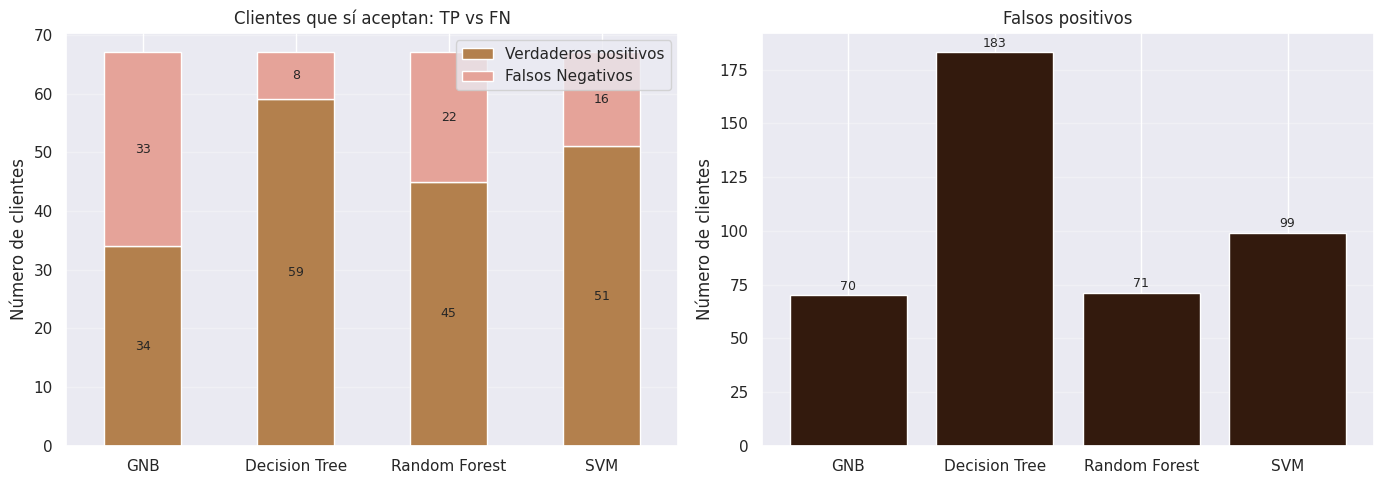

In [39]:
modelos_val = {"GNB": modelo, "Decision Tree": dt_sin, "Random Forest": rf_sin, "SVM": svm}

conteos = []
for nombre, m in modelos_val.items():
    tn, fp, fn, tp = confusion_matrix(y_val_sin, m.predict(X_val_sin), labels=[0, 1]).ravel()
    conteos.append({"Modelo": nombre, "Verdaderos positivos": tp, "Falsos Negativos": fn, "Falsos positivos (FP)": fp})
df_5b = pd.DataFrame(conteos).set_index("Modelo")
display(df_5b)

fig, (a1, a2) = plt.subplots(1, 2, figsize=(14, 5))

df_5b[["Verdaderos positivos", "Falsos Negativos"]].plot(kind="bar", stacked=True, ax=a1,
                                                  color=[cafe_palette_1[2], cafe_palette_1[3]], edgecolor="white")
for c in a1.containers:
    a1.bar_label(c, label_type="center", fontsize=9)
a1.set_title("Clientes que sí aceptan: TP vs FN")
a1.set_ylabel("Número de clientes"); a1.set_xlabel(""); a1.tick_params(axis="x", rotation=0)

a2.bar(df_5b.index, df_5b["Falsos positivos (FP)"], color=cafe_palette_1[0])
a2.bar_label(a2.containers[0], fontsize=9, padding=2)
a2.set_title("Falsos positivos")
a2.set_ylabel("Número de clientes")
for a in (a1, a2):
    a.grid(axis="y", alpha=0.3)
plt.tight_layout(); plt.show()


,Precisión,Recall,F1
Modelo,,,
GNB,32.7,50.7,39.8
Decision Tree,24.4,88.1,38.2
Random Forest,38.8,67.2,49.2
SVM,34.0,76.1,47.0


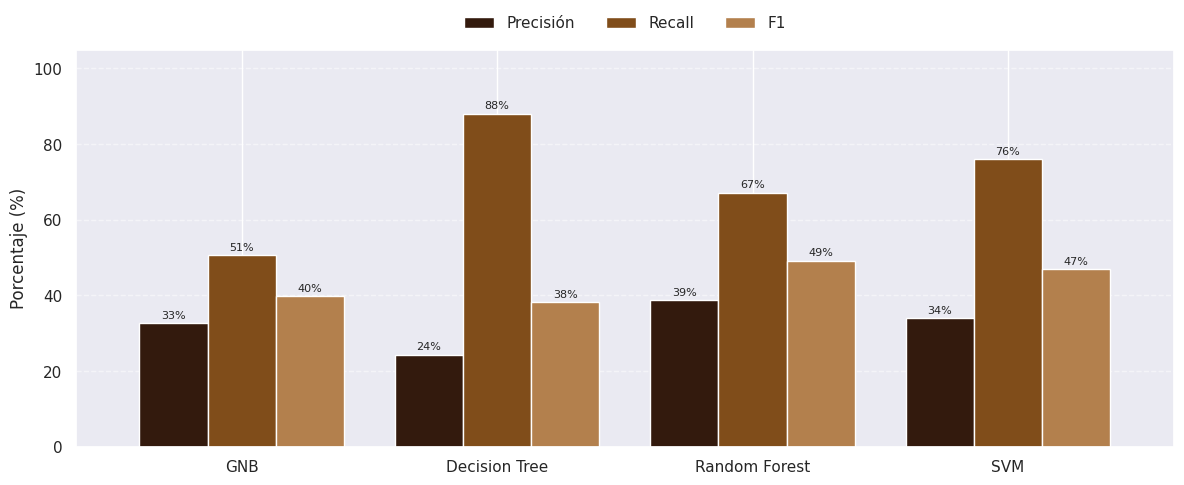

In [40]:
modelos_val = {"GNB": modelo, "Decision Tree": dt_sin, "Random Forest": rf_sin, "SVM": svm}

def puntaje(m, X):
    return m.predict_proba(X)[:, 1] if hasattr(m, "predict_proba") else m.decision_function(X)

filas = []
for nombre, m in modelos_val.items():
    pred = m.predict(X_val_sin)
    filas.append({"Modelo": nombre,
                  "Precisión":     precision_score(y_val_sin, pred, zero_division=0),
                  "Recall":        recall_score(y_val_sin, pred, zero_division=0),
                  "F1":            f1_score(y_val_sin, pred, zero_division=0)})
df_5a = pd.DataFrame(filas).set_index("Modelo") * 100
display(df_5a.round(1))

ax = df_5a.plot(kind="bar", figsize=(12, 5), width=0.8, color=cafe_palette_1[:5], edgecolor="white")
for c in ax.containers:
    ax.bar_label(c, fmt="%.0f%%", fontsize=8, padding=2)
ax.set_ylim(0, 105); ax.set_ylabel("Porcentaje (%)"); ax.set_xlabel("")
ax.set_xticklabels(df_5a.index, rotation=0)
ax.grid(axis="y", linestyle="--", alpha=0.5)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, 1.12), ncol=5, frameon=False)
plt.tight_layout(); plt.show()


# 9. Clasificación **con** campañas anteriores
Agregamos al modelo las variables `AcceptedCmp1` a `AcceptedCmp5` (si el cliente aceptó cada una de las campañas anteriores). `Response` es la aceptación de la campaña más reciente, así que estas variables son información que ya existía antes de contactar al cliente.

Primero entrenamos cada modelo con valores por defecto, solo como **línea base**. Después ajustamos los hiperparámetros con validación cruzada (VC) de 10 folds sobre el conjunto de entrenamiento y comparamos con el mismo procedimiento del escenario sin campañas.

## 9.1 Partición de los datos


In [41]:

sns.set_palette(rosa_palette_1)
display(y.head())
X_con = campañas.drop(columns=['Response']).copy()
display(X_con.head())

X_dev_con, X_test_con, y_dev_con, y_test_con = train_test_split(X_con, y, test_size=0.2, stratify=y, random_state=SEED)
X_train_con, X_val_con, y_train_con, y_val_con = train_test_split(X_dev_con, y_dev_con, test_size=0.25, stratify=y_dev_con, random_state=SEED)

print(f"Train: {len(y_train_con)} | Validación: {len(y_val_con)} | Test: {len(y_test_con)}")
display(y_train_con.value_counts().sort_index().rename('Train: muestras por Response'))


,Response
730,0
1963,1
153,0
1078,0
1784,1


,Education,Marital_Status,Teenhome,Recency,MntWines,MntFruits,MntMeatProducts,MntFishProducts,MntSweetProducts,MntGoldProds,NumCatalogPurchases,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Customer_Tenure_Month
730,PhD,Divorced,1,24,8,0,3,0,0,0,0,0,0,0,0,0,100.6
1963,Graduation,Single,1,32,50,4,44,10,10,43,1,0,0,0,0,0,105.4
153,Graduation,Alone,0,12,5,7,24,19,14,20,0,0,0,0,0,0,93.0
1078,Master,Single,0,9,234,14,77,19,10,42,1,0,0,0,0,0,96.7
1784,Graduation,Together,1,8,199,33,60,8,3,15,2,0,0,0,0,0,109.5


Train: 1329 | Validación: 443 | Test: 444


,Train: muestras por Response
Response,
0,1130
1,199


## 9.2 Codificación de variables categóricas (one-hot)


In [42]:
X_train_con = pd.get_dummies(X_train_con, columns=["Education", "Marital_Status"], dtype=int)
X_val_con = pd.get_dummies(X_val_con, columns=["Education", "Marital_Status"], dtype=int)
X_test_con = pd.get_dummies(X_test_con, columns=["Education", "Marital_Status"], dtype=int)

X_val_con = X_val_con.reindex(columns=X_train_con.columns, fill_value=0)
X_test_con = X_test_con.reindex(columns=X_train_con.columns, fill_value=0)

print("Entrenamiento:", X_train_con.shape)
print("Validación:", X_val_con.shape)
print("Prueba:", X_test_con.shape)


Entrenamiento: (1329, 28)
Validación: (443, 28)
Prueba: (444, 28)


## 9.3 Línea base (hiperparámetros por defecto)


In [43]:
modelo_con = GaussianNB()
modelo_con.fit(X_train_con, y_train_con)
y_pred_GNBcon = modelo_con.predict(X_val_con)

print(f"Predicciones reales: {y_val_con[:10]}")
print(" ")
print(f"Predicciones: {y_pred_GNBcon[:10]}")

acc_gnb_con = accuracy_score(y_val_con, y_pred_GNBcon)
pre_gnb_con = precision_score(y_val_con, y_pred_GNBcon)
rec_gnb_con = recall_score(y_val_con, y_pred_GNBcon)
f1_gnb_con = f1_score(y_val_con, y_pred_GNBcon)

print(" ")
print(f"Accuracy GNB con campañas:  {acc_gnb_con:.3f}")
print(f"Precision GNB con campañas: {pre_gnb_con:.3f}")
print(f"Recall GNB con campañas: {rec_gnb_con:.3f}")
print(f"F1-score GNB con campañas: {f1_gnb_con:.3f}")


Predicciones reales: 532     0
1600    0
1649    0
1911    0
1651    1
1120    0
1725    1
1093    0
673     0
1587    0
Name: Response, dtype: int64
 
Predicciones: [0 0 0 1 0 0 0 0 0 0]
 
Accuracy GNB con campañas:  0.849
Precision GNB con campañas: 0.500
Recall GNB con campañas: 0.507
F1-score GNB con campañas: 0.504


In [44]:
dt_con = DecisionTreeClassifier( random_state=SEED)
dt_con.fit(X_train_con, y_train_con)
y_pred_dtcon = dt_con.predict(X_val_con)

acc_dt_con = accuracy_score(y_val_con, y_pred_dtcon)
pre_dt_con = precision_score(y_val_con, y_pred_dtcon, zero_division=0)
rec_dt_con = recall_score(y_val_con, y_pred_dtcon)
f1_dt_con = f1_score(y_val_con, y_pred_dtcon)

print(f"Accuracy dt con campañas:  {acc_dt_con:.3f}")
print(f"Precision dt con campañas: {pre_dt_con:.3f}")
print(f"Recall dt con campañas: {rec_dt_con:.3f}")
print(f"F1-score dt con campañas: {f1_dt_con:.3f}")


Accuracy dt con campañas:  0.815
Precision dt con campañas: 0.381
Recall dt con campañas: 0.358
F1-score dt con campañas: 0.369


In [45]:
rf_con = RandomForestClassifier(n_estimators=100, random_state=SEED, n_jobs=-2)
rf_con.fit(X_train_con, y_train_con)
y_pred_rfcon = rf_con.predict(X_val_con)

acc_rf_con = accuracy_score(y_val_con, y_pred_rfcon)
pre_rf_con = precision_score(y_val_con, y_pred_rfcon, zero_division=0)
rec_rf_con = recall_score(y_val_con, y_pred_rfcon)
f1_rf_con = f1_score(y_val_con, y_pred_rfcon)

print(f"Accuracy rf con campañas:  {acc_rf_con:.3f}")
print(f"Precision rf con campañas: {pre_rf_con:.3f}")
print(f"Recall rf con campañas: {rec_rf_con:.3f}")
print(f"F1-score rf con campañas: {f1_rf_con:.3f}")


Accuracy rf con campañas:  0.871
Precision rf con campañas: 0.692
Recall rf con campañas: 0.269
F1-score rf con campañas: 0.387


In [46]:
svm_con = make_pipeline(StandardScaler(), SVC(kernel='rbf', C=1.0, gamma='scale'))
svm_con.fit(X_train_con, y_train_con)
y_pred_svmcon = svm_con.predict(X_val_con)

acc_svm_con = accuracy_score(y_val_con, y_pred_svmcon)
pre_svm_con = precision_score(y_val_con, y_pred_svmcon, zero_division=0)
rec_svm_con = recall_score(y_val_con, y_pred_svmcon)
f1_svm_con = f1_score(y_val_con, y_pred_svmcon)

print(f"Accuracy SVM con campañas:  {acc_svm_con:.3f}")
print(f"Precision SVM con campañas: {pre_svm_con:.3f}")
print(f"Recall SVM con campañas: {rec_svm_con:.3f}")
print(f"F1-score SVM con campañas: {f1_svm_con:.3f}")


Accuracy SVM con campañas:  0.878
Precision SVM con campañas: 0.724
Recall SVM con campañas: 0.313
F1-score SVM con campañas: 0.438


## 9.4 Ajuste de hiperparámetros con validación cruzada
### Función auxiliar


In [47]:
def variaciones_con(nombre, valores, crear_modelo, log=False, etiquetas=None):
    pal_con = rosa_palette_1
    filas_con = []
    for v in valores:
        sc = cross_validate(crear_modelo(v), X_train_con, y_train_con, cv=cv, scoring=scoring,
                            return_train_score=True, n_jobs=-2)
        filas_con.append({nombre: v if etiquetas is None else str(v),
                      'F1 train': sc['train_F1'].mean(),
                      'F1 CV': sc['test_F1'].mean(),
                      'desv. CV': sc['test_F1'].std(),
                      'Precision': sc['test_Precision'].mean(),
                      'Recall': sc['test_Recall'].mean()})
    df = pd.DataFrame(filas_con)
    df['Brecha'] = df['F1 train'] - df['F1 CV']
    if etiquetas is not None:
        df[nombre] = etiquetas
    display(df.round(3))

    x = np.arange(len(df)) if etiquetas is not None else df[nombre].values
    fig, (a1, a2) = plt.subplots(1, 2, figsize=(14, 5))
    a1.plot(x, df['F1 train'], marker='o', color=pal_con[0], label='Train')
    a1.errorbar(x, df['F1 CV'], yerr=df['desv. CV'], marker='s', capsize=4,
                color=pal_con[1], label='Validación cruzada')
    a1.fill_between(x, df['F1 CV'], df['F1 train'], alpha=0.15, color=pal_con[3], label='brecha')
    a2.plot(x, df['Precision'], marker='o', color=pal_con[0], label='Precisión CV')
    a2.plot(x, df['Recall'],    marker='s', color=pal_con[1], label='Recall CV')
    a2.plot(x, df['F1 CV'],     marker='^', color=pal_con[3], label='F1 CV')
    for a in (a1, a2):
        if etiquetas is not None:
            a.set_xticks(x)
            a.set_xticklabels(etiquetas)
        elif log:
            a.set_xscale('log')
        a.set_xlabel(nombre)
        a.grid(alpha=0.3)
        a.legend()
    a1.set_ylabel('F1 clase 1')
    a1.set_title(f'Train vs CV según {nombre}')
    a2.set_title('Comparación de métricas según valores')
    plt.tight_layout()
    plt.show()


### GaussianNB


,var_smoothing,F1 train,F1 CV,desv. CV,Precision,Recall,Brecha
0,0.000,0.459,0.454,0.090,0.484,0.446,0.005
1,0.000,0.510,0.503,0.105,0.458,0.562,0.006
2,0.000,0.439,0.432,0.100,0.405,0.467,0.008
3,0.001,0.347,0.343,0.076,0.315,0.382,0.004
4,0.010,0.332,0.330,0.073,0.331,0.337,0.002
5,0.100,0.291,0.285,0.074,0.414,0.226,0.006
6,1.000,0.034,0.029,0.044,0.300,0.015,0.006


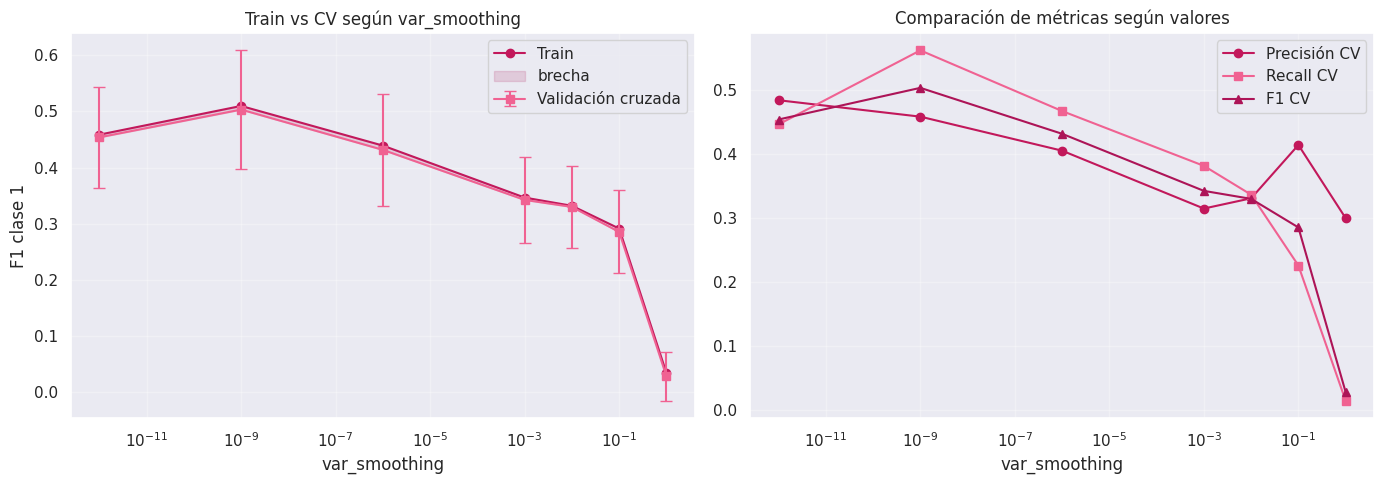

,priors,F1 train,F1 CV,desv. CV,Precision,Recall,Brecha
0,Proporcion clases: 85/15,0.510,0.503,0.105,0.458,0.562,0.006
1,70/30,0.514,0.507,0.082,0.443,0.597,0.006
2,50/50 balanceo manual,0.514,0.509,0.075,0.430,0.627,0.005


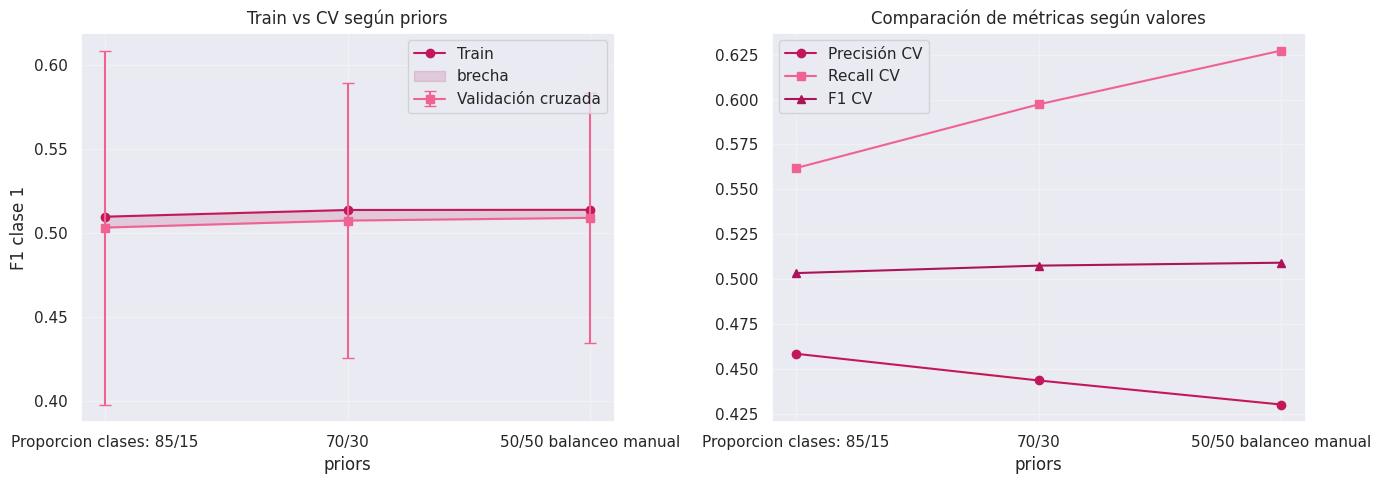

In [48]:
variaciones_con('var_smoothing', [1e-12, 1e-9, 1e-6, 1e-3, 1e-2, 1e-1, 1],
        lambda v: GaussianNB(var_smoothing=v), log=True)

variaciones_con('priors', [None, [0.7, 0.3], [0.5, 0.5]],
        lambda v: GaussianNB(priors=v, var_smoothing=1e-9),
        etiquetas=['Proporcion clases: 85/15', '70/30', '50/50 balanceo manual'])



### Árbol de decisión


,class_weight dt,F1 train,F1 CV,desv. CV,Precision,Recall,Brecha
0,Sin balanceo,0.473,0.400,0.106,0.619,0.316,0.073
1,con balanceo,0.463,0.421,0.079,0.357,0.599,0.042


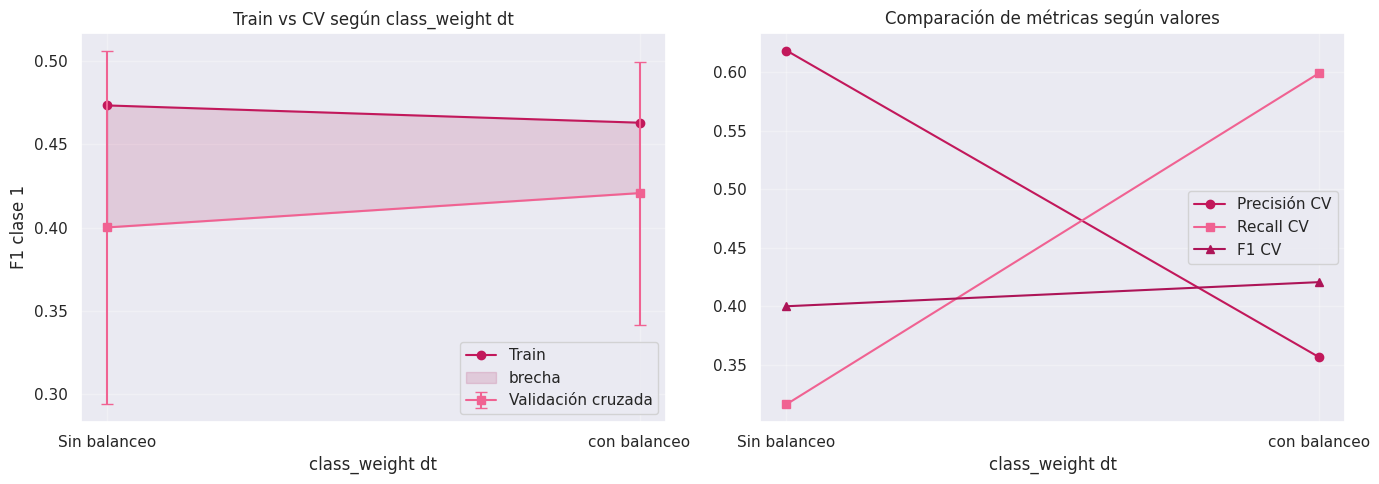

,max_depth dt,F1 train,F1 CV,desv. CV,Precision,Recall,Brecha
0,1,0.335,0.279,0.062,0.234,0.696,0.056
1,2,0.380,0.320,0.050,0.239,0.682,0.061
2,3,0.463,0.421,0.079,0.357,0.599,0.042
3,4,0.484,0.378,0.029,0.281,0.637,0.106
4,5,0.519,0.429,0.060,0.319,0.689,0.091
5,6,0.600,0.453,0.057,0.350,0.649,0.147
6,7,0.634,0.436,0.032,0.335,0.649,0.197
7,8,0.700,0.427,0.052,0.340,0.583,0.273
8,9,0.764,0.424,0.061,0.348,0.553,0.340
9,10,0.812,0.430,0.084,0.367,0.529,0.382


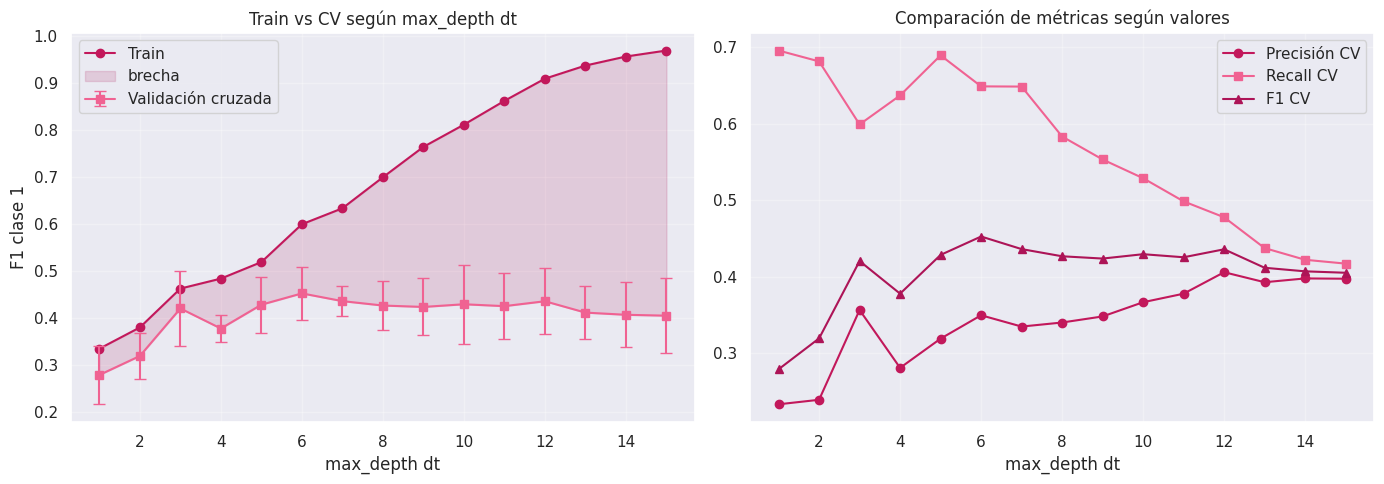

In [49]:


variaciones_con('class_weight dt', [None, 'balanced'],
        lambda v: DecisionTreeClassifier(max_depth=3,class_weight=v, random_state=SEED),
        etiquetas=['Sin balanceo', 'con balanceo'])
variaciones_con('max_depth dt', range(1, 16),
        lambda v: DecisionTreeClassifier(max_depth=v, class_weight='balanced',random_state=SEED))
#Max_depth-6





### Random Forest


,class_weight rf,F1 train,F1 CV,desv. CV,Precision,Recall,Brecha
0,Sin balanceo,0.688,0.342,0.119,0.816,0.221,0.346
1,con balanceo,0.895,0.527,0.099,0.601,0.478,0.367
2,balanced_subsample,0.893,0.543,0.087,0.613,0.492,0.350


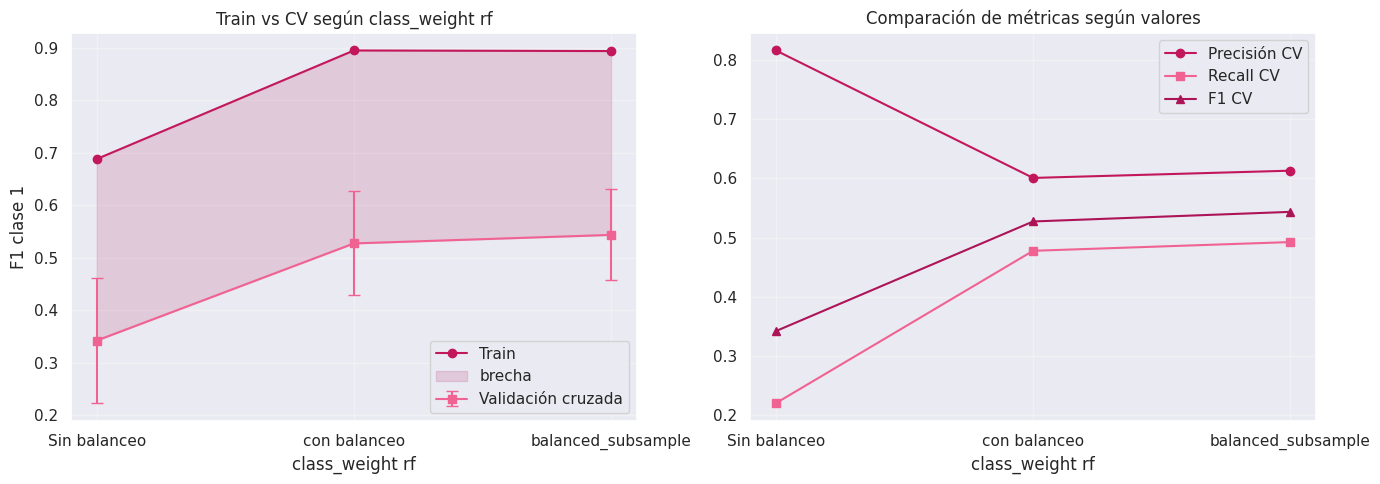

,max_depth rf,F1 train,F1 CV,desv. CV,Precision,Recall,Brecha
0,2,0.478,0.431,0.053,0.318,0.678,0.047
1,3,0.536,0.446,0.030,0.344,0.638,0.090
2,4,0.619,0.497,0.051,0.409,0.638,0.122
3,5,0.728,0.550,0.062,0.507,0.613,0.178
4,6,0.817,0.552,0.079,0.556,0.558,0.265
5,7,0.895,0.527,0.099,0.601,0.478,0.367
6,8,0.950,0.509,0.107,0.641,0.432,0.440
7,10,0.986,0.433,0.113,0.726,0.312,0.553


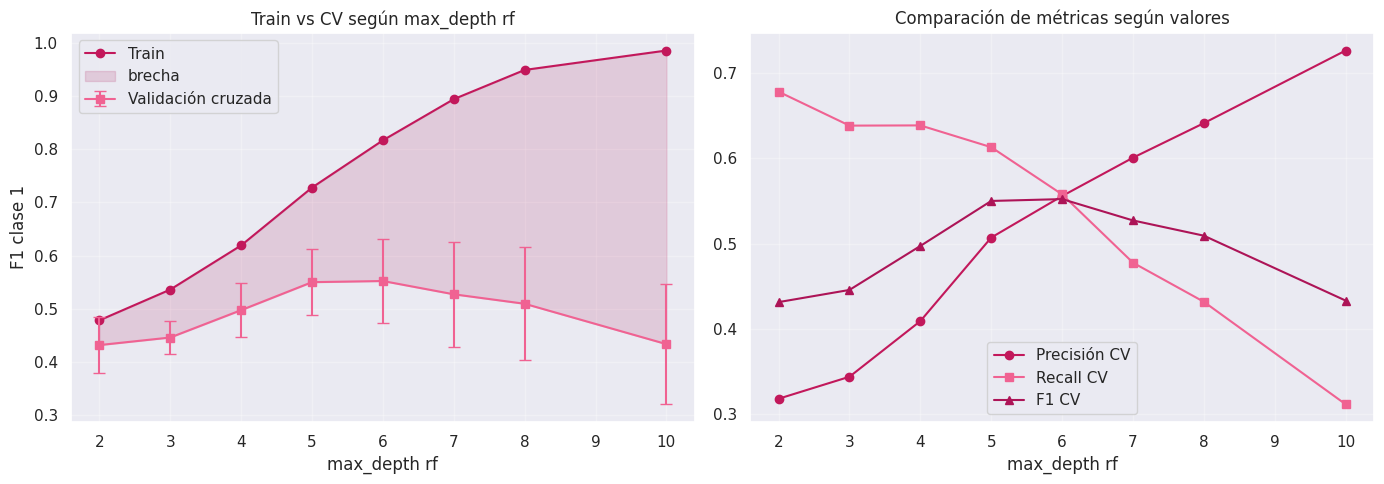

,n_estimators rf,F1 train,F1 CV,desv. CV,Precision,Recall,Brecha
0,50,0.720,0.520,0.067,0.469,0.597,0.200
1,100,0.728,0.550,0.062,0.507,0.613,0.178
2,150,0.728,0.552,0.085,0.505,0.623,0.176
3,200,0.731,0.538,0.069,0.495,0.603,0.193
4,300,0.731,0.543,0.077,0.497,0.608,0.188


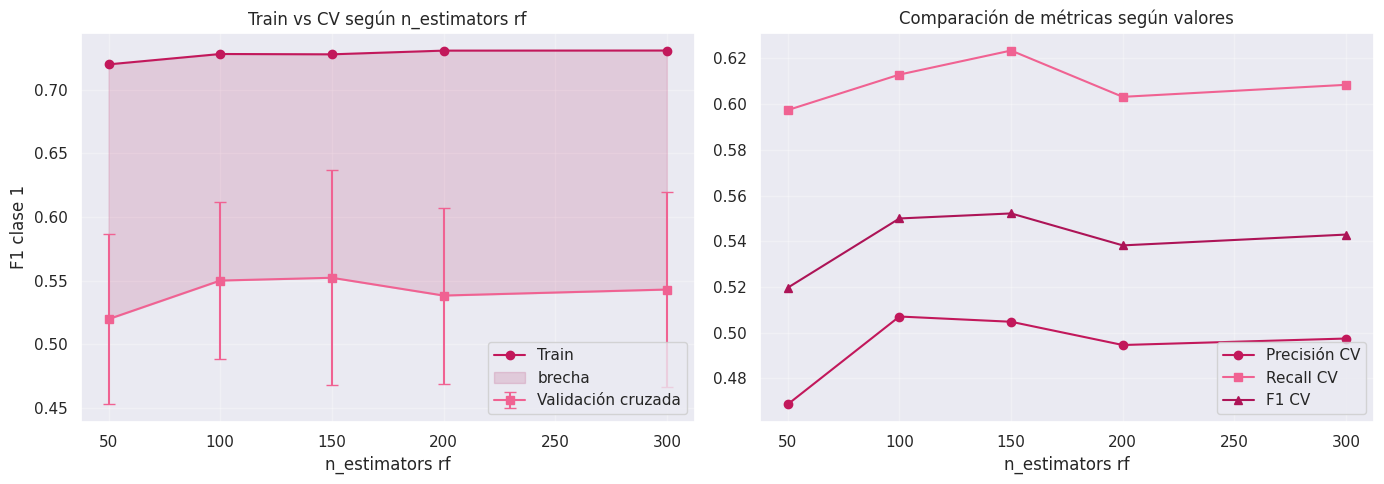

In [50]:
variaciones_con('class_weight rf', [None, 'balanced', 'balanced_subsample'],
        lambda v: RandomForestClassifier(n_estimators=100, max_depth=7, class_weight=v,
                                         random_state=SEED, n_jobs=-2),
        etiquetas=['Sin balanceo', 'con balanceo', 'balanced_subsample'])

variaciones_con('max_depth rf', [2, 3, 4, 5, 6, 7, 8, 10],
        lambda v: RandomForestClassifier(n_estimators=100, max_depth=v, class_weight='balanced',
                                         random_state=SEED, n_jobs=-2))

variaciones_con('n_estimators rf', [50, 100, 150, 200, 300],
        lambda v: RandomForestClassifier(n_estimators=v, max_depth=5, class_weight='balanced',
                                         random_state=SEED, n_jobs=-2))


### SVM


,class_weight svm,F1 train,F1 CV,desv. CV,Precision,Recall,Brecha
0,Sin balanceo,0.673,0.389,0.097,0.720,0.276,0.285
1,con balanceo,0.712,0.546,0.053,0.437,0.728,0.166


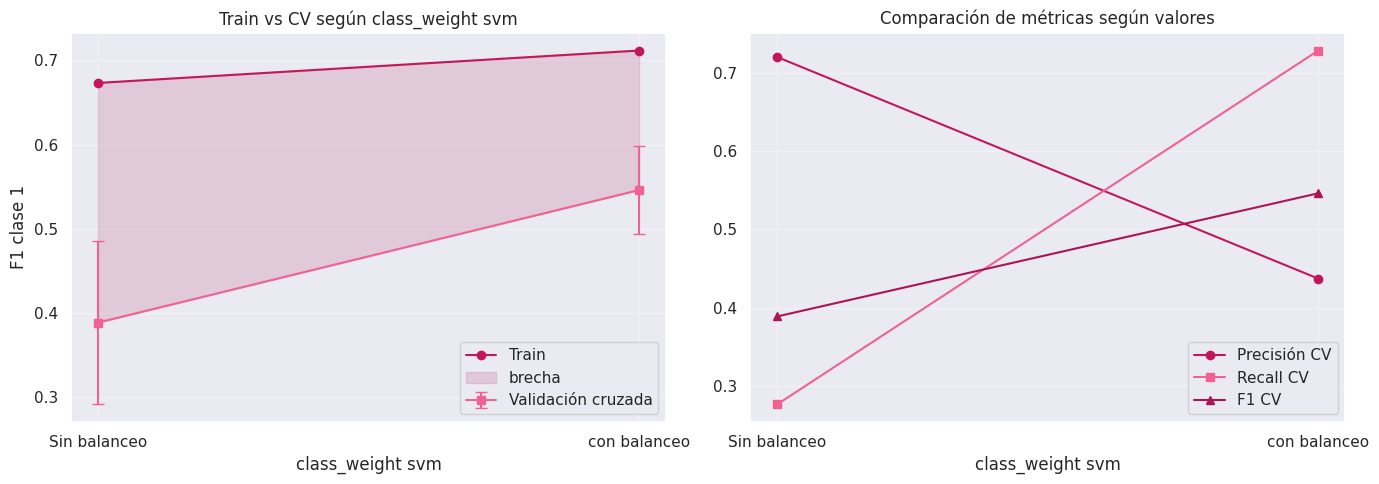

,C svm,F1 train,F1 CV,desv. CV,Precision,Recall,Brecha
0,0.1,0.527,0.498,0.043,0.372,0.758,0.029
1,1.0,0.712,0.546,0.053,0.437,0.728,0.166
2,10.0,0.855,0.513,0.075,0.484,0.553,0.342
3,100.0,0.923,0.487,0.072,0.487,0.493,0.436
4,300.0,0.950,0.500,0.067,0.494,0.513,0.449


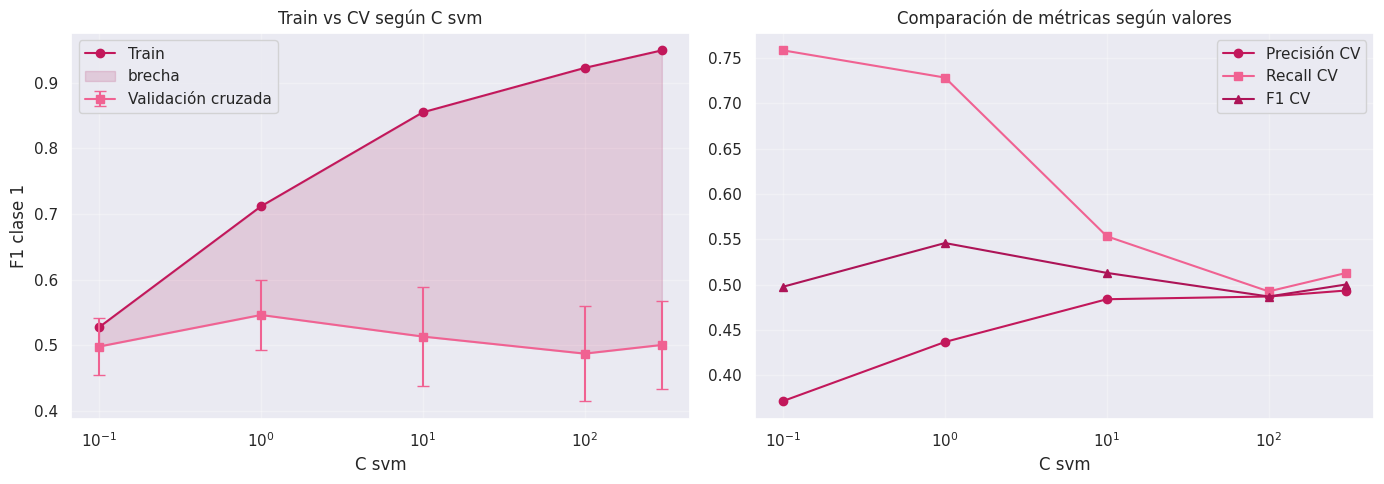

,kernel svm,F1 train,F1 CV,desv. CV,Precision,Recall,Brecha
0,linear,0.579,0.545,0.046,0.428,0.759,0.034
1,poly,0.800,0.540,0.088,0.575,0.517,0.260
2,rbf,0.712,0.546,0.053,0.437,0.728,0.166
3,sigmoid,0.408,0.429,0.048,0.310,0.708,-0.021


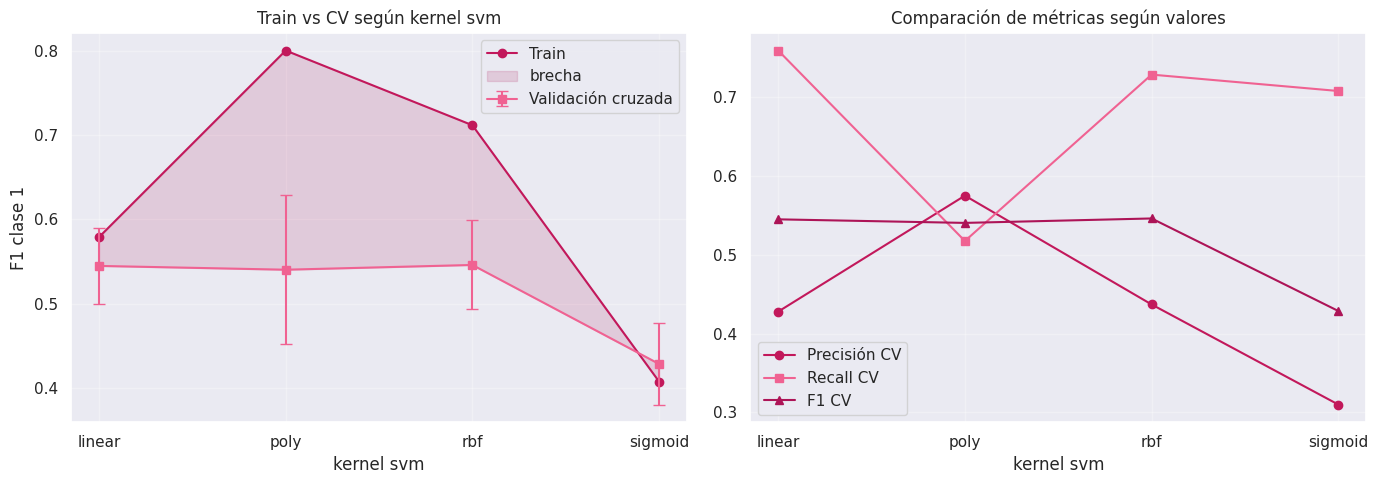

,C svm lineal,F1 train,F1 CV,desv. CV,Precision,Recall,Brecha
0,0.01,0.576,0.553,0.054,0.444,0.744,0.023
1,0.10,0.581,0.540,0.035,0.427,0.744,0.040
2,1.00,0.579,0.545,0.046,0.428,0.759,0.034
3,10.00,0.578,0.543,0.046,0.426,0.759,0.035


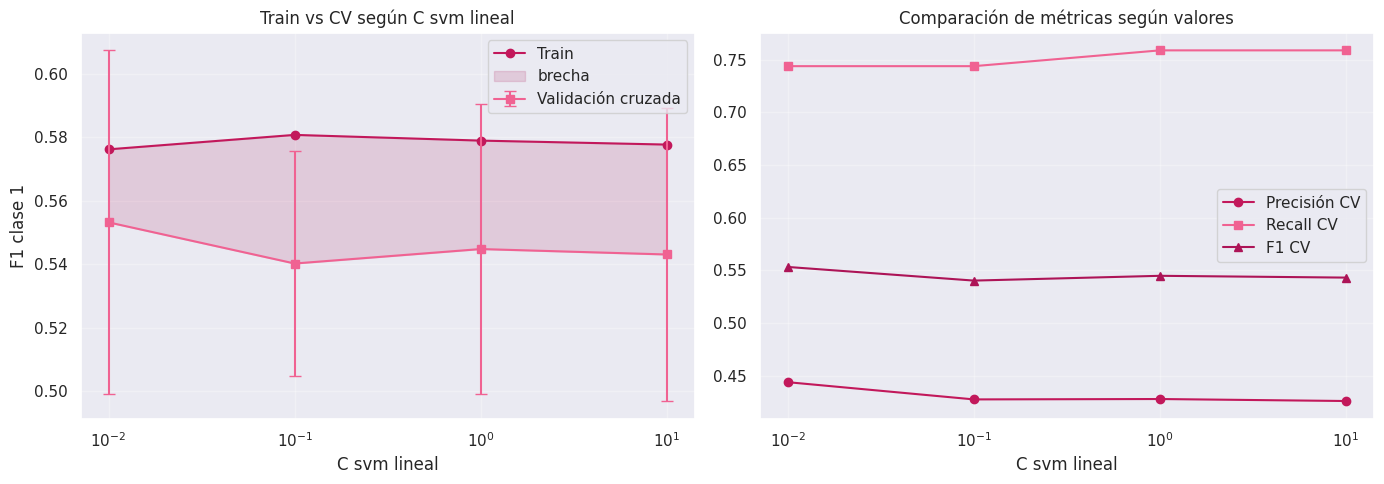

In [52]:

variaciones_con('class_weight svm', [None, 'balanced'],
        lambda v: make_pipeline(StandardScaler(), SVC(C=1.0, gamma='scale', class_weight=v, random_state=SEED, kernel='rbf')),
        etiquetas=['Sin balanceo', 'con balanceo'])

variaciones_con('C svm', [0.1, 1, 10, 100, 300],
        lambda v: make_pipeline(StandardScaler(), SVC(C=v, gamma='scale', class_weight='balanced', random_state=SEED,kernel='rbf')),
        log=True)

variaciones_con('kernel svm', ['linear', 'poly', 'rbf', 'sigmoid'],
        lambda v: make_pipeline(StandardScaler(), SVC(kernel=v, C=1.0, gamma='scale',class_weight='balanced', random_state=SEED)),
        etiquetas=['linear', 'poly', 'rbf', 'sigmoid'])

variaciones_con('C svm lineal', [0.01, 0.1, 1, 10],
        lambda v: make_pipeline(StandardScaler(), SVC(kernel='linear', C=v,
                                                      class_weight='balanced', random_state=SEED)),
        log=True)
#linear




## 9.5 Modelos con los hiperparámetros elegidos (conjunto de validación)


In [53]:
# Con un unico conjunto de validacion

modelo_con = GaussianNB(var_smoothing=1e-9, priors=[0.5, 0.5])
modelo_con.fit(X_train_con, y_train_con)
y_pred_GNBcon = modelo_con.predict(X_val_con)
acc_gnb_con = accuracy_score(y_val_con, y_pred_GNBcon)
pre_gnb_con = precision_score(y_val_con, y_pred_GNBcon, zero_division=0)
rec_gnb_con = recall_score(y_val_con, y_pred_GNBcon)
f1_gnb_con = f1_score(y_val_con, y_pred_GNBcon)

dt_con = DecisionTreeClassifier(max_depth=3, random_state=SEED, class_weight='balanced')
dt_con.fit(X_train_con, y_train_con)
y_pred_dtcon = dt_con.predict(X_val_con)
acc_dt_con = accuracy_score(y_val_con, y_pred_dtcon)
pre_dt_con = precision_score(y_val_con, y_pred_dtcon, zero_division=0)
rec_dt_con = recall_score(y_val_con, y_pred_dtcon)
f1_dt_con = f1_score(y_val_con, y_pred_dtcon)

rf_con = RandomForestClassifier(n_estimators=150, max_depth=4, random_state=SEED, n_jobs=-2, class_weight='balanced')
rf_con.fit(X_train_con, y_train_con)
y_pred_rfcon = rf_con.predict(X_val_con)
acc_rf_con = accuracy_score(y_val_con, y_pred_rfcon)
pre_rf_con = precision_score(y_val_con, y_pred_rfcon, zero_division=0)
rec_rf_con = recall_score(y_val_con, y_pred_rfcon)
f1_rf_con = f1_score(y_val_con, y_pred_rfcon)

svm_con = make_pipeline(StandardScaler(), SVC(kernel='linear', C=0.01, gamma='scale', random_state=SEED, probability= True, class_weight='balanced'))
svm_con.fit(X_train_con, y_train_con)
y_pred_svmcon = svm_con.predict(X_val_con)
acc_svm_con = accuracy_score(y_val_con, y_pred_svmcon)
pre_svm_con = precision_score(y_val_con, y_pred_svmcon, zero_division=0)
rec_svm_con = recall_score(y_val_con, y_pred_svmcon)
f1_svm_con = f1_score(y_val_con, y_pred_svmcon)


In [54]:
metricas_con_campañas = pd.DataFrame({'Modelo': ['GaussianNB', 'Decision Tree', 'Random Forest', 'SVM'],
                                      'Accuracy': [acc_gnb_con, acc_dt_con, acc_rf_con, acc_svm_con],
                                      'Precision': [pre_gnb_con, pre_dt_con, pre_rf_con, pre_svm_con],
                                      'Recall': [rec_gnb_con, rec_dt_con, rec_rf_con, rec_svm_con],
                                      'F1-Score': [f1_gnb_con, f1_dt_con, f1_rf_con, f1_svm_con]})
metricas_con_campañas = metricas_con_campañas.round(3)
metricas_con_campañas.head()


,Modelo,Accuracy,Precision,Recall,F1-Score
0,GaussianNB,0.831,0.453,0.582,0.510
1,Decision Tree,0.840,0.471,0.493,0.482
2,Random Forest,0.826,0.453,0.716,0.555
3,SVM,0.810,0.425,0.716,0.533


## 9.6 Análisis de errores (validación)


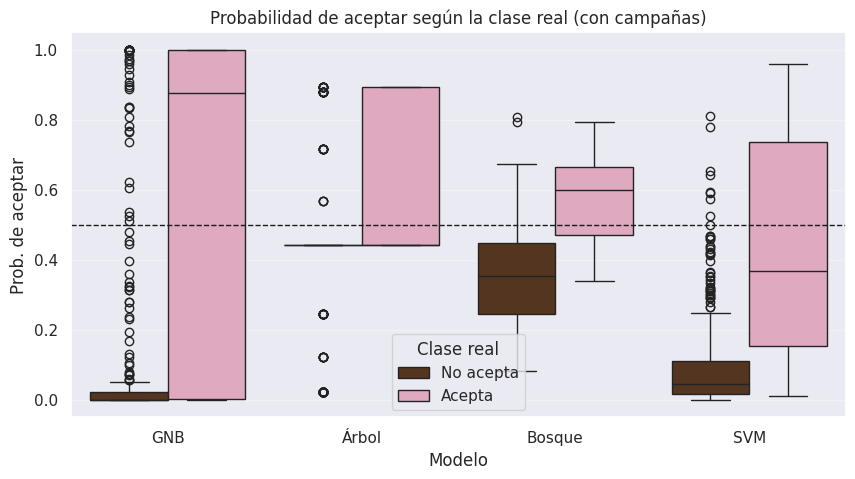

In [55]:
modelos_p_con = {'GNB': modelo_con, 'Árbol': dt_con, 'Bosque': rf_con, 'SVM': svm_con}
df_prob = pd.DataFrame([
    {'Modelo': n, 'Clase real': 'Acepta' if y == 1 else 'No acepta', 'Prob. de aceptar': p}
    for n, m in modelos_p_con.items()
    for p, y in zip(m.predict_proba(X_val_con)[:, 1], y_val_con)])

plt.figure(figsize=(10, 5))
sns.boxplot(data=df_prob, x='Modelo', y='Prob. de aceptar', hue='Clase real',
           palette={
        'Acepta': '#E8A0BF',
        'No acepta': '#5C3317'
    })
plt.axhline(0.5, ls='--', color='k', lw=1)
plt.title('Probabilidad de aceptar según la clase real (con campañas)')
plt.grid(axis='y', alpha=0.3)
plt.show()


,Verdaderos positivos,Falsos Negativos,Falsos positivos (FP)
Modelo,,,
GNB,39,28,47
Decision Tree,33,34,37
Random Forest,48,19,58
SVM,48,19,65


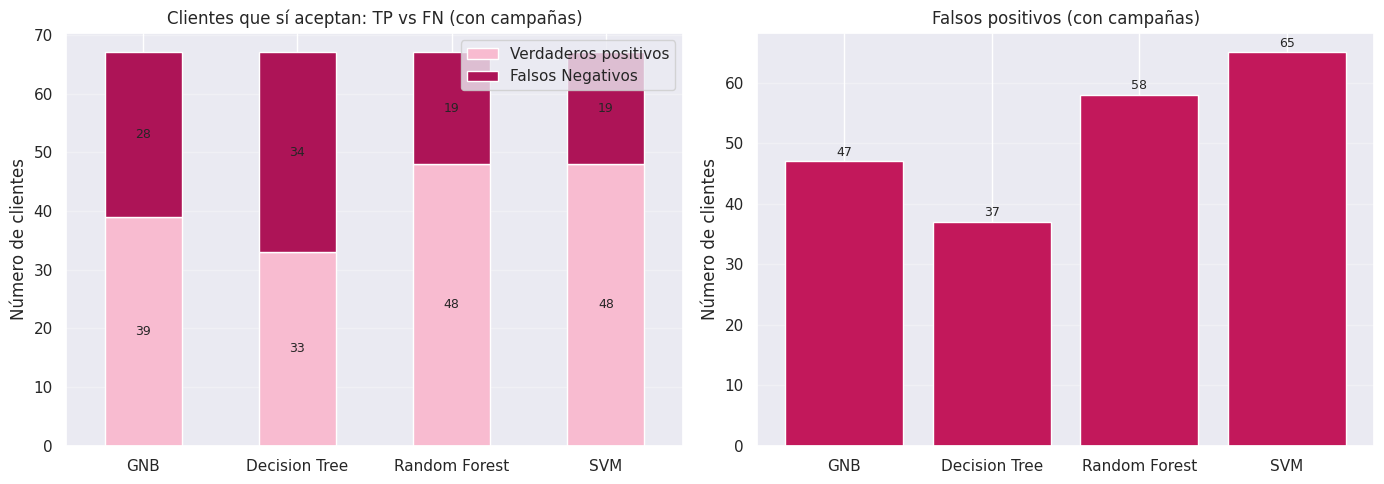

In [56]:
modelos_val_con = {"GNB": modelo_con, "Decision Tree": dt_con, "Random Forest": rf_con, "SVM": svm_con}

conteos = []
for nombre, m in modelos_val_con.items():
    tn, fp, fn, tp = confusion_matrix(y_val_con, m.predict(X_val_con), labels=[0, 1]).ravel()
    conteos.append({"Modelo": nombre, "Verdaderos positivos": tp, "Falsos Negativos": fn, "Falsos positivos (FP)": fp})
df_5b_con = pd.DataFrame(conteos).set_index("Modelo")
display(df_5b_con)

fig, (a1, a2) = plt.subplots(1, 2, figsize=(14, 5))

df_5b_con[["Verdaderos positivos", "Falsos Negativos"]].plot(kind="bar", stacked=True, ax=a1,
                                                  color=[rosa_palette_1[2], rosa_palette_1[3]], edgecolor="white")
for c in a1.containers:
    a1.bar_label(c, label_type="center", fontsize=9)
a1.set_title("Clientes que sí aceptan: TP vs FN (con campañas)")
a1.set_ylabel("Número de clientes"); a1.set_xlabel(""); a1.tick_params(axis="x", rotation=0)

a2.bar(df_5b_con.index, df_5b_con["Falsos positivos (FP)"], color=rosa_palette_1[0])
a2.bar_label(a2.containers[0], fontsize=9, padding=2)
a2.set_title("Falsos positivos (con campañas)")
a2.set_ylabel("Número de clientes")
for a in (a1, a2):
    a.grid(axis="y", alpha=0.3)
plt.tight_layout(); plt.show()


,Precisión,Recall,F1
Modelo,,,
GNB,45.3,58.2,51.0
Decision Tree,47.1,49.3,48.2
Random Forest,45.3,71.6,55.5
SVM,42.5,71.6,53.3


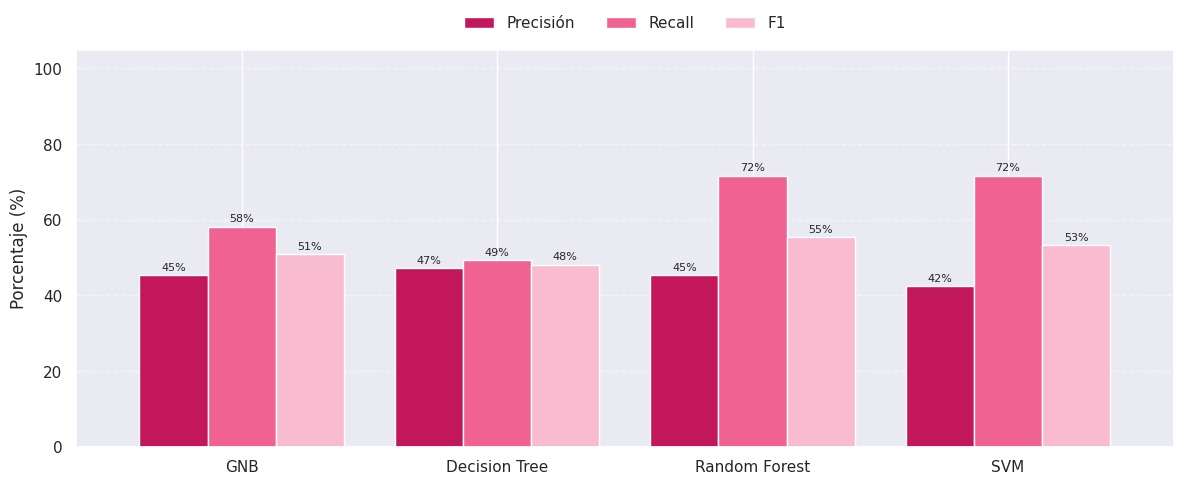

In [57]:
filas = []
for nombre, m in modelos_val_con.items():
    pred = m.predict(X_val_con)
    filas.append({"Modelo": nombre,
                  "Precisión": precision_score(y_val_con, pred, zero_division=0),
                  "Recall":    recall_score(y_val_con, pred, zero_division=0),
                  "F1":        f1_score(y_val_con, pred, zero_division=0)})
df_5a_con = pd.DataFrame(filas).set_index("Modelo") * 100
display(df_5a_con.round(1))

ax = df_5a_con.plot(kind="bar", figsize=(12, 5), width=0.8, color=rosa_palette_1[:5], edgecolor="white")
for c in ax.containers:
    ax.bar_label(c, fmt="%.0f%%", fontsize=8, padding=2)
ax.set_ylim(0, 105); ax.set_ylabel("Porcentaje (%)"); ax.set_xlabel("")
ax.set_xticklabels(df_5a_con.index, rotation=0)
ax.grid(axis="y", linestyle="--", alpha=0.5)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, 1.12), ncol=5, frameon=False)
plt.tight_layout(); plt.show()


# 10. Comparación: sin vs. con campañas
## 10.1 Colores y nombres de modelos


In [58]:
c_sin, c_con = cafe_palette_1[0], rosa_palette_1[1]

nombres = {"GNB": "GNB", "dt": "Árbol", "rf": "Random Forest", "SVM": "SVM"}
orden = list(nombres.keys())


## 10.2 F1 en validación, por modelo


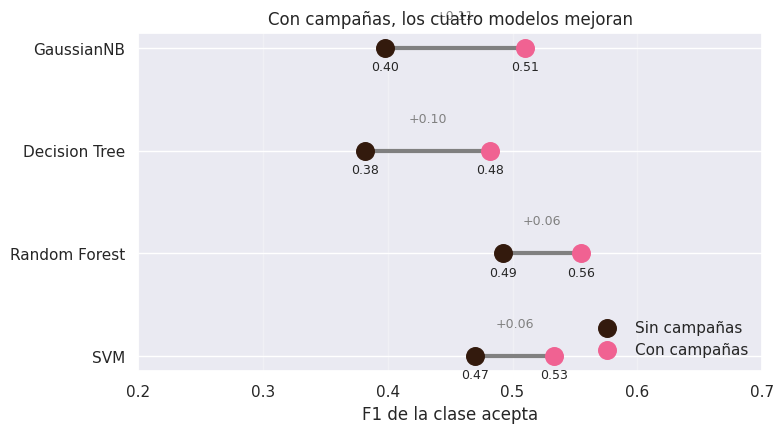

In [59]:
modelos = metricas_sin_campañas['Modelo'].tolist()
f_sin = metricas_sin_campañas['F1-Score'].values
f_con = metricas_con_campañas['F1-Score'].values
pos = np.arange(len(modelos))

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.hlines(pos, f_sin, f_con, color='gray', lw=3, zorder=1)
ax.scatter(f_sin, pos, s=160, color=c_sin, label='Sin campañas', zorder=2)
ax.scatter(f_con, pos, s=160, color=c_con, label='Con campañas', zorder=2)
for yi, a, b in zip(pos, f_sin, f_con):
    ax.text(a, yi + 0.22, f"{a:.2f}", ha='center', fontsize=9)
    ax.text(b, yi + 0.22, f"{b:.2f}", ha='center', fontsize=9)
    ax.text((a + b) / 2, yi - 0.28, f"{b - a:+.2f}", ha='center', fontsize=9, color='gray')
ax.set_yticks(pos); ax.set_yticklabels(modelos); ax.invert_yaxis()
ax.set_xlim(0.2, 0.7)
ax.set_xlabel('F1 de la clase acepta')
ax.set_title('Con campañas, los cuatro modelos mejoran')
ax.grid(axis='x', alpha=0.3); ax.legend(frameon=False, loc='lower right')
plt.tight_layout()
plt.savefig("mancuernas_f1.png", dpi=200, bbox_inches="tight")
plt.show()


## 10.3 Falsos positivos y verdaderos positivos


,Escenario,Modelo,Falsos positivos,Verdaderos positivos,FP por cada acierto
0,Sin campañas,GNB,70,34,2.06
1,Sin campañas,Decision Tree,183,59,3.10
2,Sin campañas,Random Forest,71,45,1.58
3,Sin campañas,SVM,99,51,1.94
4,Con campañas,GNB,47,39,1.21
5,Con campañas,Decision Tree,37,33,1.12
6,Con campañas,Random Forest,58,48,1.21
7,Con campañas,SVM,65,48,1.35


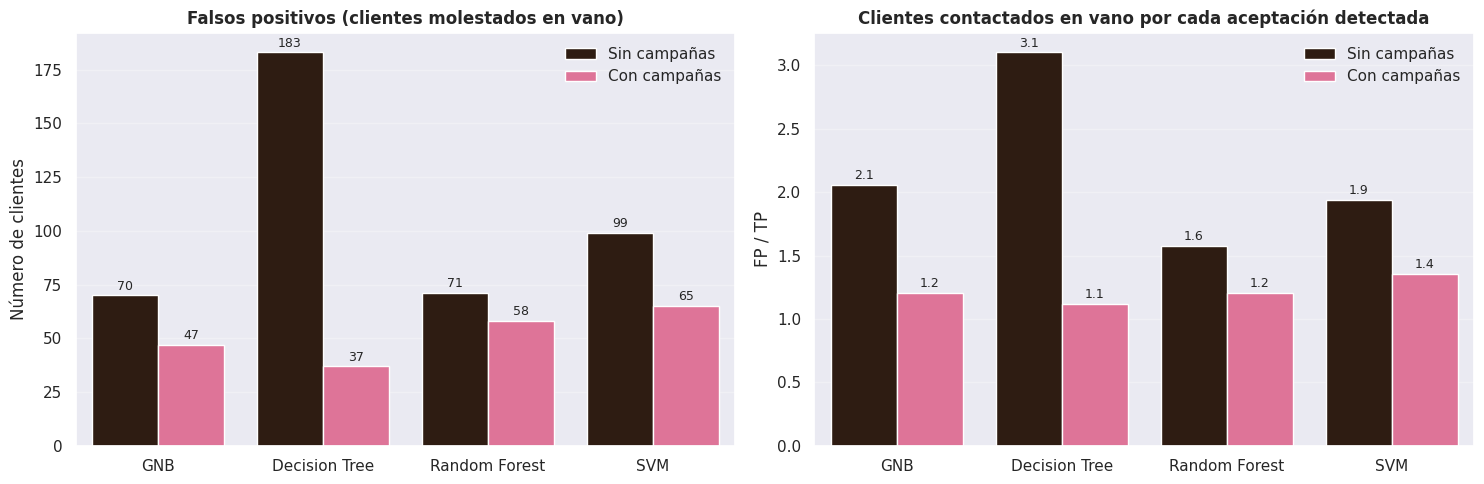

In [60]:
fp_tp = pd.DataFrame({
    'Falsos positivos': pd.concat([df_5b['Falsos positivos (FP)'], df_5b_con['Falsos positivos (FP)']], keys=['Sin campañas', 'Con campañas']),
    'Verdaderos positivos': pd.concat([df_5b['Verdaderos positivos'], df_5b_con['Verdaderos positivos']], keys=['Sin campañas', 'Con campañas']),
}).rename_axis(['Escenario', 'Modelo']).reset_index()
fp_tp['FP por cada acierto'] = fp_tp['Falsos positivos'] / fp_tp['Verdaderos positivos'].replace(0, np.nan)
display(fp_tp.round(2))

fig, (a1, a2) = plt.subplots(1, 2, figsize=(15, 5))
for ax, col, titulo, ylab in [
        (a1, 'Falsos positivos', 'Falsos positivos (clientes molestados en vano)', 'Número de clientes'),
        (a2, 'FP por cada acierto', 'Clientes contactados en vano por cada aceptación detectada', 'FP / TP')]:
    sns.barplot(data=fp_tp, x='Modelo', y=col, hue='Escenario', hue_order=['Sin campañas', 'Con campañas'],
                palette={'Sin campañas': c_sin, 'Con campañas': c_con}, ax=ax)
    for c in ax.containers:
        ax.bar_label(c, fmt='%.0f' if col == 'Falsos positivos' else '%.1f', fontsize=9, padding=2)
    ax.set_title(titulo, fontsize=12, weight='bold'); ax.set_ylabel(ylab); ax.set_xlabel('')
    ax.grid(axis='y', alpha=0.3); ax.legend(frameon=False)
plt.tight_layout()
plt.savefig("falsos_positivos_comparativa.png", dpi=200, bbox_inches="tight")
plt.show()


## 10.4 F1 con validación cruzada (10 folds)


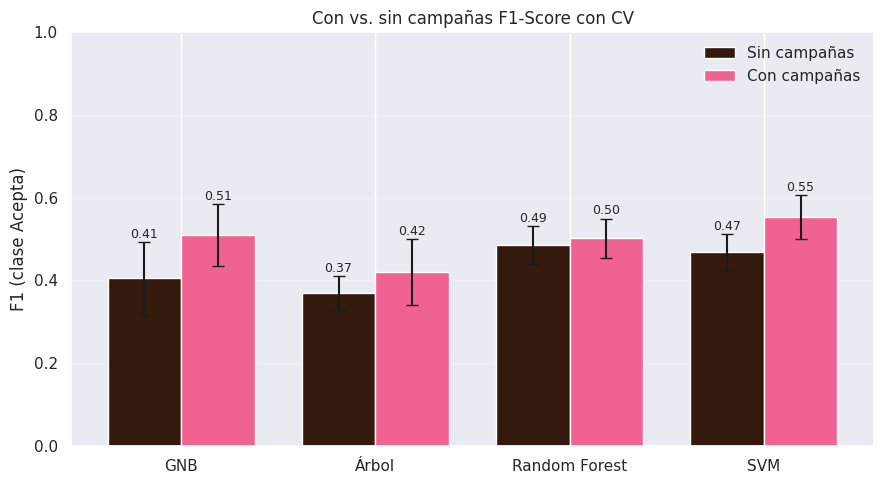

In [61]:
modelos_cv_sin = {
    'GNB': modelo,
    'dt': dt_sin,
    'rf': rf_sin,
    'SVM': svm
}

modelos_cv_con = {
    'GNB': modelo_con,
    'dt': dt_con,
    'rf': rf_con,
    'SVM': svm_con
}

filas_sin = {}
for nombre, mod in modelos_cv_sin.items():
    scores = cross_validate(mod, X_train_sin, y_train_sin, cv=cv, scoring='f1', n_jobs=-2)
    filas_sin[nombre] = {
        'F1': scores['test_score'].mean(),
        'F1_std': scores['test_score'].std()
    }
df_resultados = pd.DataFrame(filas_sin).T

filas_con = {}
for nombre, mod in modelos_cv_con.items():
    scores = cross_validate(mod, X_train_con, y_train_con, cv=cv, scoring='f1', n_jobs=-2)
    filas_con[nombre] = {
        'F1': scores['test_score'].mean(),
        'F1_std': scores['test_score'].std()
    }
df_resultados_con = pd.DataFrame(filas_con).T

f1_sin = df_resultados.loc[orden, "F1"];      sd_sin = df_resultados.loc[orden, "F1_std"]
f1_con = df_resultados_con.loc[orden, "F1"];  sd_con = df_resultados_con.loc[orden, "F1_std"]

x = np.arange(len(orden)); w = 0.38
fig, ax = plt.subplots(figsize=(9, 5))
ax.bar(x - w/2, f1_sin, w, yerr=sd_sin, capsize=4, color=c_sin, label="Sin campañas")
ax.bar(x + w/2, f1_con, w, yerr=sd_con, capsize=4, color=c_con, label="Con campañas")

for xi, v, s in zip(x - w/2, f1_sin, sd_sin):
    ax.text(xi, v + s + 0.01, f"{v:.2f}", ha="center", fontsize=9)
for xi, v, s in zip(x + w/2, f1_con, sd_con):
    ax.text(xi, v + s + 0.01, f"{v:.2f}", ha="center", fontsize=9)

ax.set_xticks(x); ax.set_xticklabels([nombres[m] for m in orden])
ax.set_ylabel("F1 (clase Acepta)")
ax.set_ylim(0, 1)
ax.set_title("Con vs. sin campañas F1-Score con CV")
ax.grid(axis="y", alpha=0.3); ax.legend(frameon=False)
plt.tight_layout()
plt.savefig("grafica_7.png", dpi=200, bbox_inches="tight")
plt.show()


## 10.5 Evaluación final en el conjunto de prueba (Random Forest)
Los modelos finales se reentrenan con entrenamiento + validación y se evalúan una sola vez sobre el conjunto de prueba.


In [62]:
X_dev_cod = pd.concat([X_train_sin, X_val_sin])
y_dev_cod = pd.concat([y_train_sin, y_val_sin])

final_sinCampañas = clone(rf_sin)
final_sinCampañas.fit(X_dev_cod, y_dev_cod)
y_test_pred_sin = final_sinCampañas.predict(X_test_sin)

metricas_test = {
    "Modelo sin campañas": "Random Forest",
    "Accuracy": accuracy_score(y_test_sin, y_test_pred_sin),
    "Precision": precision_score(y_test_sin, y_test_pred_sin, zero_division=0),
    "Recall": recall_score(y_test_sin, y_test_pred_sin, zero_division=0),
    "F1-Score": f1_score(y_test_sin, y_test_pred_sin, zero_division=0)
}

display(pd.DataFrame([metricas_test]).round(3))

X_dev_cod_con = pd.concat([X_train_con, X_val_con])
y_dev_cod_con = pd.concat([y_train_con, y_val_con])

final_conCampañas = clone(rf_con)
final_conCampañas.fit(X_dev_cod_con, y_dev_cod_con)
y_test_pred_con = final_conCampañas.predict(X_test_con)

metricas_test_con = {
    "Modelo con campañas": "Random Forest",
    "Accuracy": accuracy_score(y_test_con, y_test_pred_con),
    "Precision": precision_score(y_test_con, y_test_pred_con, zero_division=0),
    "Recall": recall_score(y_test_con, y_test_pred_con, zero_division=0),
    "F1-Score": f1_score(y_test_con, y_test_pred_con, zero_division=0)
}

display(pd.DataFrame([metricas_test_con]).round(3))


,Modelo sin campañas,Accuracy,Precision,Recall,F1-Score
0,Random Forest,0.779,0.37,0.657,0.473


,Modelo con campañas,Accuracy,Precision,Recall,F1-Score
0,Random Forest,0.809,0.417,0.672,0.514


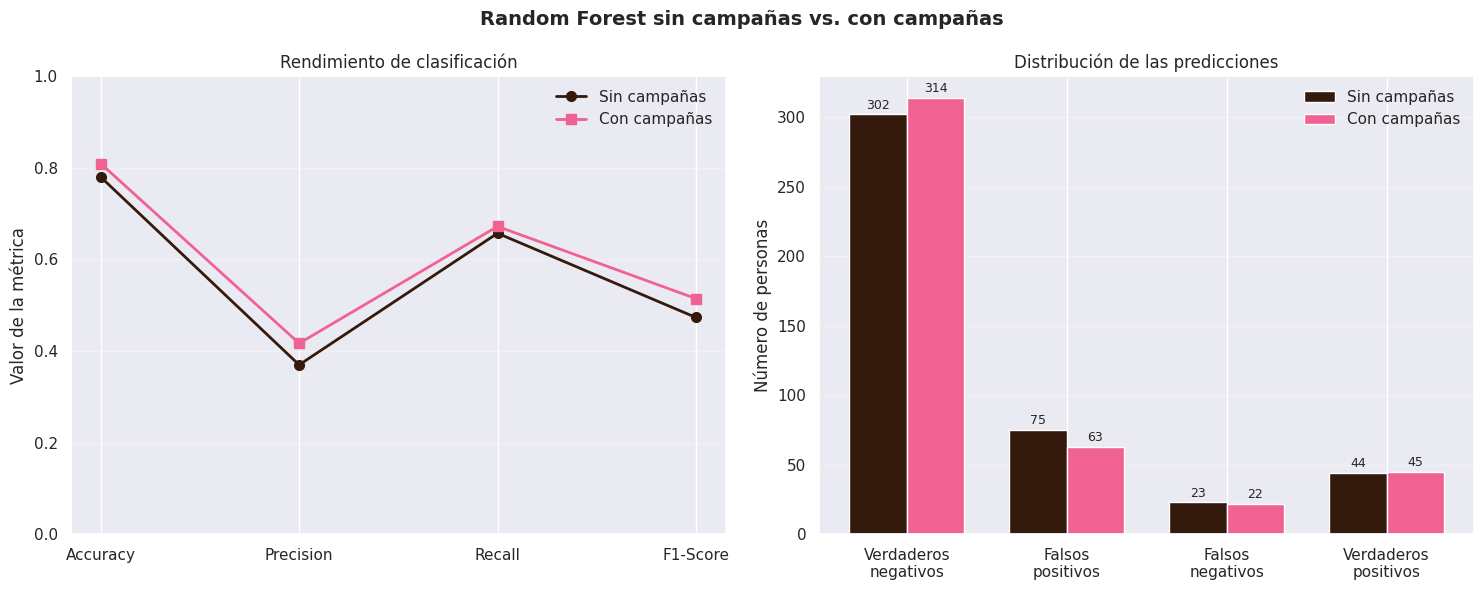

In [63]:
metricas = ["Accuracy", "Precision", "Recall", "F1-Score"]

valores_sin = [
    accuracy_score(y_test_sin, y_test_pred_sin),
    precision_score(y_test_sin, y_test_pred_sin, zero_division=0),
    recall_score(y_test_sin, y_test_pred_sin, zero_division=0),
    f1_score(y_test_sin, y_test_pred_sin, zero_division=0)]
valores_con = [
    accuracy_score(y_test_con, y_test_pred_con),
    precision_score(y_test_con, y_test_pred_con, zero_division=0),
    recall_score(y_test_con, y_test_pred_con, zero_division=0),
    f1_score(y_test_con, y_test_pred_con, zero_division=0)]

tn_sin, fp_sin, fn_sin, tp_sin = confusion_matrix(
    y_test_sin, y_test_pred_sin, labels=[0, 1]
).ravel()

tn_con, fp_con, fn_con, tp_con = confusion_matrix(
    y_test_con, y_test_pred_con, labels=[0, 1]
).ravel()

tipos_error = ["Verdaderos\nnegativos", "Falsos\npositivos", "Falsos\nnegativos", "Verdaderos\npositivos"]

conteos_sin = [tn_sin, fp_sin, fn_sin, tp_sin]
conteos_con = [tn_con, fp_con, fn_con, tp_con]

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
ax = axes[0]

ax.plot(
    metricas, valores_sin,
    marker="o", linewidth=2, markersize=7,
    color=c_sin, label="Sin campañas"
)

ax.plot(metricas, valores_con, marker="s", linewidth=2, markersize=7, color=c_con, label="Con campañas")

ax.set_ylim(0, 1)
ax.set_ylabel("Valor de la métrica")
ax.set_title("Rendimiento de clasificación")
ax.grid(axis="y", alpha=0.3)
ax.legend(frameon=False)

ax = axes[1]
x = np.arange(len(tipos_error))
w = 0.36

barras_sin = ax.bar(x - w/2, conteos_sin, w, color=c_sin, label="Sin campañas")
barras_con = ax.bar(x + w/2, conteos_con, w, color=c_con, label="Con campañas")

ax.bar_label(barras_sin, padding=2, fontsize=9)
ax.bar_label(barras_con, padding=2, fontsize=9)

ax.set_xticks(x)
ax.set_xticklabels(tipos_error)
ax.set_ylabel("Número de personas")
ax.set_title("Distribución de las predicciones")
ax.grid(axis="y", alpha=0.3)
ax.legend(frameon=False)

plt.suptitle(
    "Random Forest sin campañas vs. con campañas",
    fontsize=14,
    fontweight="bold"
)

plt.tight_layout()
plt.savefig(
    "comparacion_final_RF.png",
    dpi=200,
    bbox_inches="tight"
)
plt.show()


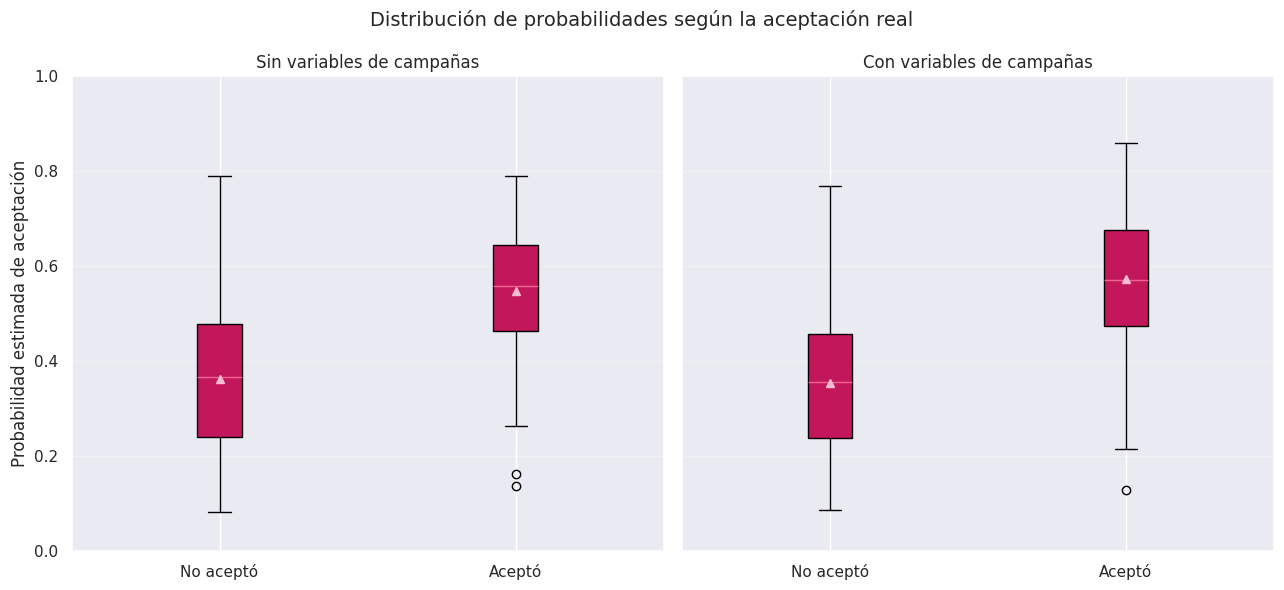

In [64]:
idx_sin = list(final_sinCampañas.classes_).index(1)
idx_con = list(final_conCampañas.classes_).index(1)

prob_sin = final_sinCampañas.predict_proba(X_test_sin)[:, idx_sin]
prob_con = final_conCampañas.predict_proba(X_test_con)[:, idx_con]
datos_boxplot = [prob_sin[np.asarray(y_test_sin) == 0], prob_sin[np.asarray(y_test_sin) == 1], prob_con[np.asarray(y_test_con) == 0], prob_con[np.asarray(y_test_con) == 1]]

fig, axes = plt.subplots(1, 2, figsize=(13, 6), sharey=True)
axes[0].boxplot(datos_boxplot[:2], tick_labels=["No aceptó", "Aceptó"], patch_artist=True, showmeans=True)
axes[0].set_title("Sin variables de campañas")
axes[0].set_ylabel("Probabilidad estimada de aceptación")
axes[0].set_ylim(0, 1)
axes[0].grid(axis="y", alpha=0.3)

axes[1].boxplot(datos_boxplot[2:], tick_labels=["No aceptó", "Aceptó"], patch_artist=True, showmeans=True)
axes[1].set_title("Con variables de campañas")
axes[1].set_ylim(0, 1)
axes[1].grid(axis="y", alpha=0.3)

fig.suptitle("Distribución de probabilidades según la aceptación real", fontsize=14)

plt.tight_layout()
plt.savefig("distribucion_probabilidades_aceptacion.png", dpi=200, bbox_inches="tight")
plt.show()


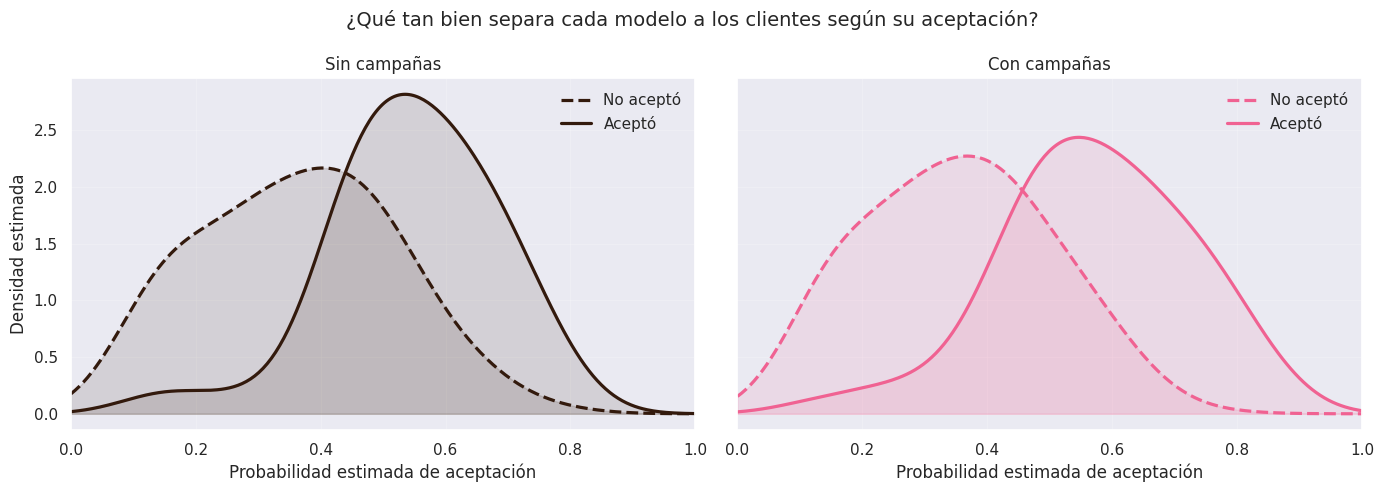

In [65]:
from sklearn.neighbors import KernelDensity

idx_sin = list(final_sinCampañas.classes_).index(1)
idx_con = list(final_conCampañas.classes_).index(1)

prob_sin = final_sinCampañas.predict_proba(X_test_sin)[:, idx_sin]
prob_con = final_conCampañas.predict_proba(X_test_con)[:, idx_con]

y_sin = np.asarray(y_test_sin)
y_con = np.asarray(y_test_con)

x_prob = np.linspace(0, 1, 300)

fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)

escenarios = [
    (axes[0], prob_sin, y_sin, c_sin, "Sin campañas"),
    (axes[1], prob_con, y_con, c_con, "Con campañas")
]

for ax, probabilidades, etiquetas, color, titulo in escenarios:
    for clase, nombre, estilo in [
        (0, "No aceptó", "--"),
        (1, "Aceptó", "-")
    ]:
        valores = probabilidades[etiquetas == clase]

        if len(valores) < 2:
            continue

        kde = KernelDensity(kernel="gaussian", bandwidth=0.07)
        kde.fit(valores.reshape(-1, 1))
        densidad = np.exp(kde.score_samples(x_prob.reshape(-1, 1)))

        ax.plot(
            x_prob, densidad,
            color=color, linestyle=estilo, linewidth=2.3,
            label=nombre
        )
        ax.fill_between(x_prob, densidad, alpha=0.12, color=color)

    ax.set_title(titulo)
    ax.set_xlabel("Probabilidad estimada de aceptación")
    ax.set_xlim(0, 1)
    ax.grid(alpha=0.2)
    ax.legend(frameon=False)

axes[0].set_ylabel("Densidad estimada")

fig.suptitle(
    "¿Qué tan bien separa cada modelo a los clientes según su aceptación?",
    fontsize=14
)

plt.tight_layout()
plt.savefig(
    "distribuciones_probabilidad.png",
    dpi=200,
    bbox_inches="tight"
)
plt.show()


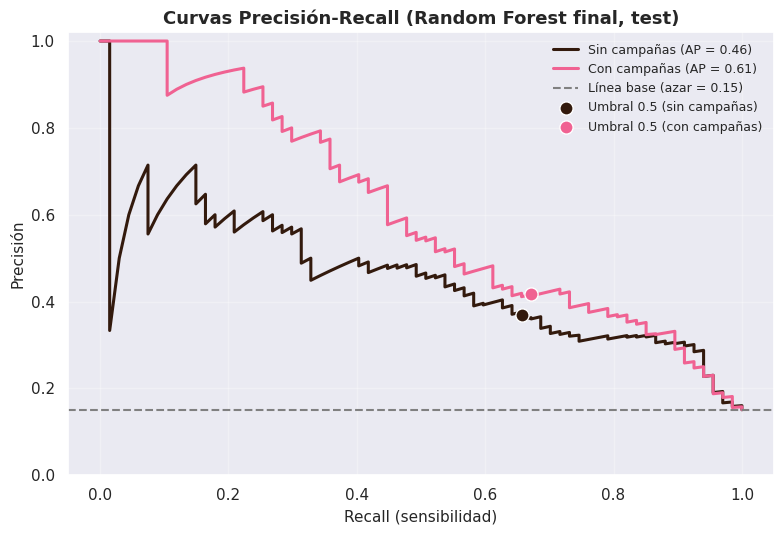

In [66]:
from sklearn.metrics import average_precision_score, precision_recall_curve

y_prob_sin = final_sinCampañas.predict_proba(X_test_sin)[:, list(final_sinCampañas.classes_).index(1)]
y_prob_con = final_conCampañas.predict_proba(X_test_con)[:, list(final_conCampañas.classes_).index(1)]

pre_s, rec_s, _ = precision_recall_curve(y_test_sin, y_prob_sin)
pre_c, rec_c, _ = precision_recall_curve(y_test_con, y_prob_con)
ap_s = average_precision_score(y_test_sin, y_prob_sin)
ap_c = average_precision_score(y_test_con, y_prob_con)

plt.figure(figsize=(8, 5.5))
plt.plot(rec_s, pre_s, color=c_sin, lw=2.2, label=f"Sin campañas (AP = {ap_s:.2f})")
plt.plot(rec_c, pre_c, color=c_con, lw=2.2, label=f"Con campañas (AP = {ap_c:.2f})")
plt.axhline(np.mean(y_test_sin), color='grey', ls='--', label=f"Línea base (azar = {np.mean(y_test_sin):.2f})")
plt.scatter(recall_score(y_test_sin, y_test_pred_sin, zero_division=0), precision_score(y_test_sin, y_test_pred_sin, zero_division=0),
            s=90, color=c_sin, edgecolor='white', zorder=3, label='Umbral 0.5 (sin campañas)')
plt.scatter(recall_score(y_test_con, y_test_pred_con, zero_division=0), precision_score(y_test_con, y_test_pred_con, zero_division=0),
            s=90, color=c_con, edgecolor='white', zorder=3, label='Umbral 0.5 (con campañas)')
plt.xlabel('Recall (sensibilidad)', fontsize=11); plt.ylabel('Precisión', fontsize=11)
plt.title('Curvas Precisión-Recall (Random Forest final, test)', fontsize=13, weight='bold')
plt.ylim(0, 1.02); plt.legend(loc='upper right', fontsize=9, frameon=False); plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("curvas_pr_test.png", dpi=200, bbox_inches="tight")
plt.show()


## 10.6 Importancia de las variables (Random Forest)


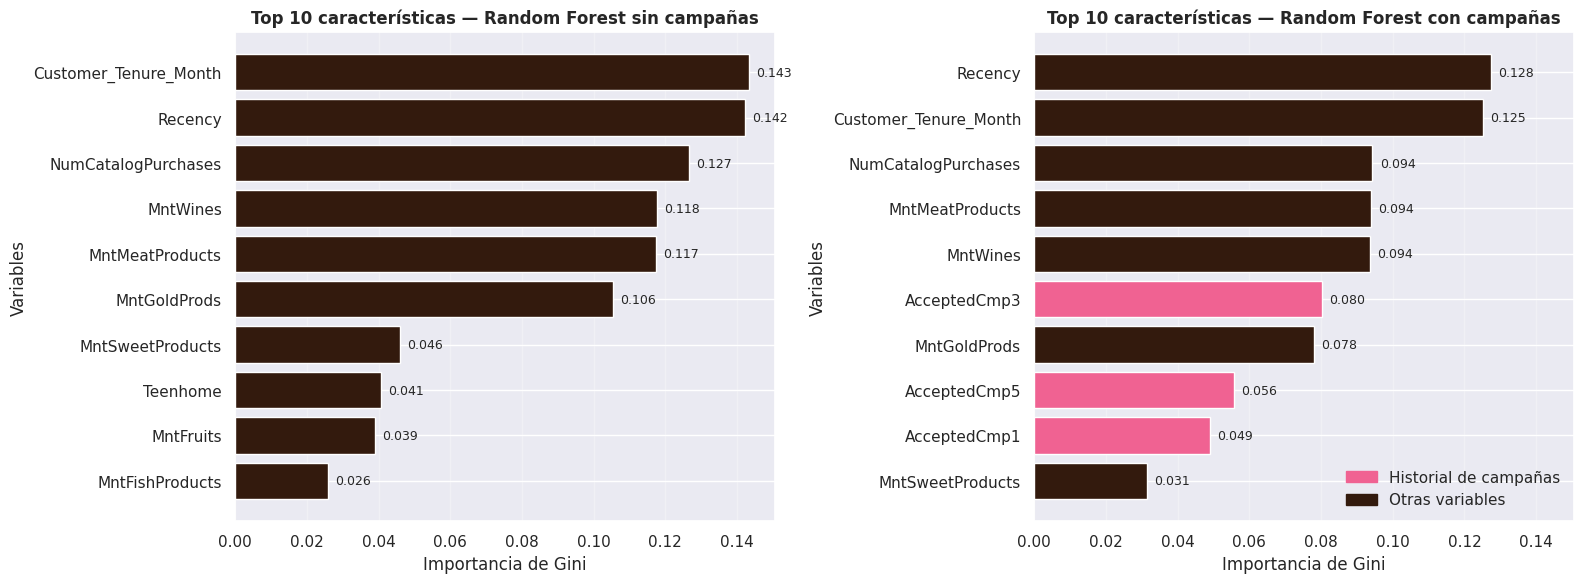

In [67]:
from matplotlib.patches import Patch

fig, axes = plt.subplots(1, 2, figsize=(16, 6), sharex=True)
for ax, (titulo, rf_m, cols) in zip(axes, [('Sin campañas', rf_sin, X_train_sin.columns),
                                            ('Con campañas', rf_con, X_train_con.columns)]):
    imp = pd.Series(rf_m.feature_importances_, index=cols).sort_values(ascending=False).head(10)
    colores = [c_con if n.startswith('AcceptedCmp') else c_sin for n in imp.index]
    ax.barh(imp.index[::-1], imp.values[::-1], color=colores[::-1])
    for i, v in enumerate(imp.values[::-1]):
        ax.text(v + 0.002, i, f"{v:.3f}", va='center', fontsize=9)
    ax.set_title(f'Top 10 características — Random Forest {titulo.lower()}', fontsize=12, weight='bold')
    ax.set_xlabel('Importancia de Gini'); ax.set_ylabel('Variables'); ax.grid(axis='x', alpha=0.3)
axes[1].legend(handles=[Patch(color=c_con, label='Historial de campañas'), Patch(color=c_sin, label='Otras variables')],
               frameon=False, loc='lower right')
plt.tight_layout()
plt.savefig("importancia_gini_sin_vs_con.png", dpi=200, bbox_inches="tight")
plt.show()


# 11. Regresión: predicción del gasto total del cliente
Segundo problema: predecir `MntTotal`, la suma del gasto en las seis categorías de producto (`MntWines`, `MntFruits`, `MntMeatProducts`, `MntFishProducts`, `MntSweetProducts`, `MntGoldProds`). Esas seis columnas se excluyen de las variables predictoras. Se comparan árbol de decisión, Random Forest y SVR.

## 11.1 Carga y preparación de los datos


In [68]:
cam_reg = df_original.copy()


In [69]:
del cam_reg['Z_CostContact']
del cam_reg['Z_Revenue']
del cam_reg['ID']
cam_reg = cam_reg.dropna(subset=['Income'])

cam_reg['Age'] = 2021 - cam_reg['Year_Birth']
cam_reg['Dt_Customer']= pd.to_datetime(cam_reg['Dt_Customer'], format='%d-%m-%Y', errors= 'coerce')
fecha_referencia = pd.Timestamp('2021-12-31')
cam_reg['Customer_Tenure_Month'] = ((fecha_referencia - cam_reg['Dt_Customer']) / pd.Timedelta(days = 30)).round(1)
cam_reg = cam_reg.sample(frac=1, random_state=SEED)


In [70]:
gastos= ['MntWines', 'MntFruits', 'MntMeatProducts', 'MntFishProducts', 'MntSweetProducts', 'MntGoldProds']
cam_reg['MntTotal']= cam_reg[gastos].sum(axis=1)
display(cam_reg.head())
print("Valores nulos en Income luego del EDA: ", cam_reg['Income'].isnull().sum())


,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,MntFruits,...,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Complain,Response,Age,Customer_Tenure_Month,MntTotal
730,1949,PhD,Divorced,35946.0,1,1,2013-09-27,24,8,0,...,0,0,0,0,0,0,0,72,100.6,11
1963,1952,Graduation,Single,40887.0,1,1,2013-05-06,32,50,4,...,0,0,0,0,0,0,1,69,105.4,161
153,1988,Graduation,Alone,34176.0,1,0,2014-05-12,12,5,7,...,0,0,0,0,0,0,0,33,93.0,89
1078,1968,Master,Single,50014.0,1,0,2014-01-22,9,234,14,...,0,0,0,0,0,0,0,53,96.7,396
1784,1971,Graduation,Together,34600.0,1,1,2013-01-01,8,199,33,...,0,0,0,0,0,0,1,50,109.5,318


Valores nulos en Income luego del EDA:  0


## 11.2 Variables predictoras, objetivo y partición


In [71]:
y_reg = cam_reg['MntTotal'].copy()
columnas_a_excluir = ['MntTotal','ID','Dt_Customer','Z_CostContact','Z_Revenue', 'MntWines','MntFruits',"MntMeatProducts",'MntFishProducts','MntSweetProducts','MntGoldProds',]
X_reg = cam_reg.drop(columns=[col for col in columnas_a_excluir if col in cam_reg.columns])
X_reg = pd.get_dummies(X_reg, drop_first=True)
print(f'Variables predictoras (X) listas. Total de columnas en X: {X_reg.shape[1]}')
display(X_reg.head())
display(y_reg.head())


Variables predictoras (X) listas. Total de columnas en X: 30


,Year_Birth,Income,Kidhome,Teenhome,Recency,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,...,Education_Graduation,Education_Master,Education_PhD,Marital_Status_Alone,Marital_Status_Divorced,Marital_Status_Married,Marital_Status_Single,Marital_Status_Together,Marital_Status_Widow,Marital_Status_YOLO
730,1949,35946.0,1,1,24,1,0,0,3,5,...,False,False,True,False,True,False,False,False,False,False
1963,1952,40887.0,1,1,32,3,3,1,3,9,...,True,False,False,False,False,False,True,False,False,False
153,1988,34176.0,1,0,12,4,3,0,4,6,...,True,False,False,True,False,False,False,False,False,False
1078,1968,50014.0,1,0,9,2,4,1,8,5,...,False,True,False,False,False,False,True,False,False,False
1784,1971,34600.0,1,1,8,5,5,2,5,8,...,True,False,False,False,False,False,False,True,False,False


,MntTotal
730,11
1963,161
153,89
1078,396
1784,318


In [72]:
bins = pd.qcut(y_reg, q=5, labels=False)
X_dev_reg, X_test_reg, y_dev_reg, y_test_reg = train_test_split(
    X_reg, y_reg, test_size=0.2, random_state=SEED, stratify=bins)

bins_dev = pd.qcut(y_dev_reg, q=5, labels=False)
X_train_reg, X_val_reg, y_train_reg, y_val_reg = train_test_split(
    X_dev_reg, y_dev_reg, test_size=0.25, random_state=SEED, stratify= bins_dev)

print(f"Train: {len(y_train_reg)} | Validación: {len(y_val_reg)} | Test: {len(y_test_reg)}")


Train: 1329 | Validación: 443 | Test: 444


## 11.3 Ajuste de hiperparámetros con validación cruzada
Validación cruzada de 10 folds; métricas MSE, RMSE y MAE.

### Configuración y función auxiliar


In [73]:
bins_train = pd.qcut(y_train_reg, q=5, labels=False)
cv_reg = list(StratifiedKFold(n_splits=10, shuffle=True, random_state=SEED).split(X_train_reg, bins_train))

scoring_reg = {
    "MSE": make_scorer(mean_squared_error, greater_is_better=False),
    "RMSE": make_scorer(root_mean_squared_error, greater_is_better=False),
    "MAE": make_scorer(mean_absolute_error, greater_is_better=False)
}


In [76]:
def variaciones_reg(nombre, valores, crear_modelo, log=False, etiquetas=None):
    metricas = ['MSE', 'RMSE', 'MAE']
    filas = []

    for v in valores:
        sc = cross_validate(crear_modelo(v), X_train_reg, y_train_reg, cv=cv_reg, scoring=scoring_reg,
                            return_train_score=True, n_jobs=-2)
        fila = {nombre: v if etiquetas is None else str(v)}
        for m in metricas:
            fila[f'{m} train'] = -sc[f'train_{m}'].mean()
            fila[f'{m} CV'] = -sc[f'test_{m}'].mean()
            fila[f'{m} desv. CV'] = sc[f'test_{m}'].std()
        filas.append(fila)

    df = pd.DataFrame(filas)
    for m in metricas:
        df[f'{m} brecha'] = df[f'{m} CV'] - df[f'{m} train']
    if etiquetas is not None:
        df[nombre] = etiquetas
    display(df.round(3))

    x = np.arange(len(df)) if etiquetas is not None else df[nombre].values

    c_train, c_cv, c_brecha = cafe_palette_1[1], rosa_palette_1[0], rosa_palette_1[1]

    fig, axes = plt.subplots(1, 3, figsize=(18, 5))
    for a, m in zip(axes, metricas):
        a.plot(x, df[f'{m} train'], marker='o', color=c_train, label='Train')
        a.errorbar(x, df[f'{m} CV'], yerr=df[f'{m} desv. CV'], marker='s', capsize=4,
                   color=c_cv, label='Validación cruzada')
        a.fill_between(x, df[f'{m} train'], df[f'{m} CV'], alpha=0.15,
                       color=c_brecha, label='Brecha')
        if etiquetas is not None:
            a.set_xticks(x)
            a.set_xticklabels(etiquetas)
        elif log:
            a.set_xscale('log')
        a.set_xlabel(nombre, fontsize=12, color='black')
        a.set_ylabel(f'{m} (error)', fontsize=12, color='black')
        a.set_title(f'{m}: train vs CV', fontsize=13, color='black')
        a.tick_params(colors='black')
        a.margins(y=0.2)
        a.grid(alpha=0.3)
        a.legend()

    plt.tight_layout()
    plt.show()

### Árbol de decisión


,max_depth,MSE train,MSE CV,MSE desv. CV,RMSE train,RMSE CV,RMSE desv. CV,MAE train,MAE CV,MAE desv. CV,MSE brecha,RMSE brecha,MAE brecha
0,2,78977.683,80659.932,14380.411,281.015,282.915,24.883,187.115,189.219,13.488,1682.248,1.900,2.104
1,3,64054.612,70700.047,9946.186,253.079,265.241,18.632,164.779,173.294,10.277,6645.435,12.162,8.515
2,4,50758.043,63538.926,9232.130,225.282,251.437,17.841,142.023,157.347,12.296,12780.883,26.155,15.325
3,5,39098.621,61781.459,12477.880,197.720,247.450,23.455,121.248,147.993,13.708,22682.838,49.730,26.745
4,6,29739.415,59535.834,10837.946,172.410,243.089,21.064,101.954,142.011,12.386,29796.419,70.679,40.057
5,8,15451.918,70621.626,16090.590,124.228,264.200,28.636,64.403,145.665,16.624,55169.707,139.972,81.262
6,10,7118.736,77688.651,18055.447,84.202,277.082,30.240,34.881,147.706,15.720,70569.915,192.880,112.826
7,15,253.931,84823.278,15655.699,13.946,290.085,25.961,2.656,153.393,15.389,84569.348,276.139,150.737


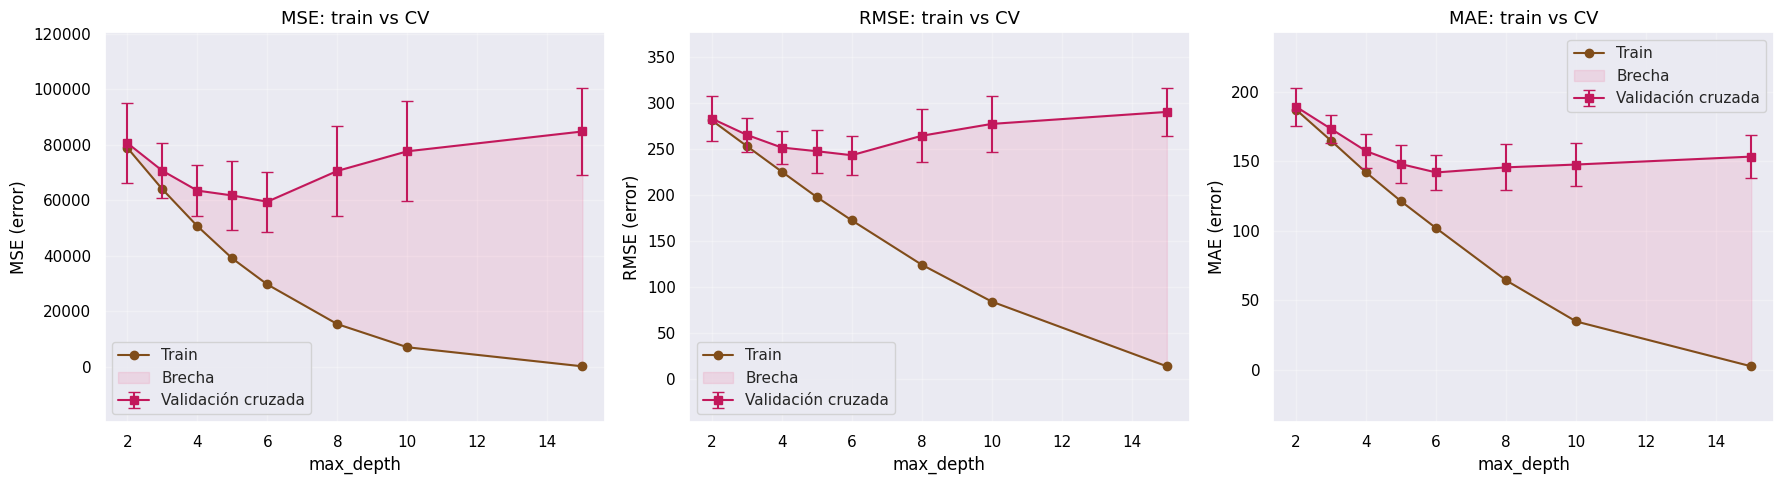

,min_samples_leaf,MSE train,MSE CV,MSE desv. CV,RMSE train,RMSE CV,RMSE desv. CV,MAE train,MAE CV,MAE desv. CV,MSE brecha,RMSE brecha,MAE brecha
0,1,64054.612,70700.047,9946.186,253.079,265.241,18.632,164.779,173.294,10.277,6645.435,12.162,8.515
1,2,64054.612,70700.047,9946.186,253.079,265.241,18.632,164.779,173.294,10.277,6645.435,12.162,8.515
2,5,64054.612,70700.047,9946.186,253.079,265.241,18.632,164.779,173.294,10.277,6645.435,12.162,8.515
3,10,64054.612,70700.047,9946.186,253.079,265.241,18.632,164.779,173.294,10.277,6645.435,12.162,8.515
4,20,64448.545,72216.802,13950.256,253.855,267.561,25.057,164.395,173.854,11.520,7768.257,13.707,9.459
5,40,65692.040,72099.627,15316.218,256.286,267.087,27.648,163.119,170.630,13.327,6407.587,10.801,7.511
6,80,66855.452,71368.342,14104.977,258.540,265.873,26.071,165.486,170.170,15.342,4512.891,7.333,4.685


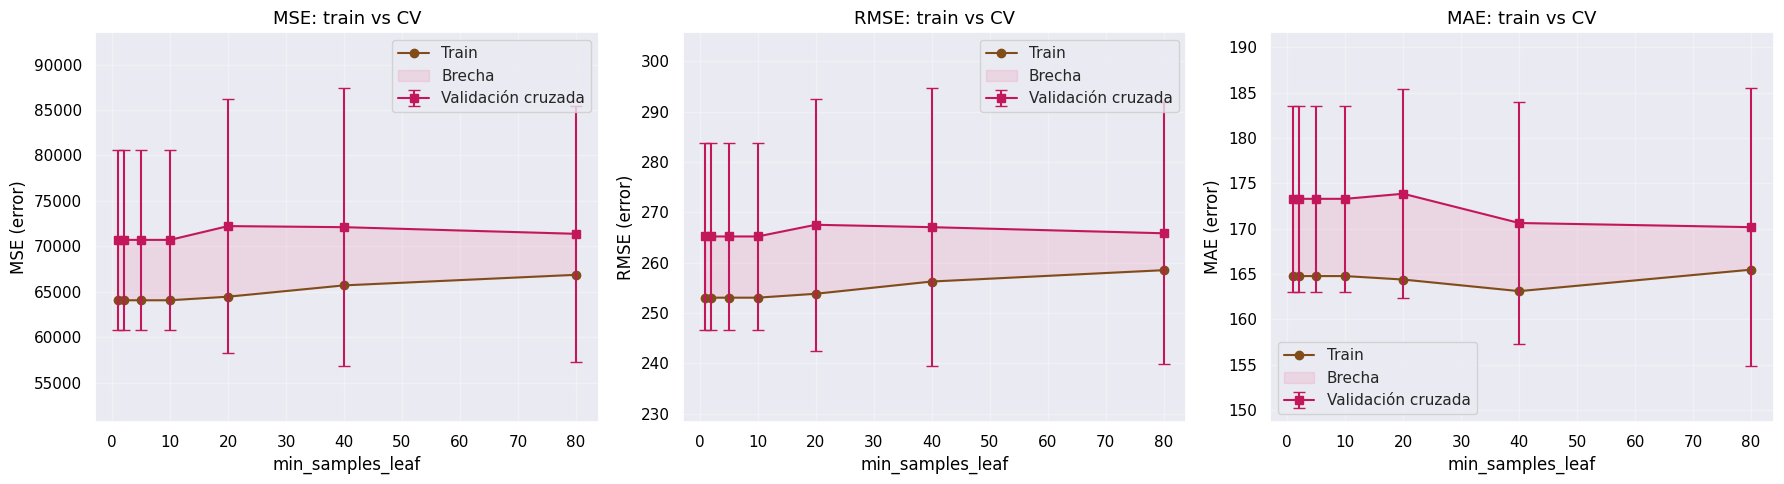

In [99]:
variaciones_reg('max_depth', [2, 3, 4, 5, 6, 8, 10, 15],
                lambda v: DecisionTreeRegressor(max_depth=v, random_state=SEED))

variaciones_reg('min_samples_leaf', [1, 2, 5, 10, 20, 40, 80],
                lambda v: DecisionTreeRegressor(min_samples_leaf=v, max_depth=3, random_state=SEED))


### Random Forest


,max_depth,MSE train,MSE CV,MSE desv. CV,RMSE train,RMSE CV,RMSE desv. CV,MAE train,MAE CV,MAE desv. CV,MSE brecha,RMSE brecha,MAE brecha
0,2,67341.716,71561.366,12772.258,259.487,266.518,23.016,174.248,179.278,13.479,4219.650,7.030,5.029
1,3,53783.514,62042.209,9468.026,231.903,248.384,18.648,149.694,159.887,9.664,8258.695,16.481,10.193
2,4,41486.052,54451.051,8787.107,203.672,232.595,18.725,127.634,144.645,10.788,12964.999,28.922,17.011
3,5,31321.483,49960.941,8543.807,176.965,222.703,19.082,107.560,132.874,11.397,18639.458,45.739,25.315
4,6,23444.724,47430.970,8500.743,153.100,216.915,19.466,91.387,125.869,11.302,23986.246,63.815,34.481
5,8,13190.416,45109.165,8870.836,114.830,211.353,20.955,66.408,117.831,11.263,31918.748,96.522,51.424
6,10,8473.706,44266.027,8997.846,92.036,209.318,21.262,51.665,114.745,11.574,35792.321,117.282,63.080
7,15,5995.921,43327.481,8711.758,77.421,207.127,20.636,41.692,112.551,10.858,37331.560,129.707,70.859


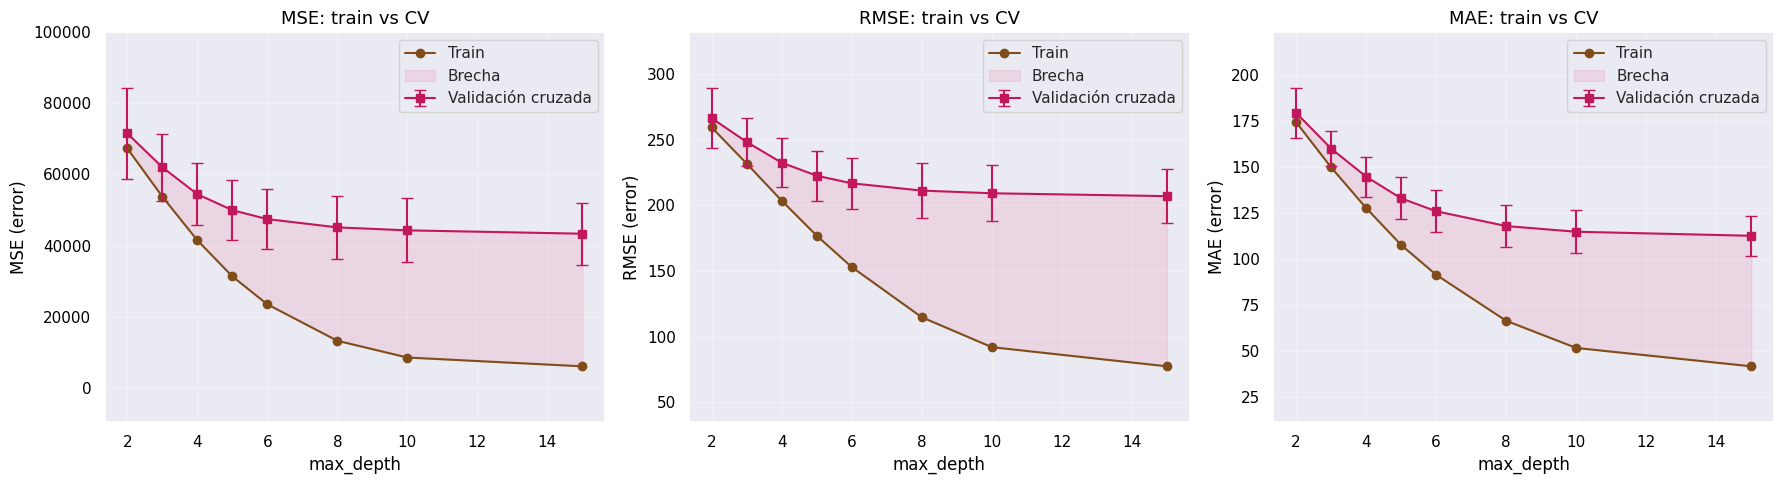

,min_samples_leaf,MSE train,MSE CV,MSE desv. CV,RMSE train,RMSE CV,RMSE desv. CV,MAE train,MAE CV,MAE desv. CV,MSE brecha,RMSE brecha,MAE brecha
0,1,53783.514,62042.209,9468.026,231.903,248.384,18.648,149.694,159.887,9.664,8258.695,16.481,10.193
1,2,53790.913,62012.243,9458.914,231.919,248.325,18.625,149.653,159.839,9.651,8221.330,16.407,10.186
2,5,53800.303,61871.808,9588.191,231.939,248.025,18.858,149.532,159.689,9.655,8071.505,16.085,10.156
3,10,54060.854,61603.901,10003.387,232.500,247.427,19.596,149.429,159.208,9.887,7543.048,14.927,9.779
4,20,54802.279,62149.193,11530.822,234.088,248.292,22.364,148.606,158.143,11.687,7346.914,14.204,9.537
5,40,55862.883,62372.244,11434.277,236.344,248.768,22.063,149.697,158.284,12.647,6509.361,12.424,8.588
6,80,64242.327,68299.612,12254.195,253.447,260.375,22.455,164.517,169.525,13.252,4057.285,6.928,5.008


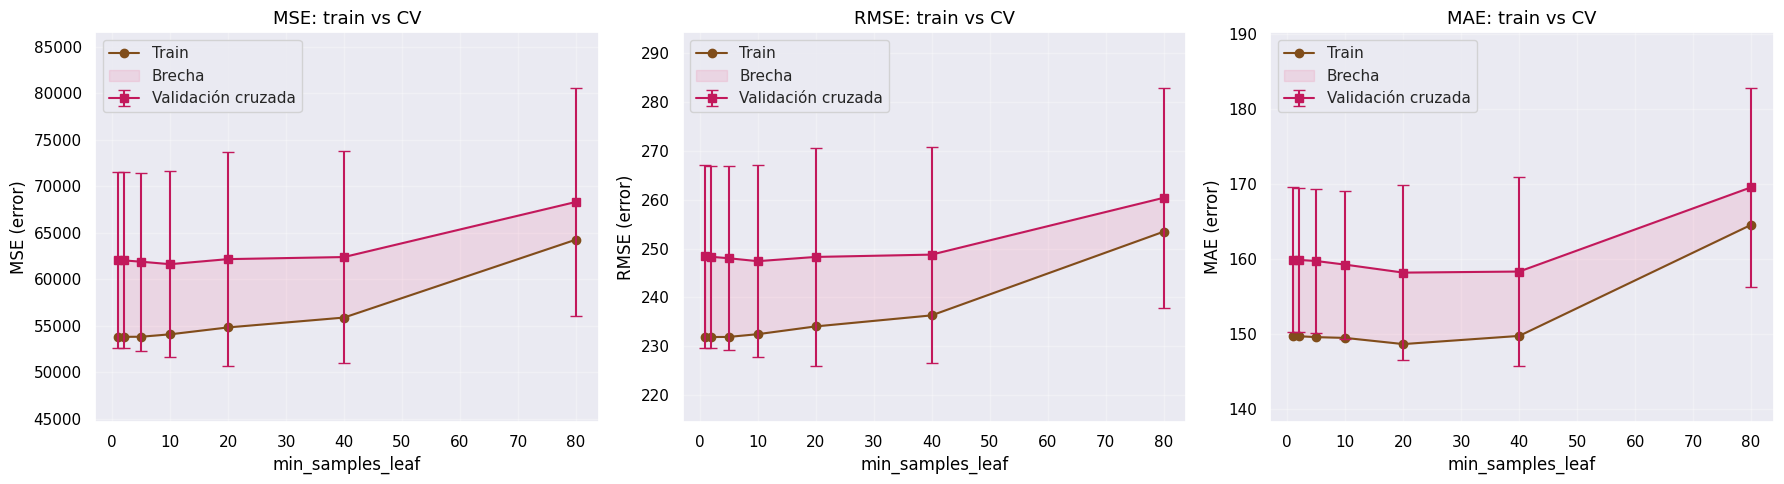

,n_estimators,MSE train,MSE CV,MSE desv. CV,RMSE train,RMSE CV,RMSE desv. CV,MAE train,MAE CV,MAE desv. CV,MSE brecha,RMSE brecha,MAE brecha
0,10,57239.806,62879.103,11007.627,239.231,249.843,21.392,151.750,159.732,12.650,5639.297,10.612,7.983
1,25,56195.169,62409.577,10786.693,237.042,248.950,20.823,150.345,158.879,11.745,6214.408,11.907,8.534
2,50,55832.448,62263.376,11824.404,236.279,248.486,22.756,149.969,158.382,12.771,6430.929,12.208,8.413
3,100,55862.883,62372.244,11434.277,236.344,248.768,22.063,149.697,158.284,12.647,6509.361,12.424,8.588
4,200,55943.395,62348.993,11542.464,236.514,248.699,22.317,149.697,158.211,12.458,6405.598,12.185,8.514
5,400,55911.024,62285.141,11469.470,236.446,248.585,22.155,149.664,157.928,12.200,6374.116,12.139,8.264


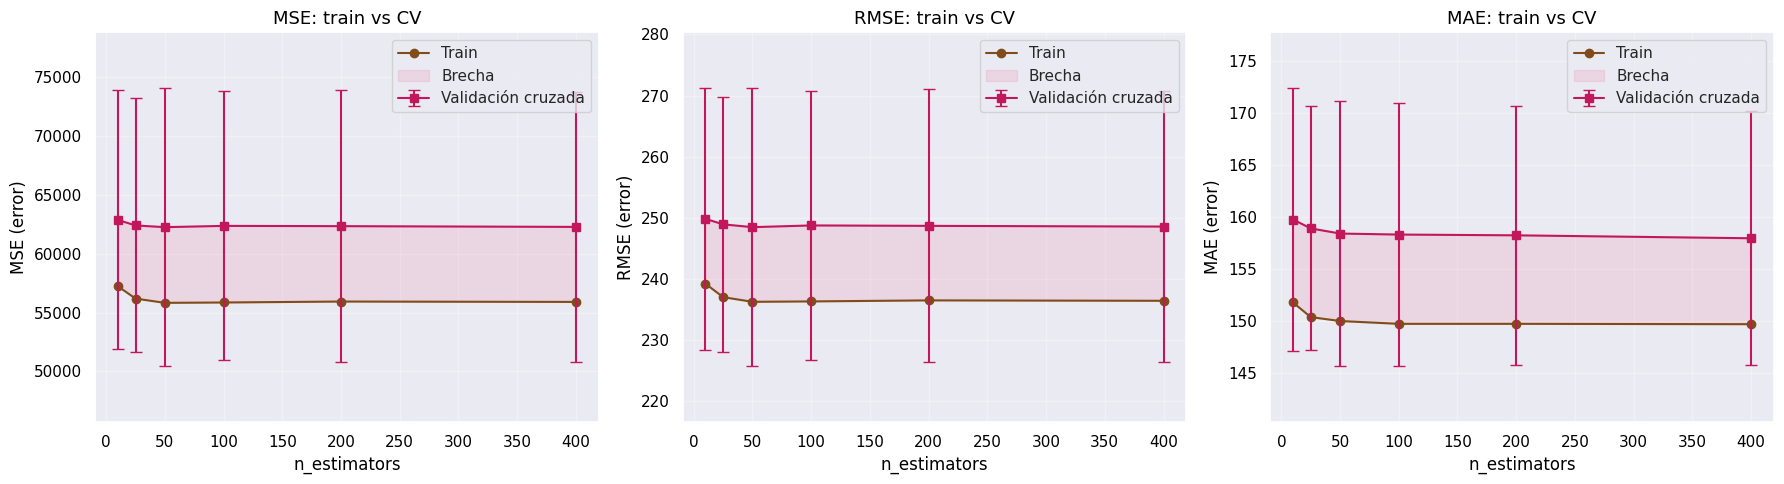

,max_features,MSE train,MSE CV,MSE desv. CV,RMSE train,RMSE CV,RMSE desv. CV,MAE train,MAE CV,MAE desv. CV,MSE brecha,RMSE brecha,MAE brecha
0,0.2,67415.068,70760.524,9510.931,259.636,265.433,17.493,182.350,187.280,11.560,3345.456,5.797,4.930
1,0.4,57041.008,61302.928,9890.263,238.822,246.839,19.324,154.811,160.737,11.708,4261.920,8.017,5.926
2,0.6,54975.165,60095.773,11004.997,234.458,244.206,21.434,148.957,155.643,12.049,5120.608,9.748,6.686
3,0.8,55098.948,60861.048,11105.540,234.720,245.752,21.612,147.954,155.412,12.644,5762.100,11.032,7.458
4,1.0,55862.883,62372.244,11434.277,236.344,248.768,22.063,149.697,158.284,12.647,6509.361,12.424,8.588


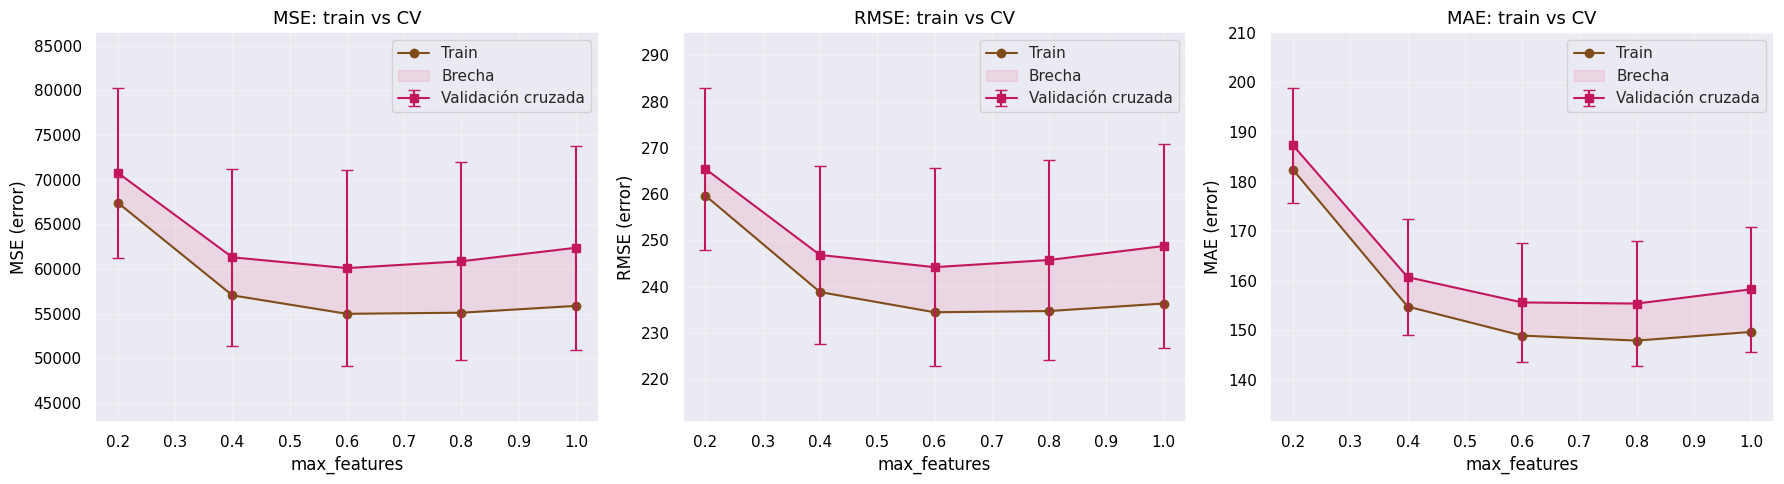

In [101]:
variaciones_reg('max_depth', [2, 3, 4, 5, 6, 8, 10, 15],
                lambda v: RandomForestRegressor(n_estimators=100, max_depth=v, random_state=SEED, n_jobs=-2))

variaciones_reg('min_samples_leaf', [1, 2, 5, 10, 20, 40, 80],
                lambda v: RandomForestRegressor(n_estimators=100, max_depth=3, min_samples_leaf=v, random_state=SEED, n_jobs=-2))

variaciones_reg('n_estimators', [10, 25, 50, 100, 200, 400],
                lambda v: RandomForestRegressor(n_estimators=v,random_state=SEED, max_depth=3, min_samples_leaf=40, n_jobs=-2))

variaciones_reg('max_features', [0.2, 0.4, 0.6, 0.8, 1.0],
                lambda v: RandomForestRegressor(n_estimators=100, max_features=v,max_depth=3, min_samples_leaf=40, random_state=SEED, n_jobs=-2))


### SVR


,kernel SVR,MSE train,MSE CV,MSE desv. CV,RMSE train,RMSE CV,RMSE desv. CV,MAE train,MAE CV,MAE desv. CV,MSE brecha,RMSE brecha,MAE brecha
0,linear,71865.744,73470.218,15066.527,268.056,269.530,28.704,153.198,157.036,14.590,1604.474,1.474,3.838
1,poly,223202.486,235101.054,18335.694,472.418,484.495,19.128,340.717,356.470,13.882,11898.568,12.077,15.753
2,rbf,157889.604,161918.157,12356.934,397.351,402.085,15.680,247.929,253.898,8.222,4028.553,4.734,5.970
3,sigmoid,91338.061,91766.854,9289.805,302.211,302.519,15.786,181.729,182.807,12.046,428.794,0.308,1.078


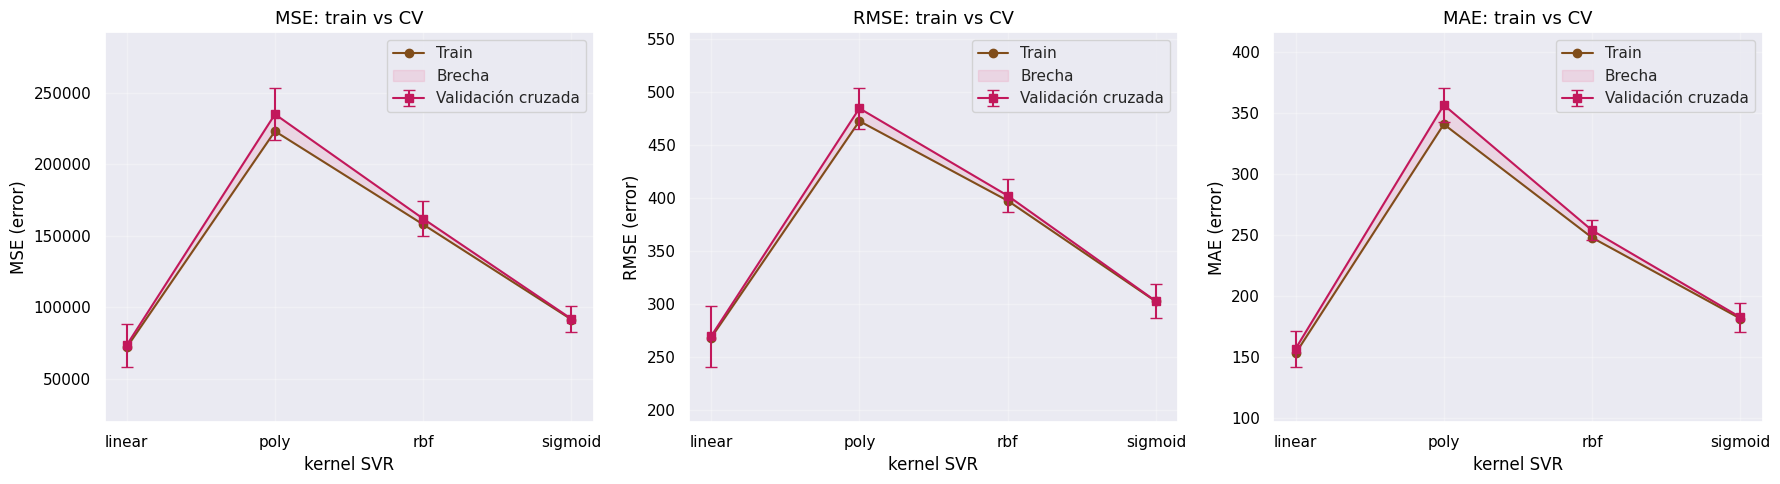

,C SVR,MSE train,MSE CV,MSE desv. CV,RMSE train,RMSE CV,RMSE desv. CV,MAE train,MAE CV,MAE desv. CV,MSE brecha,RMSE brecha,MAE brecha
0,0.1,158223.450,159194.135,8730.059,397.767,398.841,10.956,252.083,254.058,9.013,970.685,1.074,1.975
1,1.0,73792.194,76293.982,13623.041,271.627,275.017,25.681,158.993,163.556,13.661,2501.787,3.390,4.563
2,10.0,71865.744,73470.218,15066.527,268.056,269.530,28.704,153.198,157.036,14.590,1604.474,1.474,3.838
3,100.0,72281.043,74385.911,15809.564,268.832,271.099,29.856,153.045,157.476,14.605,2104.868,2.267,4.431
4,300.0,72270.228,74375.873,15816.195,268.811,271.079,29.870,153.044,157.495,14.620,2105.644,2.268,4.451


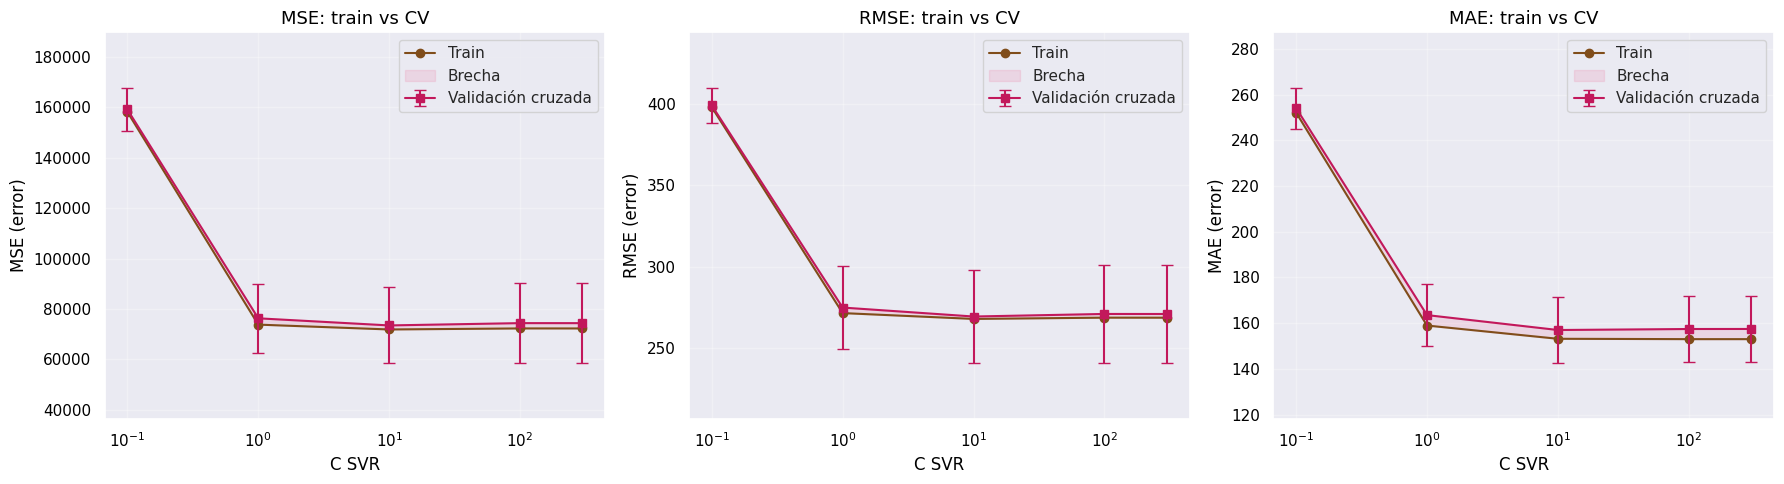

,gamma SVR,MSE train,MSE CV,MSE desv. CV,RMSE train,RMSE CV,RMSE desv. CV,MAE train,MAE CV,MAE desv. CV,MSE brecha,RMSE brecha,MAE brecha
0,0.001,71865.744,73470.218,15066.527,268.056,269.53,28.704,153.198,157.036,14.59,1604.474,1.474,3.838
1,0.005,71865.744,73470.218,15066.527,268.056,269.53,28.704,153.198,157.036,14.59,1604.474,1.474,3.838
2,0.010,71865.744,73470.218,15066.527,268.056,269.53,28.704,153.198,157.036,14.59,1604.474,1.474,3.838
3,0.100,71865.744,73470.218,15066.527,268.056,269.53,28.704,153.198,157.036,14.59,1604.474,1.474,3.838
4,0.500,71865.744,73470.218,15066.527,268.056,269.53,28.704,153.198,157.036,14.59,1604.474,1.474,3.838
5,1.000,71865.744,73470.218,15066.527,268.056,269.53,28.704,153.198,157.036,14.59,1604.474,1.474,3.838


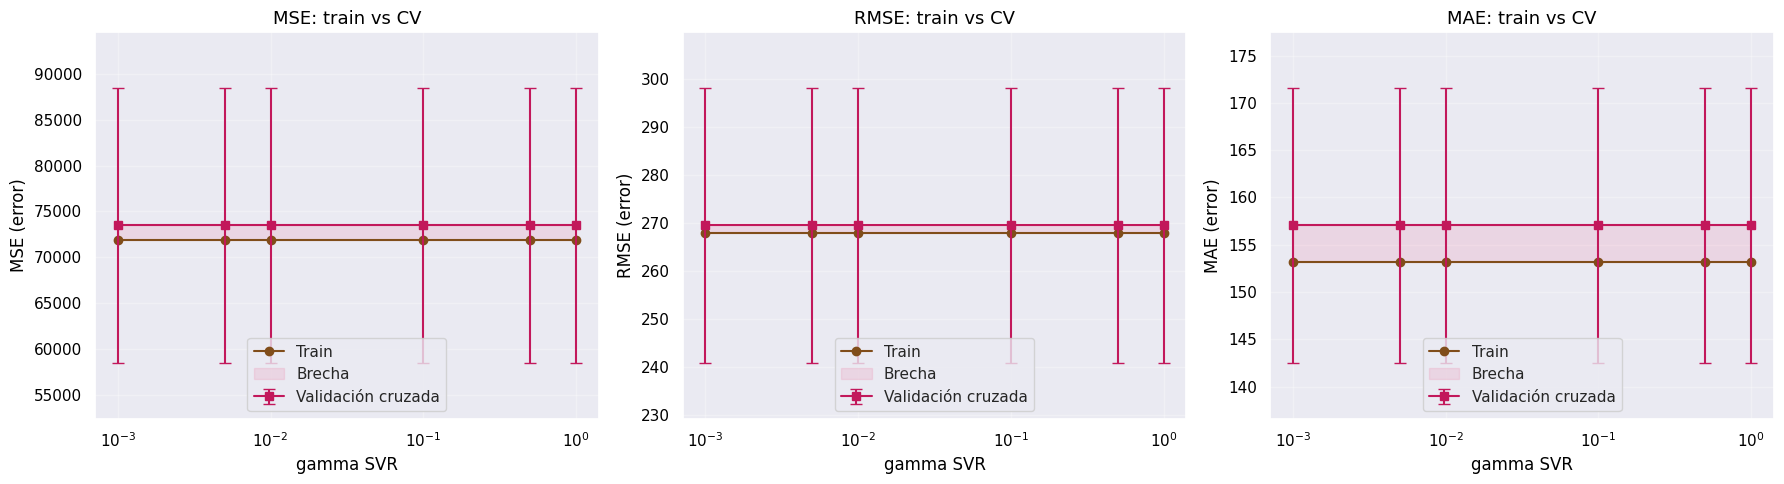

,epsilon SVR,MSE train,MSE CV,MSE desv. CV,RMSE train,RMSE CV,RMSE desv. CV,MAE train,MAE CV,MAE desv. CV,MSE brecha,RMSE brecha,MAE brecha
0,0.01,71861.677,73457.503,15057.994,268.048,269.508,28.690,153.197,157.012,14.584,1595.826,1.459,3.815
1,0.10,71865.744,73470.218,15066.527,268.056,269.530,28.704,153.198,157.036,14.590,1604.474,1.474,3.838
2,0.20,71870.123,73479.363,15080.220,268.064,269.544,28.731,153.199,157.049,14.606,1609.240,1.480,3.851
3,0.50,71886.801,73518.220,15091.478,268.095,269.614,28.750,153.199,157.077,14.671,1631.419,1.519,3.877
4,1.00,71885.058,73543.678,15102.548,268.092,269.660,28.765,153.204,157.092,14.700,1658.619,1.568,3.888
5,2.00,71779.701,73510.836,15055.256,267.895,269.608,28.676,153.225,157.200,14.738,1731.135,1.713,3.975


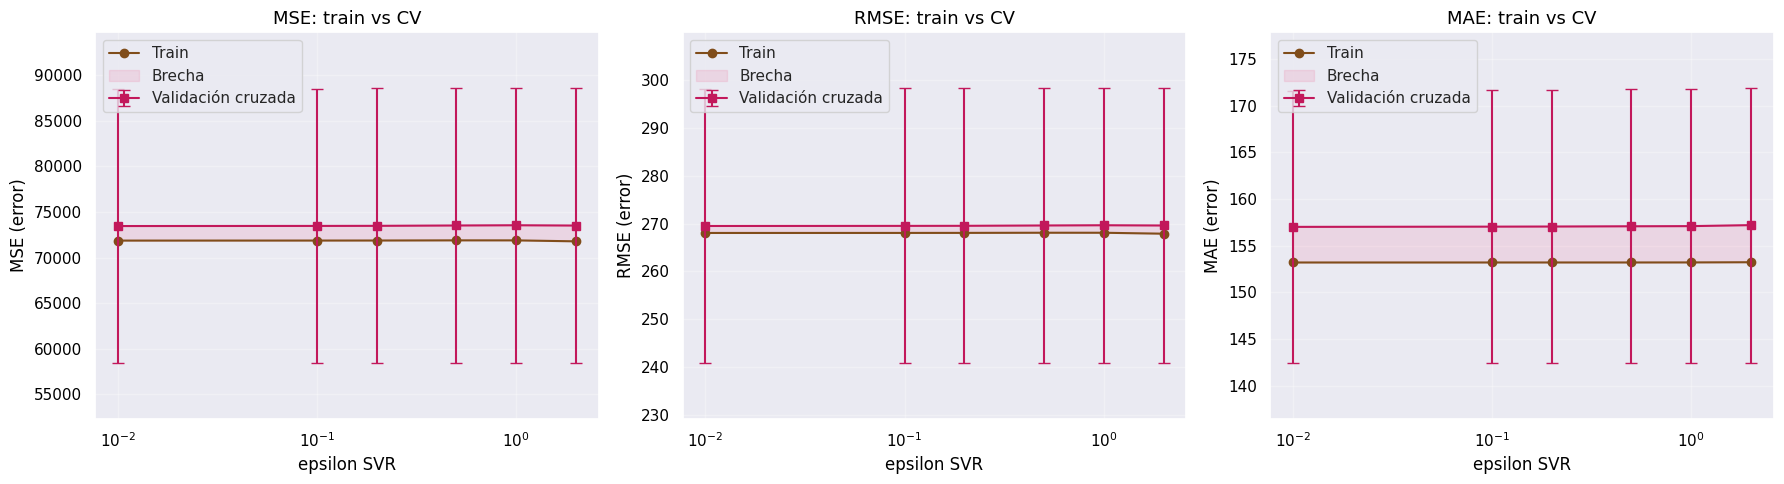

In [102]:
variaciones_reg('kernel SVR', ['linear', 'poly', 'rbf', 'sigmoid'],
        lambda v: make_pipeline(StandardScaler(), SVR(kernel=v, C=10)),
        etiquetas=['linear', 'poly', 'rbf', 'sigmoid'])

variaciones_reg('C SVR', [0.1, 1, 10, 100, 300],
        lambda v: make_pipeline(StandardScaler(), SVR(C=v, kernel='linear')),
        log=True)

variaciones_reg('gamma SVR', [0.001, 0.005, 0.01, 0.1, 0.5, 1],
        lambda v: make_pipeline(StandardScaler(), SVR(C=10, gamma=v, kernel='linear')),
        log=True)

variaciones_reg('epsilon SVR', [0.01, 0.1, 0.2, 0.5, 1, 2],
        lambda v: make_pipeline(StandardScaler(), SVR(C=10, gamma='scale',
                                                    epsilon=v, kernel='linear')),
        log=True)


## 11.4 Modelos con los hiperparámetros elegidos (conjunto de validación)


In [108]:
dt_reg = DecisionTreeRegressor(max_depth=3, min_samples_leaf=80, random_state=SEED)
dt_reg.fit(X_train_reg, y_train_reg)
y_pred_dtreg = dt_reg.predict(X_val_reg)
mse_dt = mean_squared_error(y_val_reg, y_pred_dtreg)
rmse_dt = root_mean_squared_error(y_val_reg, y_pred_dtreg)
mae_dt = mean_absolute_error(y_val_reg, y_pred_dtreg)

rf_reg = RandomForestRegressor(n_estimators=200, max_depth=4, min_samples_leaf=40, max_features=0.6,
                               random_state=SEED, n_jobs=-2)
rf_reg.fit(X_train_reg, y_train_reg)
y_pred_rfreg = rf_reg.predict(X_val_reg)
mse_rf = mean_squared_error(y_val_reg, y_pred_rfreg)
rmse_rf = root_mean_squared_error(y_val_reg, y_pred_rfreg)
mae_rf = mean_absolute_error(y_val_reg, y_pred_rfreg)


In [110]:
svr_reg = TransformedTargetRegressor(
    regressor=make_pipeline(StandardScaler(),
                            SVR(kernel='linear', C=10, gamma='scale', epsilon=0.01)),
    transformer=StandardScaler())
svr_reg.fit(X_train_reg, y_train_reg)
y_pred_svrreg = svr_reg.predict(X_val_reg)

mse_svr = mean_squared_error(y_val_reg, y_pred_svrreg)
rmse_svr = root_mean_squared_error(y_val_reg, y_pred_svrreg)
mae_svr = mean_absolute_error(y_val_reg, y_pred_svrreg)

metricas_regresion = pd.DataFrame({'Modelo': ['Decision Tree', 'Random Forest', 'SVR'],
                                   'MSE': [mse_dt, mse_rf, mse_svr],
                                   'RMSE': [rmse_dt, rmse_rf, rmse_svr],
                                   'MAE': [mae_dt, mae_rf, mae_svr]})
metricas_regresion = metricas_regresion.round(3)
metricas_regresion


,Modelo,MSE,RMSE,MAE
0,Decision Tree,78007.494,279.298,179.289
1,Random Forest,63417.293,251.828,154.325
2,SVR,82045.707,286.436,168.165


## 11.5 Evaluación final en el conjunto de prueba
Los dos mejores modelos (Random Forest y árbol de decisión) se reentrenan con entrenamiento + validación.


In [111]:
mejores = {'Random Forest': rf_reg, 'Decision Tree': dt_reg}
nombres = list(mejores)
colores = dict(zip(nombres, [rosa_palette_1[0], cafe_palette_1[1]]))

finales, pred_test, filas = {}, {}, []
for nombre, base in mejores.items():
    m_final = clone(base)
    m_final.fit(X_dev_reg, y_dev_reg)
    p = m_final.predict(X_test_reg)
    finales[nombre], pred_test[nombre] = m_final, p
    filas.append({'Modelo': nombre,
                  'MSE': mean_squared_error(y_test_reg, p),
                  'RMSE': root_mean_squared_error(y_test_reg, p),
                  'MAE': mean_absolute_error(y_test_reg, p)})

metricas_test_reg = pd.DataFrame(filas).round(3)
display(metricas_test_reg)


,Modelo,MSE,RMSE,MAE
0,Random Forest,53621.781,231.564,142.583
1,Decision Tree,65734.576,256.388,167.494


### 11.5.1 Validación vs. test


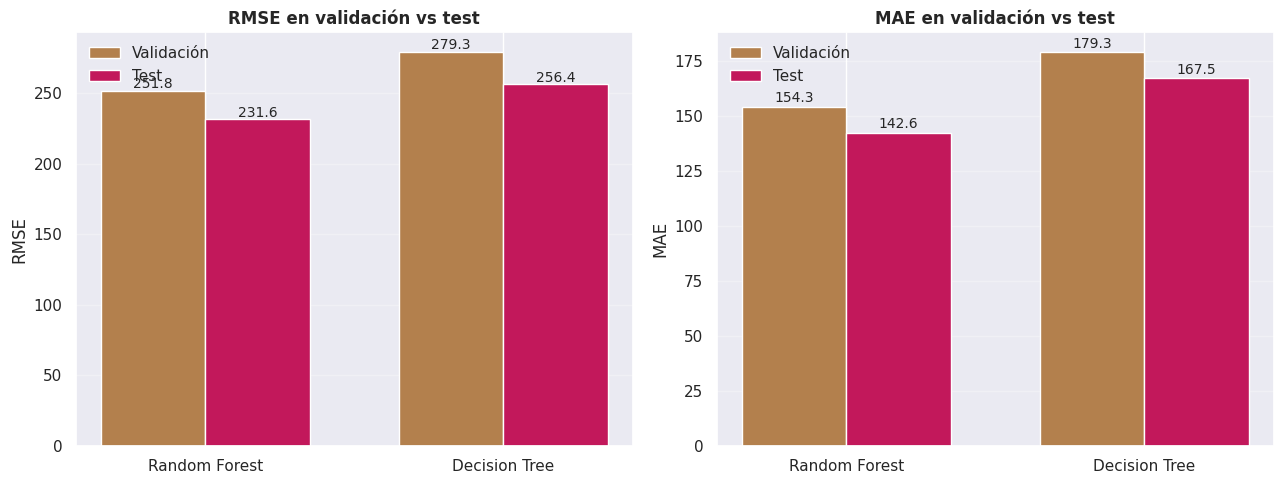

In [112]:
val = metricas_regresion.set_index('Modelo')
tst = metricas_test_reg.set_index('Modelo')
x, ancho = np.arange(len(nombres)), 0.35

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, m in zip(axes, ['RMSE', 'MAE']):
    v = [val.loc[n, m] for n in nombres]
    t = [tst.loc[n, m] for n in nombres]
    b1 = ax.bar(x - ancho/2, v, ancho, color=cafe_palette_1[2], label='Validación')
    b2 = ax.bar(x + ancho/2, t, ancho, color=rosa_palette_1[0], label='Test')
    for b in list(b1) + list(b2):
        ax.text(b.get_x() + b.get_width()/2, b.get_height() + 2, f"{b.get_height():.1f}",
                ha='center', fontsize=10)
    ax.set_xticks(x); ax.set_xticklabels(nombres)
    ax.set_ylabel(f'{m}'); ax.set_title(f'{m} en validación vs test', weight='bold')
    ax.grid(axis='y', alpha=0.3); ax.legend(frameon=False)
plt.tight_layout()
plt.savefig("reg_01_validacion_vs_test.png", dpi=200, bbox_inches="tight")
plt.show()


### 11.5.2 Valores reales vs. predichos y residuos


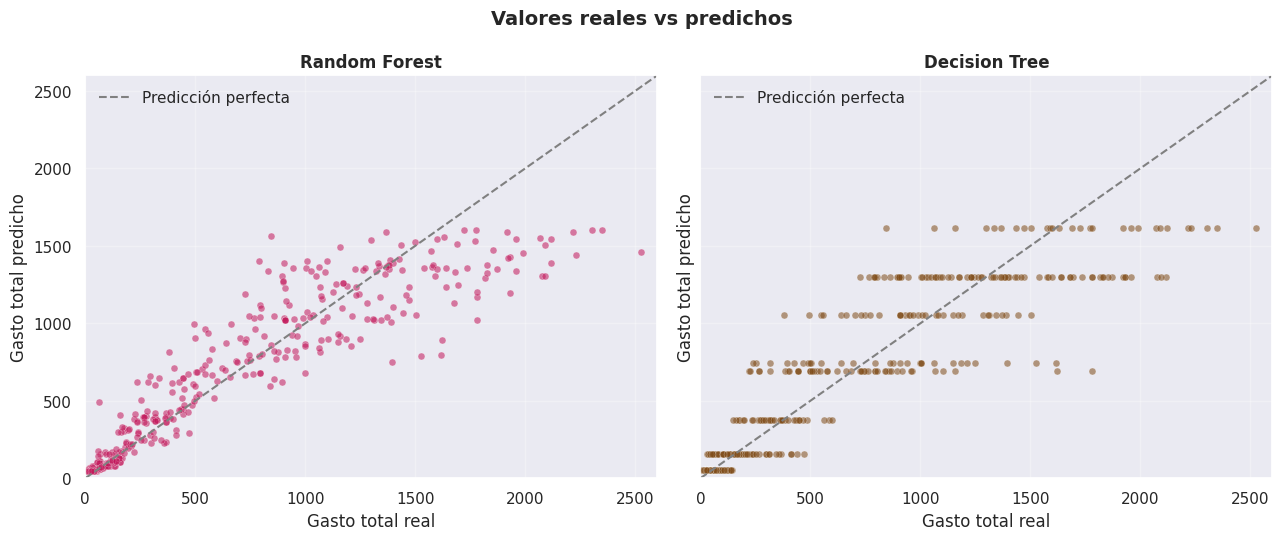

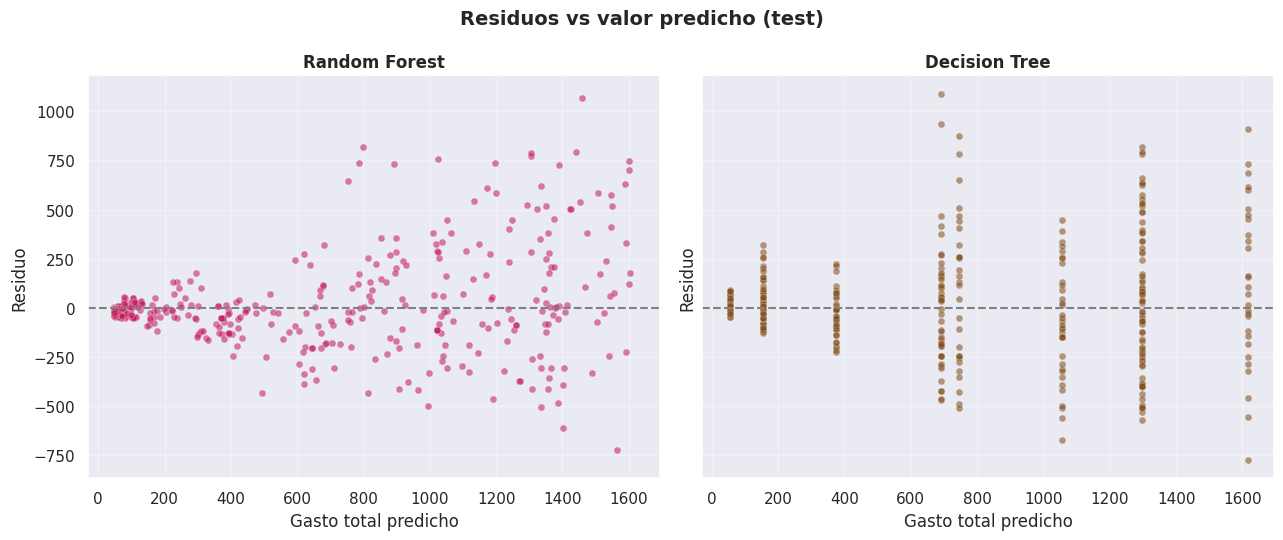

In [113]:
lim = max(y_test_reg.max(), max(p.max() for p in pred_test.values())) * 1.03
fig, axes = plt.subplots(1, 2, figsize=(13, 5.5), sharex=True, sharey=True)
for ax, n in zip(axes, nombres):
    p = pred_test[n]
    ax.scatter(y_test_reg, p, s=25, alpha=0.55, color=colores[n], edgecolor='white', linewidth=0.3)
    ax.plot([0, lim], [0, lim], color='grey', ls='--', label='Predicción perfecta')
    ax.set_xlim(0, lim); ax.set_ylim(0, lim)
    ax.set_xlabel('Gasto total real'); ax.set_ylabel('Gasto total predicho')
    ax.set_title(f'{n}', weight='bold')
    ax.grid(alpha=0.3); ax.legend(frameon=False, loc='upper left')
plt.suptitle('Valores reales vs predichos', fontsize=14, weight='bold')
plt.tight_layout()
plt.savefig("reg_02_real_vs_predicho.png", dpi=200, bbox_inches="tight")
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(13, 5.5), sharex=True, sharey=True)
for ax, n in zip(axes, nombres):
    p = pred_test[n]
    ax.scatter(p, y_test_reg - p, s=25, alpha=0.55, color=colores[n], edgecolor='white', linewidth=0.3)
    ax.axhline(0, color='grey', ls='--')
    ax.set_xlabel('Gasto total predicho'); ax.set_ylabel('Residuo')
    ax.set_title(n, weight='bold'); ax.grid(alpha=0.3)
plt.suptitle('Residuos vs valor predicho (test)', fontsize=14, weight='bold')
plt.tight_layout()
plt.savefig("reg_03_residuos_vs_predicho.png", dpi=200, bbox_inches="tight")
plt.show()


### 11.5.3 Distribución de los residuos y error por nivel de gasto


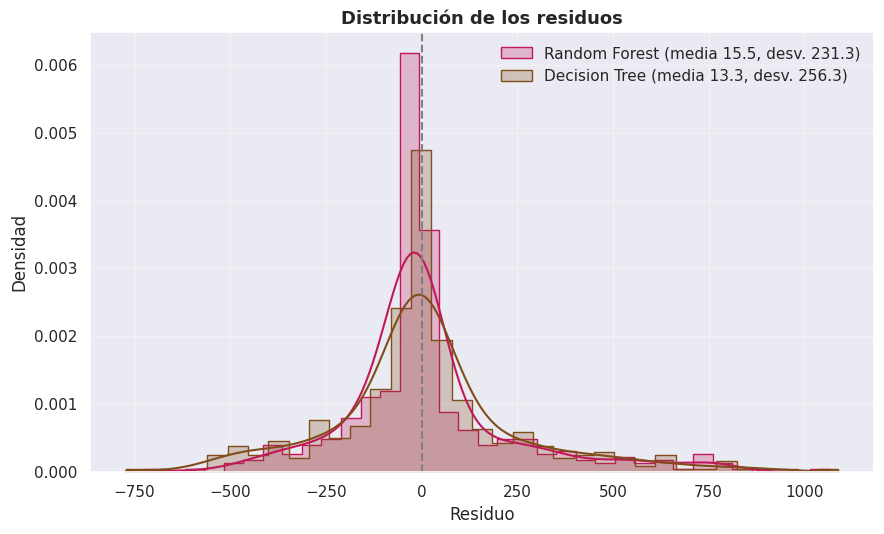

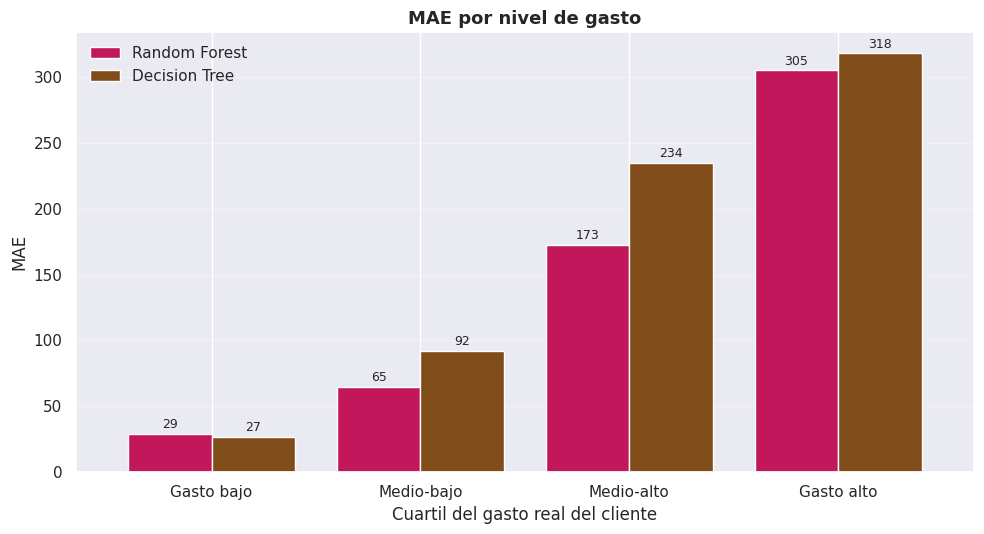

In [114]:
plt.figure(figsize=(9, 5.5))
for n in nombres:
    res = y_test_reg - pred_test[n]
    sns.histplot(res, bins=35, kde=True, stat='density', element='step', alpha=0.25,
                 color=colores[n], label=f'{n} (media {res.mean():.1f}, desv. {res.std():.1f})')
plt.axvline(0, color='grey', ls='--')
plt.xlabel('Residuo'); plt.ylabel('Densidad')
plt.title('Distribución de los residuos', fontsize=13, weight='bold')
plt.legend(frameon=False); plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("reg_04_distribucion_residuos.png", dpi=200, bbox_inches="tight")
plt.show()

niveles = pd.qcut(y_test_reg, q=4, labels=['Gasto bajo', 'Medio-bajo', 'Medio-alto', 'Gasto alto'])
mae_nivel = pd.DataFrame({n: (y_test_reg - pred_test[n]).abs().groupby(niveles, observed=True).mean()
                          for n in nombres})
ax = mae_nivel.plot(kind='bar', figsize=(10, 5.5), width=0.8, color=[colores[n] for n in nombres], edgecolor='white')
for c in ax.containers:
    ax.bar_label(c, fmt='%.0f', padding=2, fontsize=9)
ax.set_xlabel('Cuartil del gasto real del cliente'); ax.set_ylabel('MAE')
ax.set_title('MAE por nivel de gasto', fontsize=13, weight='bold')
plt.xticks(rotation=0); ax.grid(axis='y', alpha=0.3); ax.legend(frameon=False)
plt.tight_layout()
plt.savefig("reg_05_mae_por_nivel_gasto.png", dpi=200, bbox_inches="tight")
plt.show()


### 11.5.4 Errores absolutos


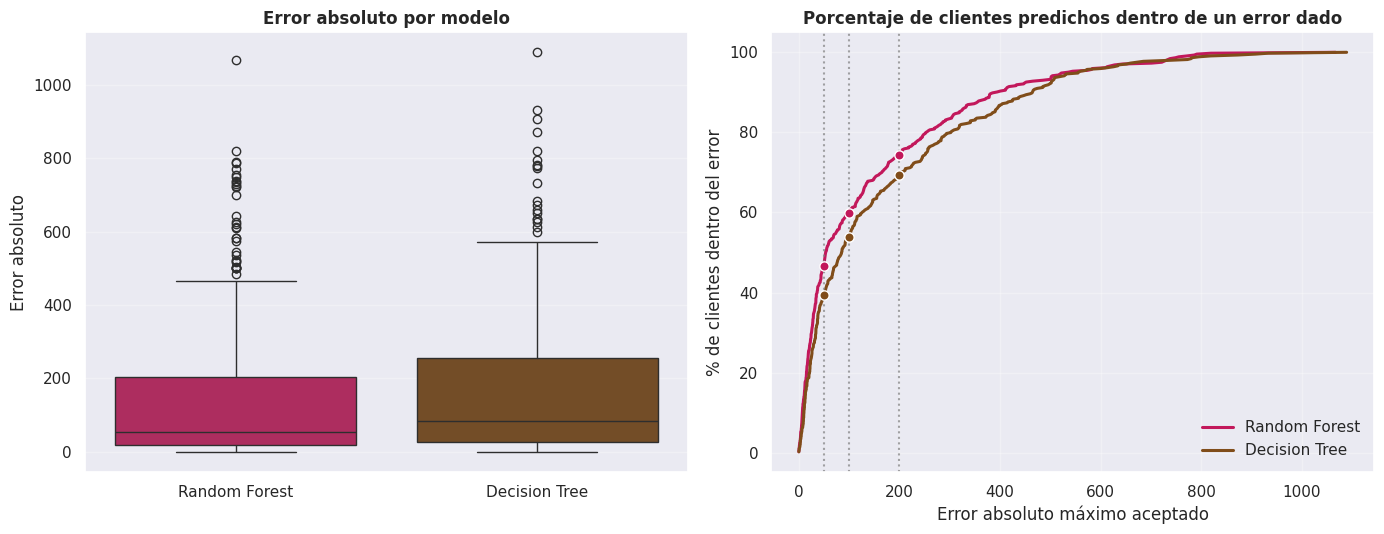

Random Forest {50: '46.6%', 100: '59.9%', 200: '74.3%'}
Decision Tree {50: '39.4%', 100: '53.8%', 200: '69.4%'}


In [115]:
err_abs = pd.DataFrame({n: (y_test_reg - pred_test[n]).abs().values for n in nombres})

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
sns.boxplot(data=err_abs, palette=[colores[n] for n in nombres], ax=axes[0])
axes[0].set_ylabel('Error absoluto'); axes[0].set_title('Error absoluto por modelo', weight='bold')
axes[0].grid(axis='y', alpha=0.3)

for n in nombres:
    e = np.sort(err_abs[n].values)
    axes[1].plot(e, np.arange(1, len(e) + 1) / len(e) * 100, lw=2.2, color=colores[n], label=n)
for umbral in (50, 100, 200):
    axes[1].axvline(umbral, color='grey', ls=':', alpha=0.7)
    for n in nombres:
        pct = (err_abs[n] <= umbral).mean() * 100
        axes[1].scatter(umbral, pct, s=45, color=colores[n], edgecolor='white', zorder=3)
axes[1].set_xlabel('Error absoluto máximo aceptado'); axes[1].set_ylabel('% de clientes dentro del error')
axes[1].set_title('Porcentaje de clientes predichos dentro de un error dado', weight='bold')
axes[1].legend(frameon=False, loc='lower right'); axes[1].grid(alpha=0.3)
plt.tight_layout()
plt.savefig("reg_06_07_errores_absolutos.png", dpi=200, bbox_inches="tight")
plt.show()

for n in nombres:
    print(n, {u: f"{(err_abs[n] <= u).mean()*100:.1f}%" for u in (50, 100, 200)})


## 11.6 Importancia de variables y curvas de aprendizaje


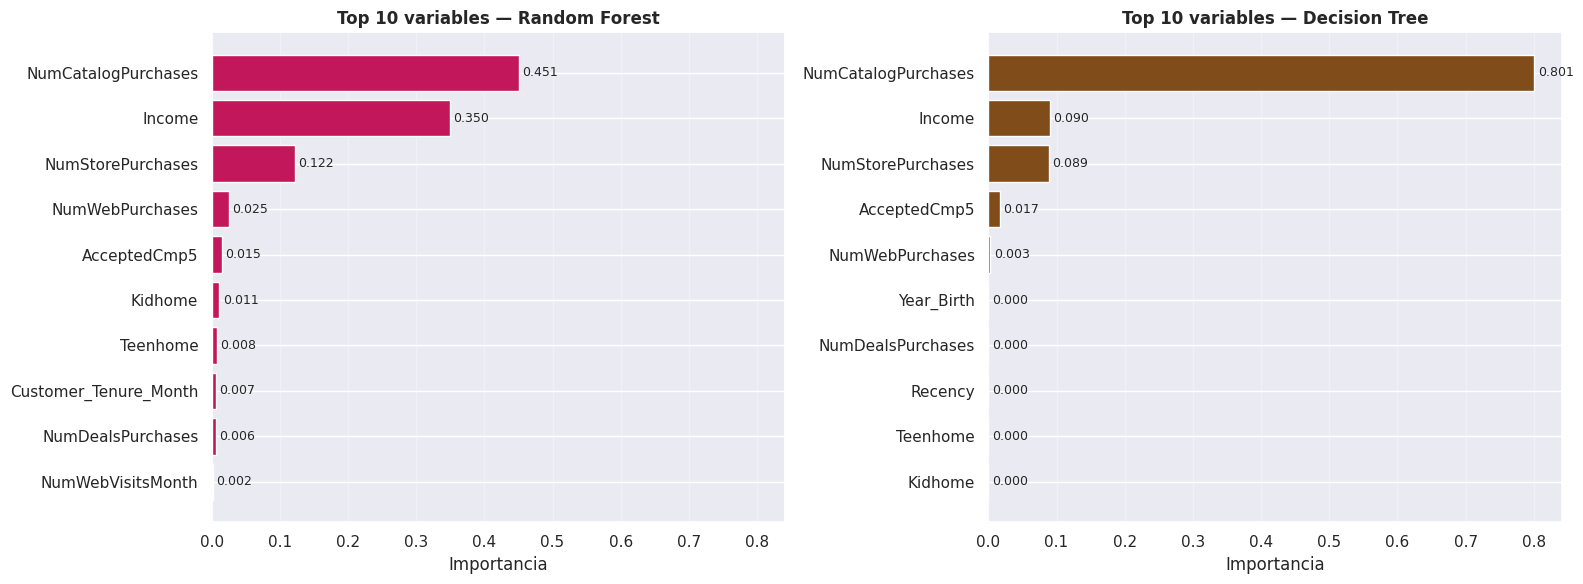

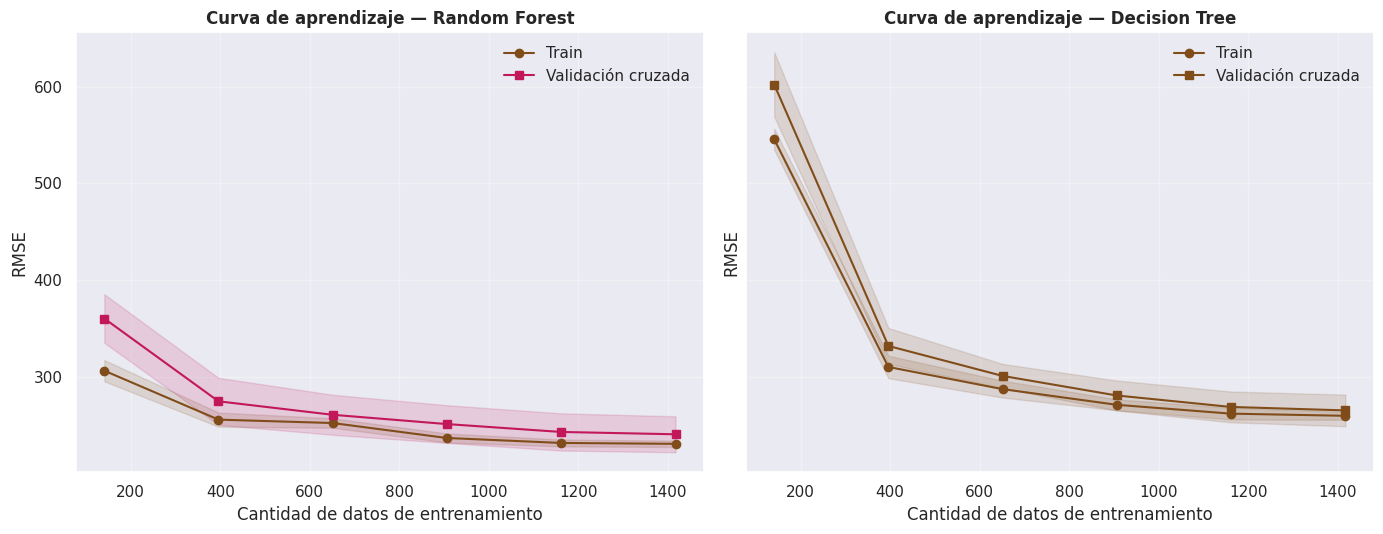

In [116]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6), sharex=True)
for ax, n in zip(axes, nombres):
    imp = pd.Series(finales[n].feature_importances_, index=X_dev_reg.columns).sort_values(ascending=False).head(10)
    ax.barh(imp.index[::-1], imp.values[::-1], color=colores[n])
    for i, v in enumerate(imp.values[::-1]):
        ax.text(v + 0.005, i, f"{v:.3f}", va='center', fontsize=9)
    ax.set_title(f'Top 10 variables — {n}', fontsize=12, weight='bold')
    ax.set_xlabel('Importancia'); ax.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.savefig("reg_08_importancia_variables.png", dpi=200, bbox_inches="tight")
plt.show()

cv_lc = KFold(n_splits=5, shuffle=True, random_state=SEED)
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5), sharey=True)
for ax, n in zip(axes, nombres):
    tam, tr, te = learning_curve(clone(mejores[n]), X_dev_reg, y_dev_reg, cv=cv_lc,
                                 scoring='neg_root_mean_squared_error',
                                 train_sizes=np.linspace(0.1, 1.0, 6), n_jobs=-2)
    tr, te = -tr, -te
    ax.plot(tam, tr.mean(axis=1), marker='o', color=cafe_palette_1[1], label='Train')
    ax.fill_between(tam, tr.mean(axis=1) - tr.std(axis=1), tr.mean(axis=1) + tr.std(axis=1), alpha=0.15, color=cafe_palette_1[1])
    ax.plot(tam, te.mean(axis=1), marker='s', color=colores[n], label='Validación cruzada')
    ax.fill_between(tam, te.mean(axis=1) - te.std(axis=1), te.mean(axis=1) + te.std(axis=1), alpha=0.15, color=colores[n])
    ax.set_xlabel('Cantidad de datos de entrenamiento'); ax.set_ylabel('RMSE')
    ax.set_title(f'Curva de aprendizaje — {n}', weight='bold'); ax.grid(alpha=0.3); ax.legend(frameon=False)
plt.tight_layout()
plt.savefig("reg_09_curvas_aprendizaje.png", dpi=200, bbox_inches="tight")
plt.show()


## 11.7 Estructura del árbol de decisión


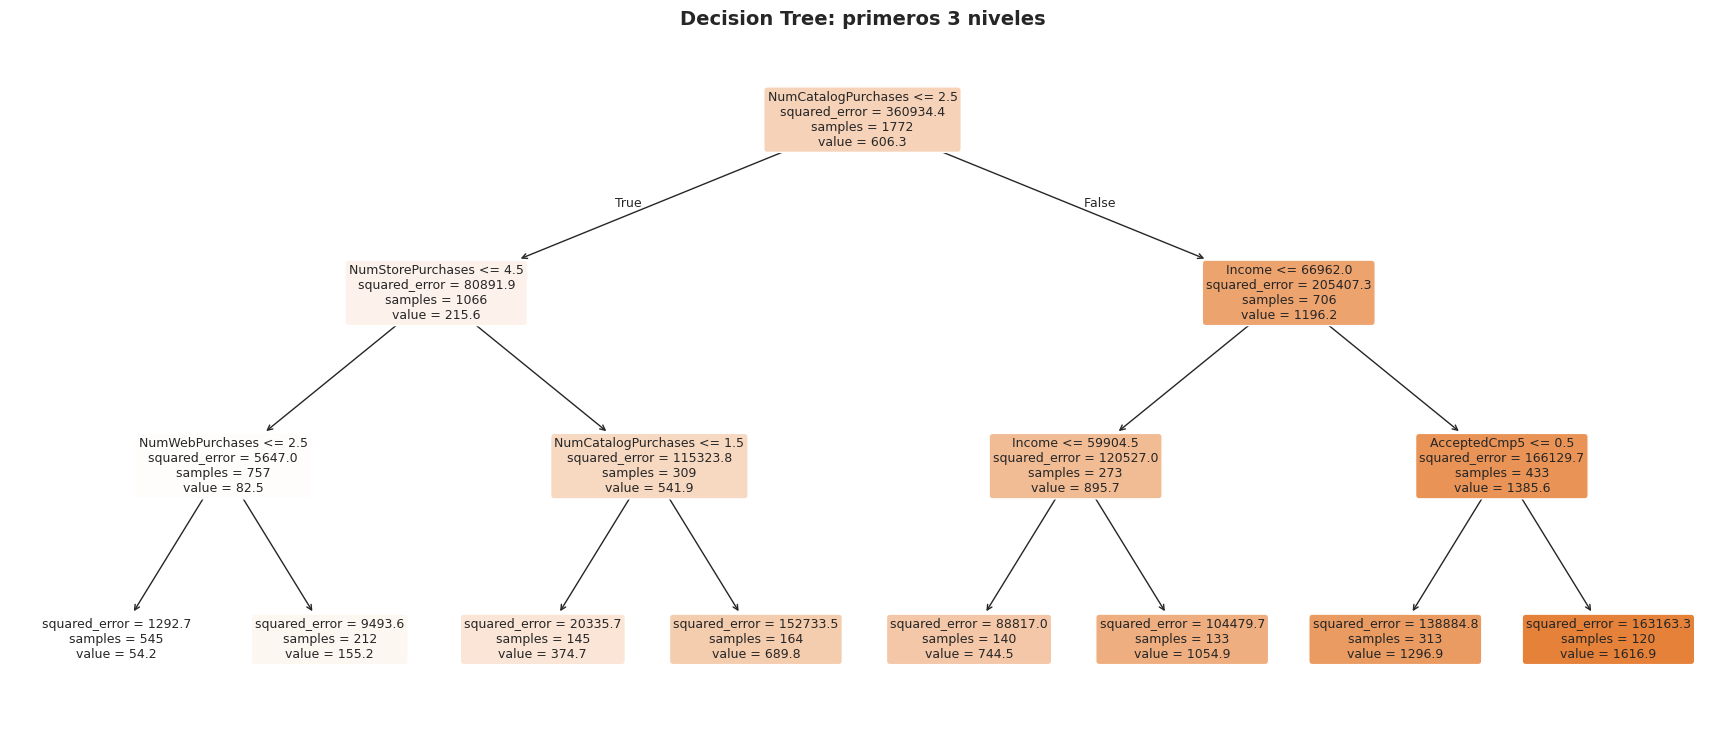

In [96]:
plt.figure(figsize=(22, 9))
plot_tree(finales['Decision Tree'], max_depth=3, feature_names=X_dev_reg.columns, filled=True,
          rounded=True, fontsize=9, precision=1)
plt.title('Decision Tree: primeros 3 niveles', fontsize=14, weight='bold')
plt.savefig("reg_10_arbol_decision.png", dpi=200, bbox_inches="tight")
plt.show()
